# Single Cell-Level Deconvolution

*Author: [Andrew Causer](https://agc888.github.io/OspreyAI)*

This notebook demonstrates some how to perform single cell-level pixel deconvolution using *goatpy*.

For more infomation on how to run general analysis using *goatpy* please visit the [Getting Started](https://goatpy.readthedocs.io/en/latest/guides/getting_started.html#Loading-and-Aligning-Data) page.


## Import Packages and Data

First we must inport some of the packages required for analysis and plotting such as *goatpy*, *sopa* and *scanpy*. Also we will read our processess and aligned `.zarr` file.

In [1]:
import goatpy as gp
from spatialdata import read_zarr
import spatialdata_plot
import matplotlib.pyplot as plt
import scanpy as sc
import sopa

sdata = read_zarr("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr")
%matplotlib inline


/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: Ra

In [2]:
"""
cell_maldi_deconvolution.py

Initial sparse, non-negative Gaussian deconvolution for the user's SpatialData
object. Uses cell_adata.obsm["pixel_weights"] and maldi_adata.X.

The geometry weights are normalised per MALDI pixel. A Gaussian objective
estimates cell-level values while regularising cells toward morphology-group
profiles. This is a first benchmark, not ground-truth intracellular quantification.

Dependencies:
    numpy, scipy, pandas, scikit-learn, anndata (via SpatialData)
"""

from __future__ import annotations

import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from scipy.sparse.linalg import eigsh


def _dense_float32(X):
    """Convert AnnData matrix or sparse matrix to dense float32."""
    if sp.issparse(X):
        return X.toarray().astype(np.float32, copy=False)
    return np.asarray(X, dtype=np.float32)


def build_pixel_cell_matrix(
    sdata,
    cell_key="cell_adata",
    maldi_key="maldi_adata",
    normalise_per_pixel=True,
    eps=1e-12,
):
    """
    Return A (pixels x cells), MALDI Y (pixels x features), and aligned IDs.

    Assumes pixel_weights rows follow cell_adata.obs and columns follow
    maldi_adata.obs, as indicated by the supplied dimensions and pixel_ids.
    """
    cells = sdata.tables[cell_key]
    maldi = sdata.tables[maldi_key]

    W = cells.obsm["pixel_weights"]
    if not sp.issparse(W):
        W = sp.csr_matrix(W)
    W = W.tocsr().astype(np.float32)

    if W.shape != (cells.n_obs, maldi.n_obs):
        raise ValueError(
            f"pixel_weights shape {W.shape} does not match "
            f"(n_cells, n_pixels)=({cells.n_obs}, {maldi.n_obs})."
        )

    # Transpose to pixel x cell for the forward model Y ~= A @ X.
    A = W.T.tocsr()

    if normalise_per_pixel:
        colsum = np.asarray(A.sum(axis=1)).ravel()
        inv = np.zeros_like(colsum, dtype=np.float32)
        valid = colsum > eps
        inv[valid] = 1.0 / colsum[valid]
        A = sp.diags(inv) @ A
        A = A.tocsr()

    Y = _dense_float32(maldi.X)

    # Keep this ordering explicit. pixel_ids should correspond to MALDI rows.
    pixel_ids = np.asarray(cells.uns.get("pixel_ids", maldi.obs_names))
    if len(pixel_ids) != maldi.n_obs:
        warnings.warn(
            "pixel_ids length differs from MALDI n_obs; using maldi.obs_names."
        )
        pixel_ids = np.asarray(maldi.obs_names)

    return A, Y, pixel_ids


def extract_cell_morphology(
    sdata,
    cells_key="cell_segmentation",
    cell_table_key="cell_adata",
):
    """
    Extract simple shape features, aligned to cell_adata row order.

    Uses geometry from sdata.shapes and cell table index/obs_names to align.
    If shape and table ordering are already identical, this is straightforward.
    """
    shapes = sdata.shapes[cells_key]
    adata = sdata.tables[cell_table_key]

    # Align shapes by index where possible.
    if shapes.index.is_unique and adata.obs_names.is_unique:
        shapes = shapes.reindex(adata.obs_names)
    else:
        if len(shapes) != adata.n_obs:
            raise ValueError("Cannot align shape rows with cell_adata.")

    feats = pd.DataFrame(index=adata.obs_names)
    geom = shapes.geometry

    feats["area"] = geom.area.astype(float)
    feats["perimeter"] = geom.length.astype(float)
    feats["circularity"] = (
        4.0 * np.pi * feats["area"] /
        (feats["perimeter"].pow(2) + 1e-8)
    )

    # Bounding-box aspect ratio and convex-hull solidity.
    aspect = []
    solidity = []
    for g in geom:
        if g is None or g.is_empty:
            aspect.append(np.nan)
            solidity.append(np.nan)
            continue
        minx, miny, maxx, maxy = g.bounds
        dx = max(maxx - minx, 1e-8)
        dy = max(maxy - miny, 1e-8)
        aspect.append(max(dx, dy) / min(dx, dy))
        hull_area = g.convex_hull.area
        solidity.append(g.area / hull_area if hull_area > 0 else np.nan)

    feats["aspect_ratio"] = aspect
    feats["solidity"] = solidity

    feats = feats.replace([np.inf, -np.inf], np.nan)
    feats = feats.fillna(feats.median(numeric_only=True))
    feats = feats.fillna(0.0)

    return feats.astype(np.float32)


def make_morphology_groups(
    morphology,
    n_groups=20,
    n_pcs=8,
    random_state=42,
):
    """
    Scale morphology descriptors, PCA, then MiniBatchKMeans.

    Returns:
        embeddings: cell x PCA dimensions
        groups: integer group label per cell
    """
    X = morphology.to_numpy(dtype=np.float32)
    Xs = StandardScaler().fit_transform(X)

    n_pcs = max(1, min(n_pcs, Xs.shape[1], Xs.shape[0] - 1))
    embeddings = PCA(
        n_components=n_pcs,
        random_state=random_state,
    ).fit_transform(Xs).astype(np.float32)

    n_groups = max(2, min(n_groups, embeddings.shape[0]))
    groups = MiniBatchKMeans(
        n_clusters=n_groups,
        random_state=random_state,
        batch_size=4096,
        n_init=3,
    ).fit_predict(embeddings)

    return embeddings, groups


def area_weighted_baseline(A, Y):
    """
    Sparse weighted-average baseline.

    For each cell/metabolite, averages intensities from pixels overlapping
    the cell, weighted by A. It does not enforce pixel reconstruction.
    """
    numerator = A.T @ Y
    denom = np.asarray(A.sum(axis=0)).ravel().astype(np.float32)
    return np.asarray(numerator) / (denom[:, None] + 1e-8)


def group_morphology_prior(A, Y, groups):
    """
    Construct a group-level prior from observed pixel intensities.

    For each group, estimate a profile using the MALDI pixels touched by
    cells in that group. Then assign that profile as the prior for each
    member cell. This is intentionally simple for the first benchmark.
    """
    n_cells = A.shape[1]
    n_features = Y.shape[1]
    prior = np.zeros((n_cells, n_features), dtype=np.float32)

    for group in np.unique(groups):
        idx = np.flatnonzero(groups == group)
        # Pixels with any contribution from cells in this group.
        group_pixel_mass = np.asarray(A[:, idx].sum(axis=1)).ravel()
        pix = group_pixel_mass > 0
        if not np.any(pix):
            continue

        # Weighted pixel average, not a cell-level ground truth.
        weights = group_pixel_mass[pix]
        profile = (weights[:, None] * Y[pix]).sum(axis=0) / (
            weights.sum() + 1e-8
        )
        prior[idx] = profile.astype(np.float32)

    return prior


def _estimate_lipschitz(A, lambda_prior, lambda_ridge, n_iter=20):
    """Power iteration for largest eigenvalue of A.T @ A."""
    n = A.shape[1]
    v = np.ones(n, dtype=np.float32)
    v /= np.linalg.norm(v) + 1e-12

    for _ in range(n_iter):
        v_new = A.T @ (A @ v)
        norm = np.linalg.norm(v_new)
        if norm < 1e-12:
            return lambda_prior + lambda_ridge + 1e-6
        v = np.asarray(v_new).ravel() / norm

    Av = A @ v
    eig = float(np.dot(Av, Av))
    return eig + lambda_prior + lambda_ridge + 1e-6


def gaussian_nonnegative_deconvolution(
    A,
    Y,
    X_prior,
    lambda_prior=0.1,
    lambda_ridge=1e-5,
    max_iter=100,
    tol=1e-4,
    feature_batch_size=8,
):
    r"""
    Solve each feature using projected gradient descent:

        min_{x >= 0} 0.5 ||A x - y||_2^2
                     + 0.5 lambda_prior ||x - x_prior||_2^2
                     + 0.5 lambda_ridge ||x||_2^2

    Gaussian/squared-error observation model, with a morphology prior.
    Returns X (cells x features). A and Y are not modified.
    """
    Y = np.asarray(Y, dtype=np.float32)
    X_prior = np.asarray(X_prior, dtype=np.float32)

    if X_prior.shape != (A.shape[1], Y.shape[1]):
        raise ValueError("X_prior must have shape (n_cells, n_features).")

    L = _estimate_lipschitz(A, lambda_prior, lambda_ridge)
    step = 1.0 / L
    X = np.zeros_like(X_prior)

    for start in range(0, Y.shape[1], feature_batch_size):
        stop = min(start + feature_batch_size, Y.shape[1])

        for m in range(start, stop):
            y = Y[:, m]
            prior = X_prior[:, m]
            x = np.maximum(prior.copy(), 0.0)

            for _ in range(max_iter):
                grad = (
                    A.T @ (A @ x - y)
                    + lambda_prior * (x - prior)
                    + lambda_ridge * x
                )
                x_new = np.maximum(x - step * grad, 0.0)

                change = np.linalg.norm(x_new - x) / (
                    np.linalg.norm(x) + 1e-8
                )
                x = x_new

                if change < tol:
                    break

            X[:, m] = x

    return X


def reconstruction_metrics(A, Y, X):
    """Return reconstruction and aggregate diagnostics."""
    Yhat = np.asarray(A @ X, dtype=np.float32)
    residual = Y - Yhat

    rmse = float(np.sqrt(np.mean(residual ** 2)))
    relative_error = float(
        np.linalg.norm(residual) / (np.linalg.norm(Y) + 1e-8)
    )

    # Per-feature RMSE, useful to identify features with poor fit.
    feature_rmse = np.sqrt(np.mean(residual ** 2, axis=0))

    return {
        "reconstructed": Yhat,
        "residuals": residual,
        "rmse": rmse,
        "relative_error": relative_error,
        "feature_rmse": feature_rmse,
    }


def run_first_benchmark(
    sdata,
    n_groups=20,
    n_pcs=8,
    lambda_prior=0.1,
    max_iter=100,
):
    """
    Run the initial benchmark and return outputs/metrics.

    This is the recommended first test. For a large full dataset, monitor
    memory: Y and X are each dense float32 arrays.
    """
    A, Y, pixel_ids = build_pixel_cell_matrix(sdata)

    morphology = extract_cell_morphology(sdata)
    embeddings, groups = make_morphology_groups(
        morphology,
        n_groups=n_groups,
        n_pcs=n_pcs,
    )

    print("A (pixels x cells):", A.shape)
    print("A nonzeros:", A.nnz)
    print("Y (pixels x features):", Y.shape)
    print("Morphology groups:", len(np.unique(groups)))

    X_area = area_weighted_baseline(A, Y)
    X_prior = group_morphology_prior(A, Y, groups)

    X_deconv = gaussian_nonnegative_deconvolution(
        A,
        Y,
        X_prior,
        lambda_prior=lambda_prior,
        max_iter=max_iter,
    )

    results = {
        "A": A,
        "Y": Y,
        "pixel_ids": pixel_ids,
        "morphology": morphology,
        "embeddings": embeddings,
        "groups": groups,
        "X_area": X_area,
        "X_prior": X_prior,
        "X_deconv": X_deconv,
    }

    print("\nReconstruction diagnostics")
    for name, X in [
        ("area baseline", X_area),
        ("morphology prior", X_prior),
        ("morphology deconvolution", X_deconv),
    ]:
        metrics = reconstruction_metrics(A, Y, X)
        print(
            f"{name:28s} "
            f"RMSE={metrics['rmse']:.6g}  "
            f"relative error={metrics['relative_error']:.6g}"
        )

    return results


In [2]:
"""
cell_maldi_deconvolution.py

Standalone sparse, non-negative deconvolution of MALDI pixels into single-cell
m/z intensities for a SpatialData object. It does NOT need `pixels_to_cells`
or any pre-built cell table.

One-line usage
--------------
    from cell_maldi_deconvolution import deconvolve_maldi_to_cells

    deconvolve_maldi_to_cells(sdata, model_type="morphology_gaussian", key_added="cell_decon")
    sdata.tables["cell_decon"]          # cells x m/z, with .obsm["spatial"]

Inputs (all read from sdata)
----------------------------
    sdata.shapes[pixel_layer]       MALDI pixel footprints (polygons)
    sdata.tables[table_name]        pixel x m/z intensities annotating pixel_layer
    sdata.shapes[cell_layer]        single-cell polygons (also the ONLY source of morphology)

Steps
-----
    1. Overlay cell polygons with pixel polygons (same method as pixels_to_cells:
       geopandas intersection) -> W (cells x pixels) of overlap areas.
    2. Remove cells with no pixel overlap (and cells below `min_coverage`).
    3. A = W^T, row-normalised so each pixel's weights over cells sum to 1.
    4. Fit  Y (pixels x m/z) ~= A @ X (cells x m/z)  with the chosen model_type.

model_type
----------
    "area_weighted"        Weighted mean of overlapping pixels (closed form baseline).
    "morphology_prior"     Cells take their morphology-group profile (closed form baseline).
    "nnls"                 Non-negative least squares (ridge only), initialised from the
                           area-weighted estimate. Ill-posed when cells outnumber pixels.
    "area_gaussian"        Gaussian NNLS regularised toward the area-weighted estimate.
    "morphology_gaussian"  Gaussian NNLS regularised toward the morphology-group profile
                           (default).

This is a benchmark-grade estimator, not ground-truth intracellular quantification.

Dependencies: numpy, scipy, pandas, scikit-learn, geopandas, anndata, spatialdata
"""

from __future__ import annotations

import warnings
from typing import Dict, Iterable, Optional

import anndata as ad
import geopandas as gpd
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

MODEL_TYPES = (
    "area_weighted",
    "morphology_prior",
    "nnls",
    "area_gaussian",
    "morphology_gaussian",
)
_MORPHOLOGY_MODELS = {"morphology_prior", "morphology_gaussian"}
_OVERLAP_ARGS = {"pixel_layer", "cell_layer", "table_name", "coordinate_system", "layer", "min_coverage"}


def _check_model(model_type):
    if model_type not in MODEL_TYPES:
        raise ValueError(f"Unknown model_type {model_type!r}. Choose from {MODEL_TYPES}.")


# --------------------------------------------------------------------------- #
# Geometry: pixels x cells overlap
# --------------------------------------------------------------------------- #
def _dense_float32(X):
    if sp.issparse(X):
        return X.toarray().astype(np.float32, copy=False)
    return np.asarray(X, dtype=np.float32)


def _get_polygons(sdata, layer, coordinate_system):
    """Shapes layer as a GeoDataFrame of polygons in `coordinate_system` (index preserved)."""
    gdf = sdata.shapes[layer]
    if coordinate_system is not None:
        from spatialdata import transform

        gdf = transform(gdf, to_coordinate_system=coordinate_system)
    geom = gdf.geometry
    if (geom.geom_type == "Point").all() and "radius" in gdf.columns:  # circles -> polygons
        gdf = gdf.set_geometry(geom.buffer(gdf["radius"]))
    return gdf


def compute_pixel_overlap(
    sdata,
    *,
    pixel_layer: str = "pixels",
    cell_layer: str = "cell_segmentation",
    table_name: str = "maldi_adata",
    coordinate_system: Optional[str] = "aligned",
    layer: Optional[str] = None,
    min_coverage: float = 0.0,
    verbose: bool = True,
) -> dict:
    """
    Overlay cell polygons with MALDI pixel polygons and return everything the
    deconvolution needs. Cells with no overlap (or less than `min_coverage` of
    their area covered) are removed here.

    Pixels with non-finite intensities are excluded before the overlay, so a cell
    only counts as covered by pixels that actually have data.
    """
    # ---- intensities (pixels x m/z), from the MALDI table only -------------
    adata = sdata.tables[table_name]
    attrs = adata.uns["spatialdata_attrs"]
    region_key, instance_key = attrs["region_key"], attrs["instance_key"]

    adata_pix = adata[adata.obs[region_key] == pixel_layer]
    if adata_pix.n_obs == 0:
        raise ValueError(f"Table '{table_name}' has no rows annotating '{pixel_layer}'.")

    Y = _dense_float32(adata_pix.layers[layer] if layer is not None else adata_pix.X)
    ids = adata_pix.obs[instance_key].to_numpy()
    valid = np.isfinite(Y).all(axis=1)
    if not valid.all():
        warnings.warn(
            f"{int((~valid).sum())} pixels have NaN/inf intensities and were excluded."
        )
        Y, ids = Y[valid], ids[valid]
    var = adata_pix.var.copy()

    # ---- polygons in a common coordinate system ----------------------------
    pix = _get_polygons(sdata, pixel_layer, coordinate_system).reindex(ids)
    if pix.geometry.isna().any():
        raise ValueError("Some table rows have no matching shape in the pixel layer.")
    pix = pix.reset_index(drop=True)
    pix["pix_idx"] = np.arange(len(pix))

    cel = _get_polygons(sdata, cell_layer, coordinate_system)
    cell_ids = cel.index.to_numpy()
    if not cel.index.is_unique:
        raise ValueError(f"Index of shapes layer '{cell_layer}' is not unique.")
    cel = cel.reset_index(drop=True)
    cel["cell_idx"] = np.arange(len(cel))
    cell_area = cel.geometry.area.to_numpy()

    # ---- overlap areas -> sparse W (cells x pixels) -------------------------
    ov = gpd.overlay(
        cel[["cell_idx", "geometry"]],
        pix[["pix_idx", "geometry"]],
        how="intersection",
        keep_geom_type=True,
    )
    ov["area"] = ov.geometry.area
    ov = ov[ov["area"] > 0]

    W = sp.csr_matrix(
        (ov["area"].to_numpy(), (ov["cell_idx"].to_numpy(), ov["pix_idx"].to_numpy())),
        shape=(len(cel), len(pix)),
    )
    W.sum_duplicates()
    covered = np.asarray(W.sum(axis=1)).ravel()
    frac = np.clip(np.divide(covered, cell_area, out=np.zeros_like(covered), where=cell_area > 0), 0, 1)

    # ---- remove cells without pixel overlap ---------------------------------
    keep = (covered > 0) & (frac >= min_coverage)
    n_dropped = int((~keep).sum())
    if verbose and n_dropped:
        print(f"Removed {n_dropped}/{len(keep)} cells with no / insufficient MALDI pixel overlap.")
    if not keep.any():
        raise ValueError("No cells overlap any MALDI pixel. Check coordinate_system and layer names.")

    W = W[keep].tocsr()
    covered, frac, cell_area = covered[keep], frac[keep], cell_area[keep]
    kept_ids = cell_ids[keep]
    cells = gpd.GeoDataFrame(geometry=cel.geometry.to_numpy()[keep], index=pd.Index(kept_ids))

    # per-cell normalised weights (QC + compatibility with pixels_to_cells)
    W_norm = sp.csr_matrix(sp.diags(1.0 / covered) @ W)
    W_norm.eliminate_zeros()
    row_counts = np.diff(W_norm.indptr)
    max_w = np.maximum.reduceat(W_norm.data, W_norm.indptr[:-1])

    obs = pd.DataFrame(
        {
            "n_pixels": row_counts,
            "frac_cell_covered": frac,
            "max_pixel_weight": max_w,
            "cell_area": cell_area,
        }
    )
    obs["cell_id"] = kept_ids
    obs["region"] = cell_layer
    obs.index = obs["cell_id"].astype(str).to_numpy()

    centroids = cells.geometry.centroid
    xy = np.column_stack([centroids.x.to_numpy(), centroids.y.to_numpy()])

    return {
        "W_area": W,
        "W_norm": W_norm,
        "Y": Y,
        "pixel_ids": np.asarray(ids).astype(str),
        "cells": cells,  # kept cell polygons, same order as W rows
        "obs": obs,
        "var": var,
        "xy": xy,
        "cell_layer": cell_layer,
        "coordinate_system": coordinate_system,
        "pixel_layer": pixel_layer,
        "table_name": table_name,
        "source_layer": layer if layer is not None else "X",
    }


def _build_A(W_area, normalise_per_pixel=True, eps=1e-12):
    """A (pixels x cells) from overlap areas; optionally each pixel's weights sum to 1."""
    A = W_area.T.tocsr().astype(np.float32)
    if normalise_per_pixel:
        rowsum = np.asarray(A.sum(axis=1)).ravel()
        inv = np.zeros_like(rowsum, dtype=np.float32)
        ok = rowsum > eps
        inv[ok] = 1.0 / rowsum[ok]
        A = (sp.diags(inv) @ A).tocsr()
    return A


# --------------------------------------------------------------------------- #
# Morphology (from the cell polygons only)
# --------------------------------------------------------------------------- #
def extract_cell_morphology(cells) -> pd.DataFrame:
    """Shape features from cell polygons (GeoDataFrame/GeoSeries); one row per cell."""
    geom = cells.geometry if hasattr(cells, "geometry") else cells
    feats = pd.DataFrame(index=geom.index)
    feats["area"] = geom.area.astype(float)
    feats["perimeter"] = geom.length.astype(float)
    feats["circularity"] = 4.0 * np.pi * feats["area"] / (feats["perimeter"].pow(2) + 1e-8)

    aspect, solidity = [], []
    for g in geom:
        if g is None or g.is_empty:
            aspect.append(np.nan)
            solidity.append(np.nan)
            continue
        minx, miny, maxx, maxy = g.bounds
        dx, dy = max(maxx - minx, 1e-8), max(maxy - miny, 1e-8)
        aspect.append(max(dx, dy) / min(dx, dy))
        hull_area = g.convex_hull.area
        solidity.append(g.area / hull_area if hull_area > 0 else np.nan)
    feats["aspect_ratio"] = aspect
    feats["solidity"] = solidity

    feats = feats.replace([np.inf, -np.inf], np.nan)
    feats = feats.fillna(feats.median(numeric_only=True)).fillna(0.0)
    return feats.astype(np.float32)


def make_morphology_groups(morphology, n_groups=20, n_pcs=8, random_state=42):
    """Scale descriptors -> PCA -> MiniBatchKMeans. Returns (embeddings, groups)."""
    Xs = StandardScaler().fit_transform(morphology.to_numpy(dtype=np.float32))
    n_pcs = max(1, min(n_pcs, Xs.shape[1], Xs.shape[0] - 1))
    embeddings = PCA(n_components=n_pcs, random_state=random_state).fit_transform(Xs).astype(np.float32)
    n_groups = max(2, min(n_groups, embeddings.shape[0]))
    groups = MiniBatchKMeans(
        n_clusters=n_groups, random_state=random_state, batch_size=4096, n_init=3
    ).fit_predict(embeddings)
    return embeddings, groups


# --------------------------------------------------------------------------- #
# Estimators
# --------------------------------------------------------------------------- #
def area_weighted_baseline(A, Y):
    """Weighted mean of overlapping pixel intensities per cell (no reconstruction)."""
    numerator = A.T @ Y
    denom = np.asarray(A.sum(axis=0)).ravel().astype(np.float32)
    return np.asarray(numerator) / (denom[:, None] + 1e-8)


def group_morphology_prior(A, Y, groups):
    """Per morphology group: pixel-mass-weighted mean of Y, assigned to every member cell."""
    prior = np.zeros((A.shape[1], Y.shape[1]), dtype=np.float32)
    for group in np.unique(groups):
        idx = np.flatnonzero(groups == group)
        mass = np.asarray(A[:, idx].sum(axis=1)).ravel()
        pix = mass > 0
        if not np.any(pix):
            continue
        w = mass[pix]
        prior[idx] = ((w[:, None] * Y[pix]).sum(axis=0) / (w.sum() + 1e-8)).astype(np.float32)
    return prior


def _estimate_lipschitz(A, lambda_prior, lambda_ridge, n_iter=20, safety=1.05):
    """Power iteration for the largest eigenvalue of A.T @ A, plus penalties."""
    v = np.ones(A.shape[1], dtype=np.float32)
    v /= np.linalg.norm(v) + 1e-12
    for _ in range(n_iter):
        v_new = np.asarray(A.T @ (A @ v)).ravel()
        norm = np.linalg.norm(v_new)
        if norm < 1e-12:
            return lambda_prior + lambda_ridge + 1e-6
        v = v_new / norm
    Av = A @ v
    return safety * float(np.dot(Av, Av)) + lambda_prior + lambda_ridge + 1e-6


def gaussian_nonnegative_deconvolution(
    A,
    Y,
    X_prior=None,
    X_init=None,
    lambda_prior=0.1,
    lambda_ridge=1e-5,
    max_iter=100,
    tol=1e-4,
    feature_batch_size=64,
):
    r"""
    Projected gradient descent, all features solved in column batches:

        min_{x >= 0}  0.5 ||A x - y||^2 + 0.5 lambda_prior ||x - x_prior||^2
                      + 0.5 lambda_ridge ||x||^2

    X_prior=None disables the prior term. X_init defaults to X_prior (or zeros).
    Features that converge are frozen while the rest of the batch continues.
    """
    Y = np.asarray(Y, dtype=np.float32)
    n_cells, n_features = A.shape[1], Y.shape[1]

    if X_prior is None:
        lambda_prior = 0.0
    else:
        X_prior = np.asarray(X_prior, dtype=np.float32)
        if X_prior.shape != (n_cells, n_features):
            raise ValueError("X_prior must have shape (n_cells, n_features).")
    if X_init is None:
        X_init = X_prior if X_prior is not None else np.zeros((n_cells, n_features), np.float32)

    At = A.T.tocsr()
    step = 1.0 / _estimate_lipschitz(A, lambda_prior, lambda_ridge)
    X = np.zeros((n_cells, n_features), dtype=np.float32)

    for start in range(0, n_features, feature_batch_size):
        sl = slice(start, min(start + feature_batch_size, n_features))
        Yb = Y[:, sl]
        Pb = X_prior[:, sl] if X_prior is not None else None
        x = np.maximum(np.asarray(X_init[:, sl], dtype=np.float32), 0.0)
        active = np.arange(x.shape[1])

        for _ in range(max_iter):
            xa = x[:, active]
            grad = At @ (A @ xa - Yb[:, active]) + lambda_ridge * xa
            if Pb is not None:
                grad = grad + lambda_prior * (xa - Pb[:, active])
            x_new = np.maximum(xa - step * grad, 0.0)
            change = np.linalg.norm(x_new - xa, axis=0) / (np.linalg.norm(xa, axis=0) + 1e-8)
            x[:, active] = x_new
            active = active[change >= tol]
            if active.size == 0:
                break
        X[:, sl] = x
    return X


def reconstruction_metrics(A, Y, X):
    """Reconstruction diagnostics for Y ~= A @ X."""
    Yhat = np.asarray(A @ X, dtype=np.float32)
    residual = Y - Yhat
    return {
        "reconstructed": Yhat,
        "residuals": residual,
        "rmse": float(np.sqrt(np.mean(residual**2))),
        "relative_error": float(np.linalg.norm(residual) / (np.linalg.norm(Y) + 1e-8)),
        "feature_rmse": np.sqrt(np.mean(residual**2, axis=0)),
    }


# --------------------------------------------------------------------------- #
# Fit, package, register
# --------------------------------------------------------------------------- #
def _fit_and_package(
    prep: dict,
    model_type: str,
    *,
    n_groups=20,
    n_pcs=8,
    lambda_prior=0.1,
    lambda_ridge=1e-5,
    max_iter=100,
    tol=1e-4,
    feature_batch_size=64,
    normalise_per_pixel=True,
    compute_metrics=True,
    random_state=42,
    verbose=True,
) -> ad.AnnData:
    _check_model(model_type)
    A, Y = _build_A(prep["W_area"], normalise_per_pixel), prep["Y"]
    if verbose:
        print(f"[{model_type}] A {A.shape} (nnz={A.nnz}), Y {Y.shape}")

    groups = None
    if model_type in _MORPHOLOGY_MODELS:
        morphology = extract_cell_morphology(prep["cells"])
        _, groups = make_morphology_groups(morphology, n_groups, n_pcs, random_state)
        if verbose:
            print(f"[{model_type}] morphology groups: {len(np.unique(groups))}")

    kw = dict(lambda_ridge=lambda_ridge, max_iter=max_iter, tol=tol, feature_batch_size=feature_batch_size)
    if model_type == "area_weighted":
        X = area_weighted_baseline(A, Y)
    elif model_type == "morphology_prior":
        X = group_morphology_prior(A, Y, groups)
    elif model_type == "nnls":
        X = gaussian_nonnegative_deconvolution(A, Y, None, area_weighted_baseline(A, Y), **kw)
    elif model_type == "area_gaussian":
        X = gaussian_nonnegative_deconvolution(
            A, Y, area_weighted_baseline(A, Y), lambda_prior=lambda_prior, **kw
        )
    else:  # morphology_gaussian
        X = gaussian_nonnegative_deconvolution(
            A, Y, group_morphology_prior(A, Y, groups), lambda_prior=lambda_prior, **kw
        )

    out = ad.AnnData(X=np.asarray(X, dtype=np.float32), obs=prep["obs"].copy(), var=prep["var"].copy())
    if groups is not None:
        out.obs["morphology_group"] = pd.Categorical(groups)

    out.obsm["spatial"] = prep["xy"]  # cell centroids, for sq.pl.spatial_scatter / sc.pl.spatial
    out.obsm["pixel_weights"] = prep["W_norm"]  # per-cell normalised, as in pixels_to_cells
    out.obsm["pixel_overlap_area"] = prep["W_area"]  # raw overlap areas
    out.uns["pixel_ids"] = prep["pixel_ids"]
    out.uns["spatial_coordinate_system"] = prep["coordinate_system"] or "intrinsic"

    info = {
        "model_type": model_type,
        "pixel_layer": prep["pixel_layer"],
        "cell_layer": prep["cell_layer"],
        "source_table": prep["table_name"],
        "source_layer": prep["source_layer"],
        "coordinate_system": prep["coordinate_system"] or "intrinsic",
        "normalise_per_pixel": normalise_per_pixel,
    }
    if groups is not None:
        info.update(n_groups=n_groups, n_pcs=n_pcs)
    if "gaussian" in model_type:
        info["lambda_prior"] = lambda_prior
    if model_type in {"nnls", "area_gaussian", "morphology_gaussian"}:
        info["lambda_ridge"] = lambda_ridge
    if compute_metrics:
        m = reconstruction_metrics(A, Y, X)
        info.update(rmse=m["rmse"], relative_error=m["relative_error"])
        out.var["pixel_rmse"] = m["feature_rmse"]
        if verbose:
            print(f"[{model_type}] RMSE={m['rmse']:.6g}  relative error={m['relative_error']:.6g}")
    out.uns["deconvolution"] = info  # no None values, so it can be written to zarr
    return out


def _register(sdata, out, key_added, cell_layer, overwrite):
    from spatialdata.models import TableModel

    if key_added in sdata.tables and not overwrite:
        raise ValueError(f"Table '{key_added}' already exists. Use overwrite=True.")
    out = TableModel.parse(out, region=cell_layer, region_key="region", instance_key="cell_id")
    if key_added in sdata.tables:
        del sdata.tables[key_added]
    sdata.tables[key_added] = out
    if sdata.is_backed():
        sdata.write_element(key_added, overwrite=True)
    return out


# --------------------------------------------------------------------------- #
# Single entry point
# --------------------------------------------------------------------------- #
def deconvolve_maldi_to_cells(
    sdata,
    model_type: str = "morphology_gaussian",
    key_added: str = "cell_decon",
    *,
    pixel_layer: str = "pixels",
    cell_layer: str = "cell_segmentation",
    table_name: str = "maldi_adata",
    coordinate_system: Optional[str] = "aligned",
    layer: Optional[str] = None,
    min_coverage: float = 0.0,
    n_groups: int = 20,
    n_pcs: int = 8,
    lambda_prior: float = 0.1,
    lambda_ridge: float = 1e-5,
    max_iter: int = 100,
    tol: float = 1e-4,
    feature_batch_size: int = 64,
    normalise_per_pixel: bool = True,
    compute_metrics: bool = True,
    random_state: int = 42,
    overwrite: bool = False,
    inplace: bool = True,
    verbose: bool = True,
) -> ad.AnnData:
    """
    Impute MALDI m/z intensities to single cells. Independent of `pixels_to_cells`.

    Parameters
    ----------
    sdata : SpatialData
    model_type : one of MODEL_TYPES (see module docstring).
    key_added : name of the table the result is saved as (``sdata.tables[key_added]``).
    pixel_layer, cell_layer : shapes layers with MALDI pixel / single-cell polygons.
        ``cell_layer`` is also the only source of morphology.
    table_name : table with the pixel x m/z intensities annotating ``pixel_layer``.
    coordinate_system : overlaps and morphology are computed here (None = intrinsic).
    layer : table layer to use as intensities (default ``.X``; use a normalised layer).
    min_coverage : also remove cells with less than this fraction of area on pixels
        (cells with no overlap are always removed).
    overwrite : replace ``key_added`` if it exists.
    inplace : add the table to ``sdata``; the AnnData is always returned.

    Returns
    -------
    AnnData (cells x m/z), cells with pixel overlap only.
      .obsm["spatial"]           cell centroids in ``coordinate_system``
      .obsm["pixel_weights"]     per-cell normalised overlap (as pixels_to_cells)
      .obsm["pixel_overlap_area"] raw cell-pixel overlap areas
      .obs                       n_pixels, frac_cell_covered, max_pixel_weight,
                                 cell_area, cell_id, region, morphology_group*
      .var["pixel_rmse"]         per-feature reconstruction RMSE
      .uns["deconvolution"]      model_type, parameters, rmse, relative_error
    """
    _check_model(model_type)
    if inplace and key_added in sdata.tables and not overwrite:
        raise ValueError(f"Table '{key_added}' already exists. Use overwrite=True.")

    prep = compute_pixel_overlap(
        sdata,
        pixel_layer=pixel_layer,
        cell_layer=cell_layer,
        table_name=table_name,
        coordinate_system=coordinate_system,
        layer=layer,
        min_coverage=min_coverage,
        verbose=verbose,
    )
    out = _fit_and_package(
        prep,
        model_type,
        n_groups=n_groups,
        n_pcs=n_pcs,
        lambda_prior=lambda_prior,
        lambda_ridge=lambda_ridge,
        max_iter=max_iter,
        tol=tol,
        feature_batch_size=feature_batch_size,
        normalise_per_pixel=normalise_per_pixel,
        compute_metrics=compute_metrics,
        random_state=random_state,
        verbose=verbose,
    )
    if inplace:
        out = _register(sdata, out, key_added, cell_layer, overwrite)
    return out


def compare_models(
    sdata,
    model_types: Iterable[str] = MODEL_TYPES,
    key_prefix: Optional[str] = None,
    overwrite: bool = False,
    **kwargs,
) -> tuple[Dict[str, ad.AnnData], pd.DataFrame]:
    """
    Run several model_types on one shared overlap computation.

    Returns ({model_type: AnnData}, metrics DataFrame). Nothing is added to sdata
    unless key_prefix is given, in which case tables are saved as
    ``f"{key_prefix}_{model_type}"``. Accepts the same layer / coordinate_system /
    fitting keyword arguments as deconvolve_maldi_to_cells.
    """
    model_types = list(model_types)
    for m in model_types:
        _check_model(m)
    overlap_kw = {k: kwargs.pop(k) for k in list(kwargs) if k in _OVERLAP_ARGS}
    prep = compute_pixel_overlap(sdata, verbose=kwargs.get("verbose", True), **overlap_kw)

    results, rows = {}, []
    for name in model_types:
        out = _fit_and_package(prep, name, **kwargs)
        if key_prefix:
            out = _register(sdata, out, f"{key_prefix}_{name}", prep["cell_layer"], overwrite)
        results[name] = out
        d = out.uns["deconvolution"]
        rows.append({"model_type": name, "rmse": d.get("rmse"), "relative_error": d.get("relative_error")})
    return results, pd.DataFrame(rows).set_index("model_type")

In [4]:
cell_mz = deconvolve_maldi_to_cells(sdata, model_type="morphology_gaussian", coordinate_system="global")

ValueError: Table 'cell_decon' already exists. Use overwrite=True.

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans

# -------------------------------------------------------
# 1. Get deconvolved cell-level MALDI intensities
# -------------------------------------------------------
def run_decon_PCA(sdata, table_name: str = "cell_decon", n_pcs: int = 30, log_norm: bool = True, scale: bool = True, random_state: int = 42, verbose: bool = True):
    """
    Get deconvolved cell-level MALDI intensities and perform PCA + K-means clustering.

    Parameters
    ----------
    sdata : SpatialData
        The SpatialData object containing the deconvolved cell-level MALDI intensities.
    table : str, optional
        The name of the table containing the deconvolved cell-level MALDI intensities.
        Default is "cell_decon".

    Returns
    -------
    cell_adata : AnnData
        The AnnData object containing the deconvolved cell-level MALDI intensities.
    X_pca : np.ndarray
        The PCA-transformed data.
    clusters : np.ndarray
        The cluster labels assigned to each cell.
    """

    cell_adata = sdata.tables[table_name]  

    X = np.asarray(sdata.tables[table_name].X, dtype=np.float32)

    assert X.shape == (cell_adata.n_obs, len(cell_adata.var))

    # Replace invalid values and enforce non-negativity
    X = np.nan_to_num(
        X,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    X = np.maximum(X, 0)

    if verbose:
        print("Cell-level Decon matrix:", X.shape)


    # Log transformation reduces the influence of very high intensities
    X_update = X
    if log_norm:
        X_update = np.log1p(X_update)
    

    # Standardise each metabolite across cells
    if scale:
        scaler = StandardScaler()
        X_update = scaler.fit_transform(X_update)


    pca = PCA(
        n_components=n_pcs,
        random_state=random_state,
    )

    X_pca = pca.fit_transform(X_update)

    if verbose:
        print("PCA shape:", X_pca.shape)

        print(
            "Variance explained by 30 PCs:",
            pca.explained_variance_ratio_.sum()
        )

    sdata.tables[table_name].obsm["X_pca"] = X_pca

    return sdata


In [5]:
test_sdata = run_decon_PCA(sdata, table_name = "cell_decon", n_pcs = 30)

Cell-level Decon matrix: (166944, 174)
PCA shape: (166944, 30)
Variance explained by 30 PCs: 0.84921014


In [6]:
kmeans = MiniBatchKMeans(n_clusters=8,random_state=42,batch_size=4096,n_init=10,max_iter=200,)
clusters = kmeans.fit_predict(test_sdata["cell_decon"].obsm["X_pca"])
test_sdata["cell_decon"].obs["decon_cluster"] = pd.Categorical(clusters.astype(str))

In [7]:
sc.pp.neighbors(
    test_sdata["cell_decon"],
    use_rep="X_pca",
    n_neighbors=15,
    n_pcs=30
)

# Leiden clustering
sc.tl.leiden(
    test_sdata["cell_decon"],
    resolution=1.0,
    key_added="decon_leiden",
    random_state=42)

/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1918345858.py:9: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/3165859890.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sdata["cell_decon"], img_key="hires",
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/3165859890.py:7: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sdata["cell_decon"], img_key="hires",
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/3165859890.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sdata["cell_decon"], img_key="hires",


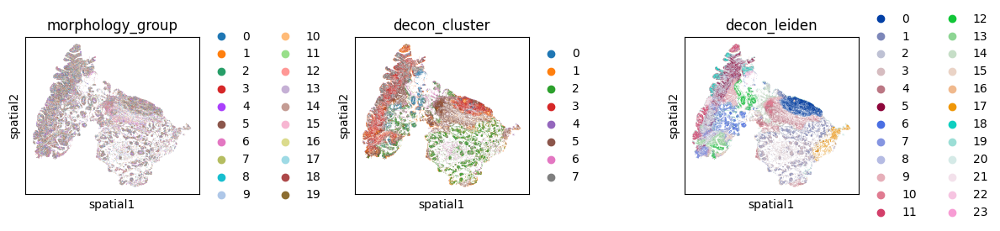

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))

sc.pl.spatial(sdata["cell_decon"], img_key="hires",
              color=["morphology_group"], size=4, spot_size=10,
              alpha_img=0, ax = ax[0], show = False)

sc.pl.spatial(sdata["cell_decon"], img_key="hires",
              color=["decon_cluster"], size=4, spot_size=10,
              alpha_img=0, ax = ax[1], show = False)

sc.pl.spatial(sdata["cell_decon"], img_key="hires",
              color=["decon_leiden"], size=4, spot_size=10,
              alpha_img=0, ax = ax[2], show = False)

plt.tight_layout()
plt.show()

In [9]:
ihc_image = gp.ihc_spatialdata("/Users/andrewcauser/Documents/Griffith/test_data/IHC_new/DM_22.05.26_Image_2_19PM0001_RedGrnChannel.tif")

Loaded image with shape: (1341, 1508, 3)
Successfully generated SpatialData object


In [ ]:
viewer,_,_, widget = gp.launch_landmark_gui(maldi_sd=sdata, 
                                        he_sd=ihc_image, 
                                        split_view=True, 
                                        maldi_image_key = "he_image", 
                                        he_image_key = "ihc_image",
                                        maldi_scale_level = "scale0")

Available MALDI scale levels:
  scale0: (3, 25800, 28350)
Available H&E scale levels:
  scale0: (3, 1341, 1508)

Launching GUI with MALDI=scale0, H&E=scale0
[LandmarkGUI] MALDI display level=scale0, scale_factor=1.000  |  H&E display level=scale0, scale_factor=1.000


Traceback (most recent call last):
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/vispy/app/backends/_qt.py", line 528, in mousePressEvent
    vispy_event = self._vispy_mouse_press(
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/vispy/app/base.py", line 183, in _vispy_mouse_press
    ev = self._vispy_canvas.events.mouse_press(**kwargs)
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/vispy/util/event.py", line 453, in __call__
    self._invoke_callback(cb, event)
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/vispy/util/event.py", line 471, in _invoke_callback
    _handle_exception(self.ignore_callback_errors,
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/vispy/util/event.py", line 469, in _invoke_callback
    cb(event)
  File "/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/napari/_vispy/canvas.py", line 6

INFO: Saved 5 landmark pairs (scaled to full resolution)


In [66]:
sdata["maldi_landmarks"].compute()

,x,y
0,4905.452279,4625.044800
1,11536.067485,6558.974235
2,22255.562067,12471.272793
3,17669.386550,19433.418758
4,11646.577738,19958.342462


In [67]:
ihc_image["he_landmarks"].compute()

,x,y
0,315.493378,261.597513
1,649.212711,384.050978
2,1179.395844,715.079026
3,934.488915,1058.217856
4,620.954219,1067.637353


In [10]:
from spatialdata.models import PointsModel
maldi_align_points = pd.DataFrame({
    "x": [4905.452279,11536.067485, 22255.562067, 17669.386550,11646.577738  ],
    "y": [4625.044800,  6558.974235, 12471.272793, 19433.418758, 19958.342462]
})

he_align_points = pd.DataFrame({
    "x": [315.493378,649.212711, 1179.395844, 934.488915, 620.954219 ],
    "y": [261.597513, 384.050978, 715.079026, 1058.217856,1067.637353 ]
})

sdata["maldi_landmarks"] = PointsModel.parse(maldi_align_points)
ihc_image["he_landmarks"] = PointsModel.parse(he_align_points)

In [11]:
aligned = gp.align_image_using_landmarks(sdata, ihc_image, maldi_image_key = "he_fullres", he_image_key = "ihc_image", he_landmark_key = "he_landmarks")

In [12]:
aligned

SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr
├── Images
│     ├── 'he_fullres': DataTree[cyx] (3, 36341, 40044), (3, 9085, 10011), (3, 2271, 2502), (3, 567, 625)
│     ├── 'he_image': DataArray[cyx] (3, 25800, 28350)
│     └── 'ihc_image': DataArray[cyx] (3, 1341, 1508)
├── Points
│     ├── 'centroids': DataFrame with shape: (<Delayed>, 3) (2D points)
│     ├── 'he_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'maldi_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
├── Shapes
│     ├── 'cell_segmentation': GeoDataFrame shape: (166953, 1) (2D shapes)
│     ├── 'pixels': GeoDataFrame shape: (267648, 2) (2D shapes)
│     └── 'region_of_interest': GeoDataFrame shape: (1, 1) (2D shapes)
└── Tables
      ├── 'cell_adata': AnnData (166942, 174)
      ├── 'cell_decon': AnnData (166944, 174)
      └── 'maldi_adata': AnnData (267648, 174)
with coordinate systems:
    ▸ 'a

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                
INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


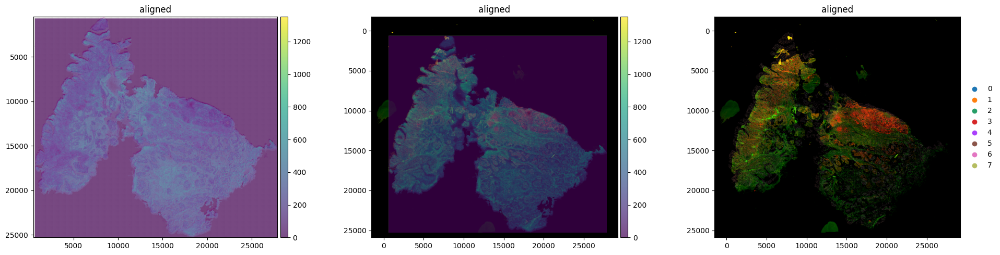

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), dpi=200)

aligned.pl.render_images("he_fullres") \
     .pl.render_shapes("pixels",size = 3,fill_alpha = 0.7,color="MPI").pl.show("aligned", ax=axes[0])

aligned.pl.render_images("ihc_image") \
     .pl.render_shapes("pixels",size = 3,fill_alpha = 0.7,color="MPI").pl.show("aligned", ax=axes[1])

aligned.pl.render_images("ihc_image") \
     .pl.render_shapes("cell_segmentation",size = 3,fill_alpha = 0.8,color="decon_cluster").pl.show("aligned", ax=axes[2])

plt.tight_layout()
plt.show()

In [14]:
"""
cell_maldi_plots.py

Visualisation for the output of `deconvolve_maldi_to_cells` (the "cell_decon" table).

    compare_morphology_clusters(sdata, ...)   morphology groups: example cells + feature heatmap
    plot_pixel_pies(sdata, color, ...)        per-pixel pie charts of any categorical .obs column
    evaluate_deconvolution(sdata, ...)        pixel-level data vs deconvolved single-cell data
    plot_model_comparison(metrics)            bar chart from compare_models() metrics

All functions take the SpatialData object and the table name (default "cell_decon").

Note: "morphology_group" is the intermediate prior used by the "morphology_*" models; it
is not a cell-type label. To get cell types, cluster the deconvolved .X (e.g. scanpy leiden)
and pass that column to plot_pixel_pies().
"""

from __future__ import annotations

import warnings
from typing import Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib import colors as mcolors
from matplotlib.collections import PatchCollection, PolyCollection
from matplotlib.patches import Patch, Wedge
from scipy.cluster.hierarchy import dendrogram, linkage



# --------------------------------------------------------------------------- #
# Shared helpers
# --------------------------------------------------------------------------- #
def _cs(info):
    cs = info.get("coordinate_system")
    return None if cs in (None, "intrinsic") else cs


def _as_categorical(adata, key):
    if key not in adata.obs:
        cats = [c for c in adata.obs.columns if not pd.api.types.is_float_dtype(adata.obs[c])]
        raise KeyError(f"'{key}' is not in .obs. Candidate columns: {cats}")
    s = adata.obs[key]
    if not isinstance(s.dtype, pd.CategoricalDtype):
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > 30:
            raise ValueError(f"'{key}' looks continuous ({s.nunique()} unique values); a categorical column is needed.")
        s = s.astype("category")
    return s.cat.remove_unused_categories()


def _category_colors(adata, key, cats):
    stored = adata.uns.get(f"{key}_colors")
    if stored is not None and len(stored) == len(cats):
        return dict(zip(cats, [mcolors.to_hex(c) for c in stored]))
    n = len(cats)
    if n <= 10:
        pal = plt.get_cmap("tab10")(np.arange(n))
    elif n <= 20:
        pal = plt.get_cmap("tab20")(np.arange(n))
    else:
        pal = plt.get_cmap("nipy_spectral")(np.linspace(0.05, 0.95, n))
    return dict(zip(cats, [mcolors.to_hex(c) for c in pal]))


def _cell_polys(sdata, adata):
    """Cell polygons in the order of adata.obs (matched by cell_id)."""
    info = adata.uns["deconvolution"]
    gdf = _get_polygons(sdata, info["cell_layer"], _cs(info))
    gdf = gdf.set_axis(gdf.index.astype(str))
    return gdf.geometry.loc[adata.obs["cell_id"].astype(str).to_numpy()]


def _pixel_polys(sdata, adata):
    """Pixel polygons in the order of adata.uns['pixel_ids'] (= rows of the pixel matrix)."""
    info = adata.uns["deconvolution"]
    gdf = _get_polygons(sdata, info["pixel_layer"], _cs(info))
    gdf = gdf.set_axis(gdf.index.astype(str))
    return gdf.geometry.loc[np.asarray(adata.uns["pixel_ids"]).astype(str)]


def _get_morphology(sdata, adata):
    if "morphology" in adata.obsm and "morphology_features" in adata.uns:
        return pd.DataFrame(
            np.asarray(adata.obsm["morphology"]),
            index=adata.obs_names,
            columns=list(adata.uns["morphology_features"]),
        )
    # Tables made before morphology was stored: recompute from the polygons.
    morph = extract_cell_morphology(_cell_polys(sdata, adata))
    morph.index = adata.obs_names
    return morph


def _parts(geom):
    for p in (geom.geoms if hasattr(geom, "geoms") else [geom]):
        if hasattr(p, "exterior") and not p.is_empty:
            yield p


def _verts(geoms):
    verts, owner = [], []
    for k, g in enumerate(geoms):
        for p in _parts(g):
            verts.append(np.asarray(p.exterior.coords))
            owner.append(k)
    return verts, np.asarray(owner, dtype=int)


def _in_roi(geoms, roi):
    if roi is None:
        return np.ones(len(geoms), dtype=bool)
    xmin, ymin, xmax, ymax = roi
    b = geoms.bounds.to_numpy()
    return (b[:, 2] >= xmin) & (b[:, 0] <= xmax) & (b[:, 3] >= ymin) & (b[:, 1] <= ymax)


def _style_spatial(ax, roi, geoms_list, invert_y=True):
    ax.set_aspect("equal")
    if roi is not None:
        ax.set_xlim(roi[0], roi[2])
        lo, hi = roi[1], roi[3]
    else:
        b = pd.concat([g.bounds for g in geoms_list])
        ax.set_xlim(b["minx"].min(), b["maxx"].max())
        lo, hi = b["miny"].min(), b["maxy"].max()
    ax.set_ylim((hi, lo) if invert_y else (lo, hi))
    ax.set_xticks([])
    ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_linewidth(0.4)


# --------------------------------------------------------------------------- #
# 1. Morphology clusters
# --------------------------------------------------------------------------- #
def compare_morphology_clusters(
    sdata,
    table: str = "cell_decon",
    group_key: str = "morphology_group",
    n_examples: int = 8,
    example_mode: str = "representative",
    order: str = "hierarchical",
    normalise_size: bool = False,
    features: Optional[Sequence[str]] = None,
    annot: bool = True,
    cmap: str = "RdBu_r",
    vmax: Optional[float] = None,
    random_state: int = 0,
    save: Optional[str] = None,
):
    """
    Compare morphology groups: dendrogram, feature heatmap, cluster sizes and example cells.

    Heatmap values are z-scores: (cluster mean - mean over all cells) / std over all cells,
    so 0 = typical cell and +1 = one SD above average for that feature.

    Parameters
    ----------
    group_key : categorical .obs column. Default "morphology_group", but any grouping works,
        e.g. a leiden clustering of the deconvolved .X, to ask whether expression clusters
        differ in shape.
    n_examples : example cells drawn per cluster.
    example_mode : "representative" (closest to the cluster centre in feature space) or "random".
    order : "hierarchical" (ward dendrogram on cluster means), "size" or "label".
    normalise_size : False draws examples at a common scale (size differences are visible);
        True rescales each cell to fill its slot (shape only).

    Returns
    -------
    (fig, stats) where stats holds "mean", "zscore" and "n_cells" per cluster.
    """
    adata = sdata.tables[table]
    g = _as_categorical(adata, group_key)
    cats = list(g.cat.categories)
    K = len(cats)
    if K < 2:
        raise ValueError("Need at least two clusters to compare.")
    morph = _get_morphology(sdata, adata)
    if features is not None:
        morph = morph[list(features)]
    feats = list(morph.columns)
    F = len(feats)

    mu, sd = morph.mean(), morph.std(ddof=0).replace(0, 1.0)
    Zc = (morph - mu) / sd
    labels = g.to_numpy()
    mean_df = morph.groupby(labels, observed=True).mean().reindex(cats)
    z_df = Zc.groupby(labels, observed=True).mean().reindex(cats)
    n_cells = g.value_counts().reindex(cats)

    use_dendro = False
    if order == "hierarchical" and K >= 3:
        Zlink = linkage(z_df.to_numpy(), method="ward")
        leaves = dendrogram(Zlink, no_plot=True)["leaves"]
        use_dendro = True
    elif order == "size":
        leaves = list(np.argsort(-n_cells.to_numpy()))
    else:
        leaves = list(range(K))
    ordered = [cats[i] for i in leaves]
    colors = _category_colors(adata, group_key, cats)

    # ---- example cells -------------------------------------------------------
    polys = _cell_polys(sdata, adata)
    rng = np.random.default_rng(random_state)
    chosen = {}
    for cat in ordered:
        pos = np.flatnonzero(labels == cat)
        n = min(n_examples, len(pos))
        if example_mode == "random":
            chosen[cat] = rng.choice(pos, n, replace=False)
        else:
            d = np.linalg.norm(Zc.to_numpy()[pos] - z_df.loc[cat].to_numpy(), axis=1)
            chosen[cat] = pos[np.argsort(d)[:n]]
    ex_geoms = {c: [polys.iloc[i] for i in idx] for c, idx in chosen.items()}
    max_extent = max(
        max(g_.bounds[2] - g_.bounds[0], g_.bounds[3] - g_.bounds[1])
        for gl in ex_geoms.values() for g_ in gl
    )

    # ---- layout in inches ----------------------------------------------------
    s = 0.8
    dw = 0.8 if use_dendro else 0.0
    left, right, top, bottom = 0.2, 0.2, 1.4, 0.95
    hw = max(F * 0.72, 2.2)
    x_d = left
    x_h = x_d + dw + 0.55
    x_c = x_h + hw + 0.08
    x_b = x_c + 0.1 + 0.15
    x_e = x_b + 1.0 + 0.35
    Wd = x_e + n_examples * s + right
    Hd = bottom + K * s + top
    fig = plt.figure(figsize=(Wd, Hd))

    def add(x, y, w, h):
        return fig.add_axes([x / Wd, y / Hd, w / Wd, h / Hd])

    H = K * s
    # heatmap
    zmat = z_df.loc[ordered].to_numpy()
    vm = vmax or max(0.5, float(np.nanmax(np.abs(zmat))))
    ax_h = add(x_h, bottom, hw, H)
    im = ax_h.imshow(zmat, cmap=cmap, vmin=-vm, vmax=vm, aspect="auto")
    ax_h.set_xticks(range(F))
    ax_h.set_xticklabels([f.replace("_", " ") for f in feats], rotation=40, ha="left", fontsize=8)
    ax_h.set_yticks(range(K))
    ax_h.set_yticklabels([str(c) for c in ordered], fontsize=8)
    ax_h.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False, length=0)
    for sp_ in ax_h.spines.values():
        sp_.set_visible(False)
    if annot:
        for i in range(K):
            for j in range(F):
                v = zmat[i, j]
                ax_h.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7,
                          color="white" if abs(v) > 0.6 * vm else "black")
    cax = add(x_h, 0.4, hw * 0.8, 0.12)
    cb = fig.colorbar(im, cax=cax, orientation="horizontal")
    cb.set_label("z-score vs all cells", fontsize=7)
    cb.ax.tick_params(labelsize=7)

    # dendrogram
    if use_dendro:
        ax_d = add(x_d, bottom, dw, H)
        dendrogram(Zlink, orientation="left", ax=ax_d, no_labels=True, color_threshold=0,
                   above_threshold_color="0.35")
        ax_d.set_ylim(10 * K, 0)
        ax_d.axis("off")

    # colour strip + sizes
    ax_c = add(x_c, bottom, 0.1, H)
    ax_c.imshow(np.array([[mcolors.to_rgb(colors[c])] for c in ordered]), aspect="auto")
    ax_c.axis("off")
    ax_b = add(x_b, bottom, 1.0, H)
    counts = n_cells.loc[ordered].to_numpy()
    ax_b.barh(range(K), counts, color=[colors[c] for c in ordered], height=0.7)
    for i, v in enumerate(counts):
        ax_b.text(v, i, f" {v:,}", va="center", fontsize=7)
    ax_b.set_ylim(K - 0.5, -0.5)
    ax_b.set_xlim(0, counts.max() * 1.45)
    ax_b.set_yticks([])
    ax_b.set_xticks([])
    for side in ("top", "right", "left", "bottom"):
        ax_b.spines[side].set_visible(False)
    ax_b.set_title("cells", fontsize=8, pad=4)

    # example cells
    ax_e = add(x_e, bottom, n_examples * s, H)
    ax_e.set_xlim(-0.5, n_examples - 0.5)
    ax_e.set_ylim(K - 0.5, -0.5)
    for i, cat in enumerate(ordered):
        if i:
            ax_e.axhline(i - 0.5, color="0.9", lw=0.5)
        for j, geom in enumerate(ex_geoms[cat]):
            minx, miny, maxx, maxy = geom.bounds
            ext = max(maxx - minx, maxy - miny)
            scale = 0.82 / (ext if normalise_size else max_extent)
            cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
            for p in _parts(geom):
                xy = np.asarray(p.exterior.coords)
                xy = np.c_[(xy[:, 0] - cx) * scale + j, (xy[:, 1] - cy) * scale + i]
                ax_e.fill(xy[:, 0], xy[:, 1], fc=colors[cat], ec="0.2", lw=0.5, alpha=0.85)
    ax_e.set_xticks([])
    ax_e.set_yticks([])
    for sp_ in ax_e.spines.values():
        sp_.set_visible(False)
    scale_note = "each scaled to fit" if normalise_size else "common scale"
    ax_e.set_title(f"example cells ({example_mode}; {scale_note})", fontsize=8, pad=4, loc="left")

    fig.suptitle(f"Morphology comparison of '{group_key}' ({K} clusters, {len(adata):,} cells)",
                 x=0.01, ha="left", y=0.995, fontsize=10, fontweight="bold")
    if save:
        fig.savefig(save, dpi=300, bbox_inches="tight")
    stats = {"mean": mean_df.loc[ordered], "zscore": z_df.loc[ordered], "n_cells": n_cells.loc[ordered]}
    return fig, stats


# --------------------------------------------------------------------------- #
# 2. Pixel pie charts
# --------------------------------------------------------------------------- #
def plot_pixel_pies(
    sdata,
    color: str,
    table: str = "cell_decon",
    weight: str = "area",
    roi: Optional[Sequence[float]] = None,
    radius_scale: float = 0.9,
    colors: Optional[dict] = None,
    ax=None,
    invert_y: bool = True,
    legend: bool = True,
    title: Optional[str] = None,
    max_pixels: int = 60000,
):
    """
    One pie chart per MALDI pixel showing the make-up of the cells inside it.

    Parameters
    ----------
    color : categorical .obs column of the cell table (e.g. a leiden clustering of .X,
        or "morphology_group").
    weight : "area" - each cell counts by its overlap area with the pixel (default);
             "count" - each overlapping cell counts once.
    roi : (xmin, ymin, xmax, ymax) in the table's coordinate system; strongly recommended
        for large slides, where pies are unreadable and slow to draw at full scale.
    radius_scale : pie radius as a fraction of half the pixel width.

    Returns
    -------
    (ax, props): props is a DataFrame (pixels x categories) of the plotted proportions.
    """
    if weight not in ("area", "count"):
        raise ValueError("weight must be 'area' or 'count'.")
    adata = sdata.tables[table]
    cat = _as_categorical(adata, color)
    cats = list(cat.cat.categories)
    K = len(cats)
    cmap = colors or _category_colors(adata, color, cats)

    W = sp.csr_matrix(adata.obsm["pixel_overlap_area"])  # cells x pixels
    if weight == "count":
        W = (W > 0).astype(np.float32)
    codes = cat.cat.codes.to_numpy()
    ok = codes >= 0
    Z = sp.csr_matrix((np.ones(ok.sum(), np.float32), (np.flatnonzero(ok), codes[ok])), shape=(W.shape[0], K))
    P = np.asarray((W.T @ Z).todense())  # pixels x K
    tot = P.sum(1)
    props = P / np.where(tot > 0, tot, 1.0)[:, None]

    pix = _pixel_polys(sdata, adata)
    cen = pix.centroid
    xy = np.column_stack([cen.x.to_numpy(), cen.y.to_numpy()])
    b = pix.bounds.to_numpy()
    radius = 0.5 * np.median(np.minimum(b[:, 2] - b[:, 0], b[:, 3] - b[:, 1])) * radius_scale

    show = (tot > 0) & _in_roi(pix, roi)
    if show.sum() > max_pixels:
        warnings.warn(f"Drawing {int(show.sum()):,} pies will be slow and hard to read; consider roi=(xmin, ymin, xmax, ymax).")

    wedges, fcs = [], []
    for i in np.flatnonzero(show):
        cum = 0.0
        for k in np.flatnonzero(props[i] > 0):
            wedges.append(Wedge(xy[i], radius, 360 * cum, 360 * (cum + props[i, k])))
            fcs.append(cmap[cats[k]])
            cum += props[i, k]

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    ax.add_collection(PatchCollection(wedges, facecolors=fcs, edgecolors="none", linewidths=0))
    _style_spatial(ax, roi, [pix[show]] if show.any() else [pix], invert_y)
    ax.set_title(title or f"{color}: composition of each MALDI pixel (weight={weight})", fontsize=9)
    if legend:
        ax.legend(handles=[Patch(fc=cmap[c], label=str(c)) for c in cats], loc="upper left",
                  bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8, title=color,
                  ncol=1 if K <= 18 else 2)
    out = pd.DataFrame(props, index=np.asarray(adata.uns["pixel_ids"]).astype(str), columns=[str(c) for c in cats])
    return ax, out.loc[show]


# --------------------------------------------------------------------------- #
# 3. Pixel data vs deconvolved cells
# --------------------------------------------------------------------------- #
def _load_pixel_matrix(sdata, adata):
    info = adata.uns["deconvolution"]
    tab = sdata.tables[info["source_table"]]
    attrs = tab.uns["spatialdata_attrs"]
    sub = tab[tab.obs[attrs["region_key"]] == info["pixel_layer"]]
    ids = sub.obs[attrs["instance_key"]].astype(str).to_numpy()
    src = info["source_layer"]
    Y = _dense_float32(sub.X if src == "X" else sub.layers[src])
    pos = pd.Series(np.arange(len(ids)), index=ids)
    return Y[pos.loc[np.asarray(adata.uns["pixel_ids"]).astype(str)].to_numpy()]


def evaluate_deconvolution(
    sdata,
    table: str = "cell_decon",
    features: Optional[Sequence[str]] = None,
    n_features: int = 3,
    roi: Optional[Sequence[float]] = None,
    max_points: int = 200_000,
    cmap: str = "magma",
    random_state: int = 0,
    save: Optional[str] = None,
):
    """
    Compare the original pixel data with the deconvolved single-cell data.

    The cell values are aggregated back to pixels (Y_hat = A @ X) and compared with the
    observed pixel intensities Y.

      Top row    (a) observed vs reconstructed intensities, all pixels x m/z
                 (b) per-feature correlation between observed and reconstructed pixel maps
                 (c) per-feature relative error vs mean intensity
                 (d) per-pixel relative error vs number of cells in the pixel
      Other rows for selected m/z: observed pixels | reconstructed pixels | imputed single
                 cells | residual (observed - reconstructed).

    Caution: this is an in-sample check. A good reconstruction shows the cell values are
    consistent with the pixel data, not that individual cell values are correct; many
    different cell-level solutions can give the same pixel sums.

    Parameters
    ----------
    features : m/z names (var_names) to map; default = top `n_features` by variance.
    roi : (xmin, ymin, xmax, ymax) zoom for the maps, recommended so single cells are visible.

    Returns
    -------
    (fig, metrics) where metrics holds global numbers and per-feature / per-pixel tables.
    """
    adata = sdata.tables[table]
    info = adata.uns["deconvolution"]
    Y = _load_pixel_matrix(sdata, adata)
    X = np.asarray(adata.X, dtype=np.float32)
    A = _build_A(adata.obsm["pixel_overlap_area"], info.get("normalise_per_pixel", True))
    Yhat = np.asarray(A @ X, dtype=np.float32)
    P, M = Y.shape
    rng = np.random.default_rng(random_state)

    res = Y - Yhat
    rel_err = float(np.linalg.norm(res) / (np.linalg.norm(Y) + 1e-12))
    Yc, Hc = Y - Y.mean(0), Yhat - Yhat.mean(0)
    num = (Yc * Hc).sum(0, dtype=np.float64)
    den = np.sqrt((Yc**2).sum(0, dtype=np.float64) * (Hc**2).sum(0, dtype=np.float64))
    r_feat = np.divide(num, den, out=np.full(M, np.nan), where=den > 0)
    feat_rel = np.linalg.norm(res, axis=0) / (np.linalg.norm(Y, axis=0) + 1e-12)
    pix_rel = np.linalg.norm(res, axis=1) / (np.linalg.norm(Y, axis=1) + 1e-12)
    n_in_pix = np.diff(A.indptr)

    n_pts = min(max_points, P * M)
    flat = rng.choice(P * M, n_pts, replace=False)
    a_, b_ = Y[flat // M, flat % M], Yhat[flat // M, flat % M]
    r_global = float(np.corrcoef(a_, b_)[0, 1])

    # feature selection
    if features is None:
        sel = list(np.argsort(-Y.var(0))[:n_features])
    else:
        sel = [adata.var_names.get_loc(f) for f in features]
    nf = len(sel)

    pix, cel = _pixel_polys(sdata, adata), _cell_polys(sdata, adata)
    pmask, cmask = _in_roi(pix, roi), _in_roi(cel, roi)
    pv, pown = _verts(pix[pmask])
    cv, cown = _verts(cel[cmask])

    fig = plt.figure(figsize=(16, 3.6 * (1 + nf)), layout="constrained")
    gs = fig.add_gridspec(1 + nf, 4)

    # (a)
    ax = fig.add_subplot(gs[0, 0])
    hb = ax.hexbin(a_, b_, gridsize=60, bins="log", mincnt=1, cmap="viridis",
                   extent=(0, np.percentile(a_, 99.9), 0, np.percentile(a_, 99.9)))
    lim = np.percentile(a_, 99.9)
    ax.plot([0, lim], [0, lim], "r--", lw=0.8)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("observed pixel intensity"); ax.set_ylabel("reconstructed (A·X̂)")
    ax.set_title(f"(a) all pixels × m/z\nr = {r_global:.3f}, relative error = {rel_err:.3f}", fontsize=9)
    fig.colorbar(hb, ax=ax, label="count (log)", shrink=0.8)

    # (b)
    ax = fig.add_subplot(gs[0, 1])
    ax.hist(r_feat[np.isfinite(r_feat)], bins=40, color="#0072B2", edgecolor="white", lw=0.3)
    ax.axvline(np.nanmedian(r_feat), color="r", ls="--", lw=1)
    ax.set_xlabel("per-feature r (observed vs reconstructed map)"); ax.set_ylabel("m/z features")
    ax.set_title(f"(b) spatial pattern recovery\nmedian r = {np.nanmedian(r_feat):.3f}", fontsize=9)

    # (c)
    ax = fig.add_subplot(gs[0, 2])
    mean_int = Y.mean(0)
    ax.scatter(mean_int, feat_rel, s=6, alpha=0.5, color="#D55E00", lw=0)
    if (mean_int > 0).all():
        ax.set_xscale("log")
    ax.set_xlabel("mean observed intensity"); ax.set_ylabel("relative error ‖y−ŷ‖/‖y‖")
    ax.set_title(f"(c) error by feature\nmedian = {np.median(feat_rel):.3f}", fontsize=9)

    # (d)
    ax = fig.add_subplot(gs[0, 3])
    bins = [1, 2, 3, 4, 5]
    groups, labs = [], []
    for k in bins:
        m = (n_in_pix == k) if k < 5 else (n_in_pix >= 5)
        if m.sum():
            groups.append(pix_rel[m]); labs.append(f"{k}{'+' if k == 5 else ''}\n(n={int(m.sum()):,})")
    ax.boxplot(groups, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#CC79A7", alpha=0.7), medianprops=dict(color="k"))
    ax.set_xticks(range(1, len(labs) + 1))
    ax.set_xticklabels(labs, fontsize=8)
    ax.set_xlabel("cells overlapping the pixel"); ax.set_ylabel("pixel relative error")
    ax.set_title("(d) error vs cells per pixel", fontsize=9)

    # spatial rows
    titles = ["observed (pixels)", "reconstructed A·X̂ (pixels)", "imputed single cells X̂", "residual (obs − recon)"]
    for r, j in enumerate(sel, start=1):
        name = str(adata.var_names[j])
        lo, hi = np.percentile(Y[:, j], [1, 99])
        norm = mcolors.Normalize(lo, hi if hi > lo else lo + 1e-9)
        rlim = max(np.percentile(np.abs(res[:, j]), 99), 1e-9)
        axes = [fig.add_subplot(gs[r, c]) for c in range(4)]
        layers = [
            (pv, Y[:, j][pmask][pown], cmap, norm),
            (pv, Yhat[:, j][pmask][pown], cmap, norm),
            (cv, X[:, j][cmask][cown], cmap, norm),
            (pv, res[:, j][pmask][pown], "RdBu_r", mcolors.Normalize(-rlim, rlim)),
        ]
        mappables = []
        for ax, (verts, vals, cm, nm), t in zip(axes, layers, titles):
            pc = PolyCollection(verts, array=vals, cmap=cm, norm=nm, edgecolors="none", linewidths=0)
            ax.add_collection(pc)
            _style_spatial(ax, roi, [pix, cel])
            ax.set_title(t, fontsize=9)
            mappables.append(pc)
        axes[0].set_ylabel(f"m/z {name}", fontsize=10, fontweight="bold")
        fig.colorbar(mappables[0], ax=axes[:3], shrink=0.8, pad=0.01, label="intensity")
        fig.colorbar(mappables[3], ax=axes[3], shrink=0.8, pad=0.01, label="residual")

    fig.suptitle(
        f"Pixel data vs deconvolved single-cell data  |  model: {info['model_type']}  |  "
        f"{adata.n_obs:,} cells, {P:,} pixels, {M} m/z",
        fontsize=11, fontweight="bold",
    )
    if save:
        fig.savefig(save, dpi=300, bbox_inches="tight")
    metrics = {
        "relative_error": rel_err,
        "pearson_r_global": r_global,
        "median_feature_r": float(np.nanmedian(r_feat)),
        "median_feature_relative_error": float(np.median(feat_rel)),
        "per_feature": pd.DataFrame(
            {"pearson_r": r_feat, "relative_error": feat_rel, "mean_intensity": mean_int},
            index=adata.var_names,
        ),
        "per_pixel": pd.DataFrame(
            {"relative_error": pix_rel, "n_cells": n_in_pix},
            index=np.asarray(adata.uns["pixel_ids"]).astype(str),
        ),
    }
    return fig, metrics


def plot_model_comparison(metrics: pd.DataFrame, ax=None):
    """
    Bar chart of reconstruction error per model_type (output of compare_models()).

    Lower is better, but reconstruction error alone favours the least-regularised models
    (nnls fits the pixels best and is the least constrained); it does not rank accuracy.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 3))
    m = metrics.sort_values("relative_error")
    ax.barh(m.index, m["relative_error"], color="#0072B2")
    for i, v in enumerate(m["relative_error"]):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("relative reconstruction error  ‖Y − AX‖/‖Y‖")
    ax.set_xlim(0, m["relative_error"].max() * 1.2)
    return ax

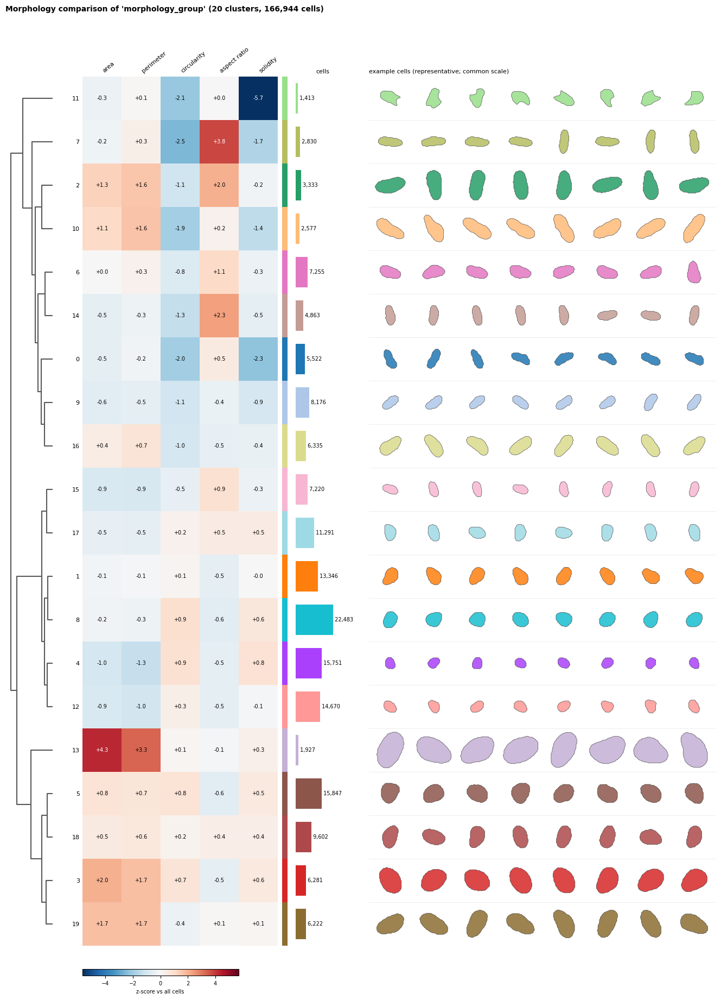

In [15]:
test =  compare_morphology_clusters(
    sdata,
    table = "cell_decon",
    group_key = "morphology_group",
    n_examples = 8,
    example_mode = "representative",
    order= "hierarchical",
)

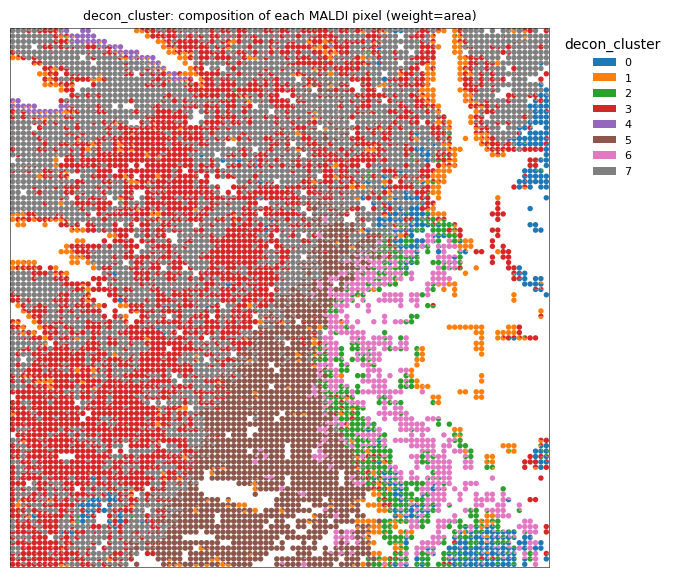

In [17]:
test2 =  plot_pixel_pies(
    sdata,
    color = "decon_cluster",
    table= "cell_decon",
    weight = "area",
    radius_scale = 1,
    roi = [5000, 5000, 10000, 10000],
)

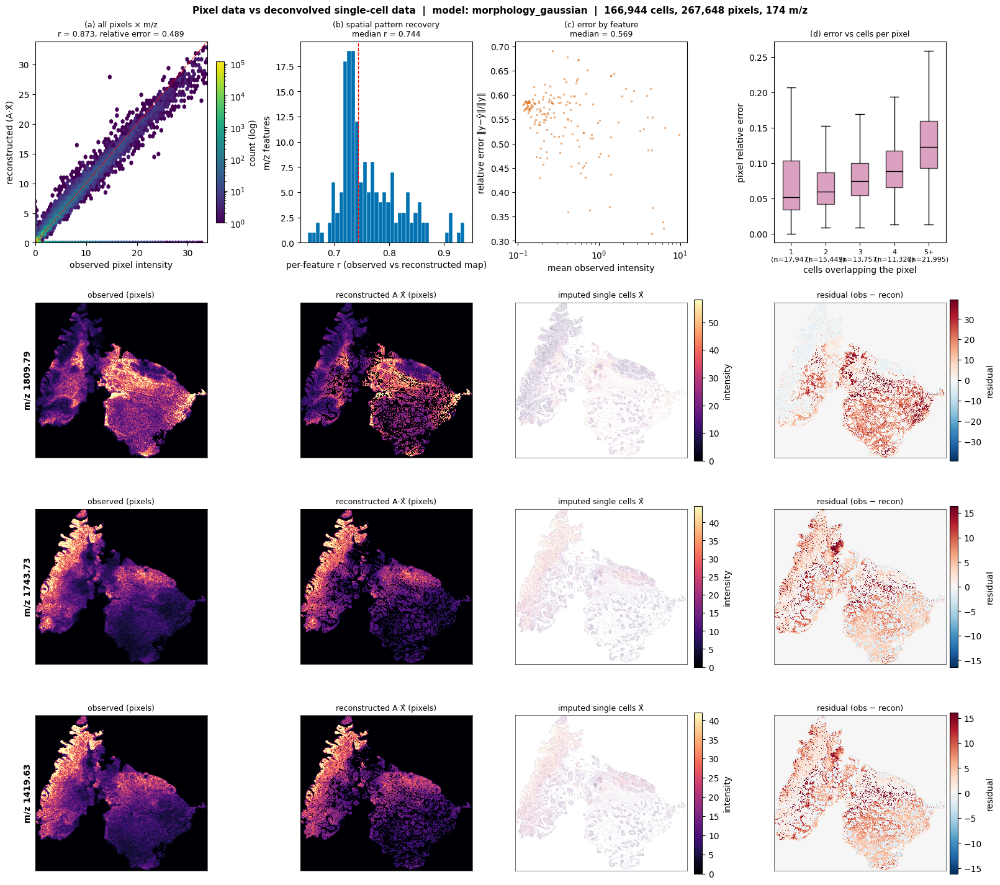

In [18]:
test3 = evaluate_deconvolution(
    sdata,
    table = "cell_decon",
)

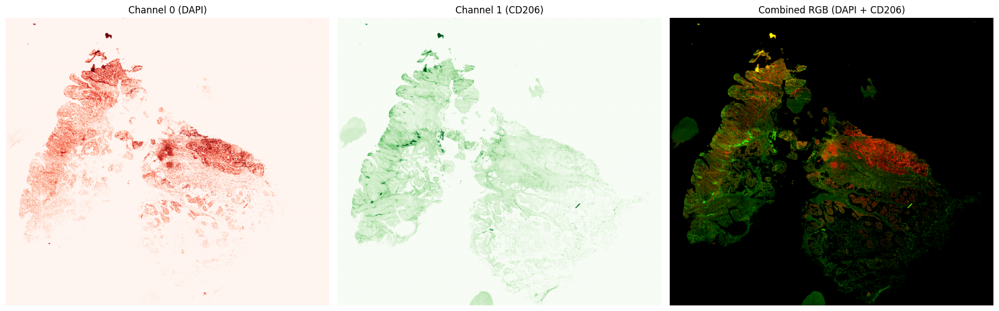

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Extract IHC image (channels, y, x)
img = sdata.images["ihc_image"].values

# Extract individual channels
ch0 = img[0]
ch1 = img[1]

# Create RGB composite
# Channel 0 = Red (DAPI)
# Channel 1 = Green (CD206)
# Channel 2 = Blue (empty)
rgb = np.zeros((img.shape[1], img.shape[2], 3), dtype=np.uint8)

rgb[:, :, 0] = ch0
rgb[:, :, 1] = ch1

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(ch0, cmap="Reds")
axes[0].set_title("Channel 0 (DAPI)")
axes[0].axis("off")

axes[1].imshow(ch1, cmap="Greens")
axes[1].set_title("Channel 1 (CD206)")
axes[1].axis("off")

axes[2].imshow(rgb)
axes[2].set_title("Combined RGB (DAPI + CD206)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [23]:
!pip install rasterio

  Using cached cligj-0.7.2-py3-none-any.whl.metadata (5.0 kB)
  Using cached click_plugins-1.1.1.2-py2.py3-none-any.whl.metadata (6.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 4.4 MB/s  0:00:04m0:00:0100:01
Using cached cligj-0.7.2-py3-none-any.whl (7.1 kB)
Using cached click_plugins-1.1.1.2-py2.py3-none-any.whl (11 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rasterio]3/4 [rasterio]


In [32]:
import numpy as np
import pandas as pd

from shapely.affinity import affine_transform
from rasterio.features import rasterize
from affine import Affine

from spatialdata.transformations import get_transformation


def extract_channel_intensity(
    sdata,
    shape="cell_segmentation",
    table="cell_decon",
    image="ihc_image",
    channels=None,
    column_names=None,
    coordinate_system="aligned",
    normalize=True,
):
    """
    Extract image-channel intensities for SpatialData shapes and
    store relative intensities in a SpatialData table's .obs.

    Parameters
    ----------
    sdata : SpatialData
        SpatialData object containing images, shapes and tables.

    shape : str
        Shape layer to extract intensities for.
        Examples: "pixels", "cell_segmentation".

    table : str
        Table in which to store measurements in .obs.
        Examples: "maldi_adata", "cell_decon".

    image : str
        Image element containing the channels.

    channels : list, int, str or None
        Channels to extract. Can use integer positions or channel
        names. If None, all channels are extracted.

    column_names : str, list or None
        Names of the output .obs columns. Must match the number
        of selected channels. If None, channel names are used.

    coordinate_system : str
        Shared coordinate system used to align shapes and images.

    normalize : bool
        If True, min-max normalize each channel's mean intensity
        to the range [0, 1]. If False, store raw mean intensities.

    Returns
    -------
    SpatialData
        Updated SpatialData object with intensity measurements
        stored in the specified table's .obs.
    """

    # ========================================================
    # 1. Load elements
    # ========================================================

    img = sdata.images[image]
    shapes = sdata.shapes[shape]
    adata = sdata.tables[table]

    # Support single-scale images and multiscale DataTrees
    if hasattr(img, "children"):
        image_data = img["scale0"]["image"]
        transform_element = img
    else:
        image_data = img
        transform_element = img

    # ========================================================
    # 2. Select channels
    # ========================================================

    if "c" in image_data.dims:
        available_channels = list(image_data.coords["c"].values)

        if channels is None:
            selected_channels = available_channels

        else:
            if isinstance(channels, (int, str, np.integer)):
                channels = [channels]

            selected_channels = []

            for ch in channels:
                if isinstance(ch, (int, np.integer)):
                    selected_channels.append(
                        available_channels[int(ch)]
                    )
                else:
                    if ch not in available_channels:
                        raise ValueError(
                            f"Channel '{ch}' not found. "
                            f"Available: {available_channels}"
                        )
                    selected_channels.append(ch)

    else:
        available_channels = ["channel_0"]
        selected_channels = available_channels

        if channels is not None:
            requested = (
                [channels]
                if isinstance(channels, (int, str, np.integer))
                else list(channels)
            )
            if len(requested) != 1 or requested[0] not in (
                0, "channel_0"
            ):
                raise ValueError(
                    "This image has no channel dimension; "
                    "only channel 0 can be selected."
                )

    # ========================================================
    # 3. Determine output column names
    # ========================================================

    if column_names is None:
        column_names = [
            str(ch) for ch in selected_channels
        ]

    elif isinstance(column_names, str):
        column_names = [column_names]

    if len(column_names) != len(selected_channels):
        raise ValueError(
            "Number of column_names must match "
            "number of selected channels."
        )

    if len(set(column_names)) != len(column_names):
        raise ValueError("column_names must be unique.")

    # ========================================================
    # 4. Calculate shape -> image transformation
    # ========================================================

    shape_to_aligned = get_transformation(
        shapes,
        to_coordinate_system=coordinate_system
    )

    image_to_aligned = get_transformation(
        transform_element,
        to_coordinate_system=coordinate_system
    )

    M_shapes = shape_to_aligned.to_affine_matrix(
        input_axes=("x", "y"),
        output_axes=("x", "y")
    )

    M_image = image_to_aligned.to_affine_matrix(
        input_axes=("x", "y"),
        output_axes=("x", "y")
    )

    # Shape coordinates -> image coordinates
    matrix = np.linalg.inv(M_image) @ M_shapes

    params = [
        matrix[0, 0],
        matrix[0, 1],
        matrix[1, 0],
        matrix[1, 1],
        matrix[0, 2],
        matrix[1, 2],
    ]

    # Transform polygons without changing original shapes
    geometries = [
        affine_transform(geom, params)
        if geom is not None and not geom.is_empty
        else None
        for geom in shapes.geometry
    ]

    # ========================================================
    # 5. Rasterize polygons once for all channels
    # ========================================================

    height = image_data.sizes["y"]
    width = image_data.sizes["x"]

    n_shapes = len(shapes)

    # Internal IDs: 1, 2, ..., N
    internal_ids = np.arange(
        1, n_shapes + 1,
        dtype=np.int32
    )

    raster_shapes = [
        (geom, int(cell_id))
        for geom, cell_id in zip(geometries, internal_ids)
        if geom is not None and not geom.is_empty
    ]

    mask = rasterize(
        raster_shapes,
        out_shape=(height, width),
        transform=Affine.identity(),
        fill=0,
        dtype="int32",
    )

    # ========================================================
    # 6. Find table observation -> shape ID mapping
    # ========================================================

    # SpatialData tables commonly store instance IDs in
    # obs[instance_key], specified in uns["spatialdata_attrs"].
    attrs = adata.uns.get("spatialdata_attrs", {})

    instance_key = attrs.get("instance_key")

    if instance_key is not None and instance_key in adata.obs:
        observation_ids = adata.obs[instance_key].astype(str)
    else:
        observation_ids = pd.Index(
            adata.obs_names.astype(str)
        )

    shape_ids = pd.Index(
        shapes.index.astype(str)
    )

    if not shape_ids.is_unique:
        raise ValueError(
            "Shape indices must be unique for ID matching."
        )

    # Avoid silent mismatches
    matches = pd.Index(observation_ids).isin(shape_ids)

    if not matches.any():
        raise ValueError(
            "No matching shape IDs found in the table. "
            "Check the table instance_key and shape indices."
        )

    print(f"\nImage: {image}")
    print(f"Shapes: {shape} ({n_shapes})")
    print(f"Table: {table}")
    print(f"Matching observations: {matches.sum()} / {len(matches)}")

    # ========================================================
    # 7. Calculate intensities for selected channels
    # ========================================================

    counts = np.bincount(
        mask.ravel(),
        minlength=n_shapes + 1
    )[1:]

    valid_pixels = mask > 0
    labels = mask[valid_pixels]

    for channel, column_name in zip(
        selected_channels,
        column_names
    ):

        if "c" in image_data.dims:
            channel_data = image_data.sel(c=channel).values
        else:
            channel_data = image_data.values

        channel_data = np.asarray(
            channel_data,
            dtype=np.float64
        )

        # Integrated intensity per shape
        intensity_sum = np.bincount(
            labels,
            weights=channel_data[valid_pixels],
            minlength=n_shapes + 1
        )[1:]

        # Mean intensity per shape
        mean_intensity = np.full(
            n_shapes,
            np.nan,
            dtype=np.float64
        )

        np.divide(
            intensity_sum,
            counts,
            out=mean_intensity,
            where=counts > 0
        )

        # ----------------------------------------------------
        # Relative intensity normalisation
        # ----------------------------------------------------

        if normalize:

            valid = np.isfinite(mean_intensity)

            if valid.any():
                min_val = np.min(mean_intensity[valid])
                max_val = np.max(mean_intensity[valid])

                if max_val > min_val:
                    mean_intensity[valid] = (
                        (mean_intensity[valid] - min_val)
                        / (max_val - min_val)
                    )
                else:
                    mean_intensity[valid] = 0.0

        # ----------------------------------------------------
        # Match values to table observations
        # ----------------------------------------------------

        intensity_series = pd.Series(
            mean_intensity,
            index=shape_ids
        )

        aligned_values = intensity_series.reindex(
            np.asarray(observation_ids, dtype=str)
        ).to_numpy(dtype=float)

        # Store in .obs
        adata.obs[column_name] = aligned_values

        print(
            f"  {channel} -> {column_name} "
            f"({np.isfinite(aligned_values).sum()} valid)"
        )

    # ========================================================
    # 8. Update SpatialData table
    # ========================================================

    sdata.tables[table] = adata

    print("\nChannel intensity extraction complete.")

    return sdata

In [86]:
import re
import numpy as np
import pandas as pd

from shapely.affinity import affine_transform
from rasterio.features import rasterize
from affine import Affine
from spatialdata.transformations import get_transformation


def extract_channel_intensity(
    sdata,
    shape="cell_segmentation",
    table="cell_decon",
    image="ihc_image",
    channels=None,
    column_names=None,
    coordinate_system="aligned",
    normalize=True,
    filter_out=None,
    filter_percentile=95,
    mad_threshold=3.5,
):
    """
    Extract mean fluorescence intensity for each SpatialData shape.

    Results are matched to table observations by instance ID
    and stored in the specified table's .obs.

    Parameters
    ----------
    sdata : SpatialData
        SpatialData object.

    shape : str
        Shape element, e.g. "pixels" or "cell_segmentation".

    table : str
        AnnData table, e.g. "cell_decon" or "maldi_adata".

    image : str
        Image element containing fluorescence channels.

    channels : int, str, list or None
        Channels to extract. None selects all channels.

    column_names : str, list or None
        Output .obs column names.

    coordinate_system : str
        Shared spatial coordinate system.

    normalize : bool
        Min-max normalise intensities to [0, 1] after filtering.

    filter_out : None or str
        None   : No filtering.
        "clip" : Clip values above filter_percentile.
        "trim" : Remove values outside the central percentile
                 interval (e.g. 2.5–97.5 for 95).
        "mad"  : Remove extreme values based on robust MAD.

    filter_percentile : float
        Percentile used for clipping, or central percentage
        retained when trimming.

    mad_threshold : float
        Modified Z-score threshold for MAD filtering.

    Returns
    -------
    SpatialData
        Updated object containing fluorescence values in .obs.
    """

    # ========================================================
    # 1. Validate options and load elements
    # ========================================================

    if filter_out not in (None, "clip", "trim", "mad"):
        raise ValueError(
            "filter_out must be None, 'clip', 'trim', or 'mad'."
        )

    if not 0 < filter_percentile <= 100:
        raise ValueError(
            "filter_percentile must be between 0 and 100."
        )

    if mad_threshold <= 0:
        raise ValueError("mad_threshold must be positive.")

    img = sdata.images[image]
    shapes = sdata.shapes[shape]
    adata = sdata.tables[table]

    # Handle multiscale and single-scale images
    if hasattr(img, "children"):
        image_data = img["scale0"]["image"]
    else:
        image_data = img

    # ========================================================
    # 2. Select channels
    # ========================================================

    if "c" in image_data.dims:
        available = list(image_data.coords["c"].values)

        if channels is None:
            selected = available
        else:
            if isinstance(channels, (int, str, np.integer)):
                channels = [channels]

            selected = []

            for ch in channels:
                if isinstance(ch, (int, np.integer)):
                    selected.append(available[int(ch)])
                else:
                    if ch not in available:
                        raise ValueError(
                            f"Channel {ch} not found. "
                            f"Available: {available}"
                        )
                    selected.append(ch)

    else:
        selected = ["channel_0"]

        if channels is not None:
            requested = (
                [channels]
                if isinstance(channels, (int, str, np.integer))
                else list(channels)
            )
            if requested not in ([0], ["channel_0"]):
                raise ValueError(
                    "Image has no channel dimension."
                )

    # ========================================================
    # 3. Output column names
    # ========================================================

    if column_names is None:
        column_names = [str(ch) for ch in selected]

    elif isinstance(column_names, str):
        column_names = [column_names]

    column_names = [
        re.sub(r"[^A-Za-z0-9_.-]", "_", str(name))
        for name in column_names
    ]

    if len(column_names) != len(selected):
        raise ValueError(
            "column_names must match selected channels."
        )

    if len(set(column_names)) != len(column_names):
        raise ValueError(
            "Column names must be unique."
        )

    # ========================================================
    # 4. Shape -> image coordinate transformation
    # ========================================================

    shape_to_aligned = get_transformation(
        shapes,
        to_coordinate_system=coordinate_system
    )

    image_to_aligned = get_transformation(
        img,
        to_coordinate_system=coordinate_system
    )

    M_shapes = shape_to_aligned.to_affine_matrix(
        input_axes=("x", "y"),
        output_axes=("x", "y")
    )

    M_image = image_to_aligned.to_affine_matrix(
        input_axes=("x", "y"),
        output_axes=("x", "y")
    )

    matrix = np.linalg.inv(M_image) @ M_shapes

    params = [
        matrix[0, 0],
        matrix[0, 1],
        matrix[1, 0],
        matrix[1, 1],
        matrix[0, 2],
        matrix[1, 2],
    ]

    geometries = [
        affine_transform(geom, params)
        if geom is not None and not geom.is_empty
        else None
        for geom in shapes.geometry
    ]

    # ========================================================
    # 5. Rasterize shapes
    # ========================================================

    height = image_data.sizes["y"]
    width = image_data.sizes["x"]

    n_shapes = len(shapes)

    if n_shapes == 0:
        raise ValueError("No shapes found.")

    if n_shapes > np.iinfo(np.int32).max:
        raise ValueError("Too many shapes for int32 labels.")

    internal_ids = np.arange(
        1, n_shapes + 1, dtype=np.int32
    )

    raster_shapes = [
        (geom, int(i))
        for geom, i in zip(geometries, internal_ids)
        if geom is not None and not geom.is_empty
    ]

    mask = rasterize(
        raster_shapes,
        out_shape=(height, width),
        transform=Affine.identity(),
        fill=0,
        dtype="int32",
    )

    counts = np.bincount(
        mask.ravel(),
        minlength=n_shapes + 1
    )[1:]

    valid_pixels = mask > 0
    labels = mask[valid_pixels]

    # ========================================================
    # 6. Match shape IDs to table observations
    # ========================================================

    attrs = adata.uns.get("spatialdata_attrs", {})
    instance_key = attrs.get("instance_key")
    region_key = attrs.get("region_key")

    if instance_key is not None and instance_key in adata.obs:
        observation_ids = pd.Index(
            adata.obs[instance_key].astype(str)
        )
    else:
        observation_ids = pd.Index(
            adata.obs_names.astype(str)
        )

    shape_ids = pd.Index(shapes.index.astype(str))

    if not shape_ids.is_unique:
        raise ValueError("Shape indices must be unique.")

    # Only assign to observations belonging to this shape
    # region when the table contains multiple regions.
    region_matches = np.ones(
        adata.n_obs, dtype=bool
    )

    if region_key is not None and region_key in adata.obs:
        region_matches = (
            adata.obs[region_key].astype(str).to_numpy()
            == shape
        )

    matches = (
        observation_ids.isin(shape_ids)
        & region_matches
    )

    if not matches.any():
        raise ValueError(
            "No matching observations found. "
            "Check the table instance IDs and region."
        )

    print(f"\nImage: {image}")
    print(f"Shapes: {shape} ({n_shapes})")
    print(f"Table: {table}")
    print(
        f"Matching observations: "
        f"{matches.sum()} / {adata.n_obs}"
    )
    print(f"Filtering: {filter_out}")

    # ========================================================
    # 7. Extract and filter channel intensities
    # ========================================================

    results = {}

    for channel, column_name in zip(
        selected, column_names
    ):

        if "c" in image_data.dims:
            channel_data = image_data.sel(c=channel).values
        else:
            channel_data = image_data.values

        channel_data = np.asarray(
            channel_data, dtype=np.float64
        )

        # Exclude non-finite image pixels
        usable = (
            valid_pixels
            & np.isfinite(channel_data)
        )

        channel_counts = np.bincount(
            mask[usable],
            minlength=n_shapes + 1
        )[1:]

        intensity_sum = np.bincount(
            mask[usable],
            weights=channel_data[usable],
            minlength=n_shapes + 1
        )[1:]

        mean_intensity = np.full(
            n_shapes, np.nan, dtype=np.float64
        )

        np.divide(
            intensity_sum,
            channel_counts,
            out=mean_intensity,
            where=channel_counts > 0
        )

        # ----------------------------------------------------
        # Filtering (on mean intensity per shape)
        # ----------------------------------------------------

        filtered = mean_intensity.copy()
        valid = np.isfinite(filtered)

        if valid.any() and filter_out == "clip":

            upper = np.percentile(
                filtered[valid],
                filter_percentile
            )

            filtered[valid] = np.minimum(
                filtered[valid], upper
            )

        elif valid.any() and filter_out == "trim":

            lower_pct = (100 - filter_percentile) / 2
            upper_pct = 100 - lower_pct

            lower, upper = np.percentile(
                filtered[valid],
                [lower_pct, upper_pct]
            )

            outside = (
                valid
                & (
                    (filtered < lower)
                    | (filtered > upper)
                )
            )

            filtered[outside] = np.nan

        elif valid.any() and filter_out == "mad":

            median = np.median(filtered[valid])

            mad = np.median(
                np.abs(filtered[valid] - median)
            )

            if mad > 0:
                modified_z = (
                    0.6745
                    * (filtered[valid] - median)
                    / mad
                )

                valid_positions = np.flatnonzero(valid)

                outlier_positions = valid_positions[
                    np.abs(modified_z) > mad_threshold
                ]

                filtered[outlier_positions] = np.nan

        # ----------------------------------------------------
        # Normalise after filtering
        # ----------------------------------------------------

        if normalize:

            valid = np.isfinite(filtered)

            if valid.any():

                minimum = filtered[valid].min()
                maximum = filtered[valid].max()

                if maximum > minimum:
                    filtered[valid] = (
                        (filtered[valid] - minimum)
                        / (maximum - minimum)
                    )
                else:
                    filtered[valid] = 0.0

        # ----------------------------------------------------
        # Match intensities to table
        # ----------------------------------------------------

        intensity_series = pd.Series(
            filtered,
            index=shape_ids
        )

        aligned_values = intensity_series.reindex(
            observation_ids
        ).to_numpy(dtype=float)

        aligned_values[~region_matches] = np.nan

        results[column_name] = aligned_values

        n_before = np.isfinite(mean_intensity).sum()
        n_after = np.isfinite(filtered).sum()

        print(
            f"  {channel} -> {column_name}: "
            f"{n_after}/{n_before} valid shapes "
            f"after filtering"
        )

    # ========================================================
    # 8. Store results directly in existing table
    # ========================================================

    # Avoid reassigning sdata.tables[table], which would
    # unnecessarily trigger SpatialData table validation.
    for column_name, values in results.items():
        adata.obs[column_name] = values

    print("\nChannel intensity extraction complete.")

    return sdata


In [87]:
aligned = extract_channel_intensity(
    aligned,
    shape="cell_segmentation",
    table="cell_decon",
    image="ihc_image",
    channels=[0, 1],
    column_names=["DAPI", "CD206_expression"],
    filter_out="clip",
    filter_percentile=95,
    normalize=True,
)


Image: ihc_image
Shapes: cell_segmentation (166953)
Table: cell_decon
Matching observations: 166944 / 166944
Filtering: clip
  channel_0 -> DAPI: 69899/69899 valid shapes after filtering
  channel_1 -> CD206_expression: 69899/69899 valid shapes after filtering

Channel intensity extraction complete.


In [88]:
aligned["cell_decon"].obs

,n_pixels,frac_cell_covered,max_pixel_weight,cell_area,cell_id,region,morphology_group,decon_cluster,decon_leiden,DAPI,CD206_expression
he_image_pyr0,2,1.0,0.663594,122.208528,he_image_pyr0,cell_segmentation,8,7,5,0.000000,1.000000
he_image_pyr1,2,1.0,0.567950,227.019870,he_image_pyr1,cell_segmentation,5,3,5,NaN,NaN
he_image_pyr2,2,1.0,0.999439,209.957704,he_image_pyr2,cell_segmentation,5,7,5,0.624242,0.500000
he_image_pyr3,1,1.0,1.000000,322.810856,he_image_pyr3,cell_segmentation,19,3,2,0.539394,0.354167
he_image_pyr4,2,1.0,0.710226,190.629486,he_image_pyr4,cell_segmentation,8,3,5,0.000000,0.322917
...,...,...,...,...,...,...,...,...,...,...,...
he_image_pyr225623,2,1.0,0.951698,180.390242,he_image_pyr225623,cell_segmentation,6,2,6,NaN,NaN
he_image_pyr225624,2,1.0,0.864214,257.620762,he_image_pyr225624,cell_segmentation,5,3,13,0.266667,0.583333
he_image_pyr225625,2,1.0,0.536417,244.037987,he_image_pyr225625,cell_segmentation,5,2,6,0.000000,0.000000
he_image_pyr225626,2,1.0,0.976843,117.560827,he_image_pyr225626,cell_segmentation,8,2,6,NaN,NaN


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:9: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:22: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:36: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


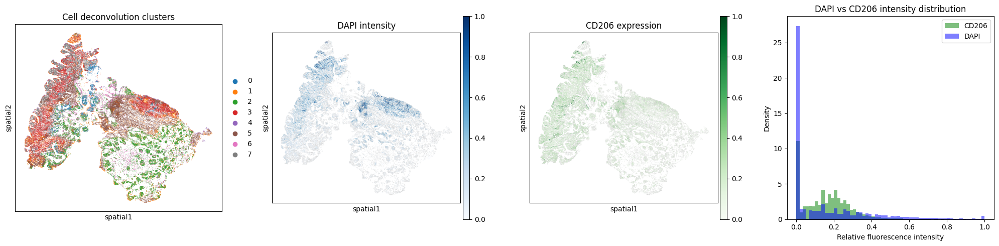

In [62]:
import matplotlib.pyplot as plt
import scanpy as sc

adata = aligned.tables["cell_decon"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# 1. Cell deconvolution clusters
sc.pl.spatial(
    adata,
    img_key="hires",
    color="decon_cluster",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[0],
    show=False,
    title="Cell deconvolution clusters"
)

# 2. DAPI intensity
sc.pl.spatial(
    adata,
    img_key="hires",
    color="DAPI",
    cmap="Blues",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[1],
    show=False,
    title="DAPI intensity"
)

# 3. CD206 intensity
sc.pl.spatial(
    adata,
    img_key="hires",
    color="CD206_expression",
    cmap="Greens",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[2],
    show=False,
    title="CD206 expression"
)

# 4. intensity distribution
axes[3].hist(
    adata.obs["CD206_expression"].dropna(),
    bins=60,
    color="green",
    alpha=0.5,
    label="CD206",
    density=True
)

axes[3].hist(
    adata.obs["DAPI"].dropna(),
    bins=60,
    color="blue",
    alpha=0.5,
    label="DAPI",
    density=True
)

axes[3].set_xlabel("Relative fluorescence intensity")
axes[3].set_ylabel("Density")
axes[3].set_title("DAPI vs CD206 intensity distribution")
axes[3].legend()

plt.tight_layout()
plt.show()

/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:9: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:22: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1952023190.py:36: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


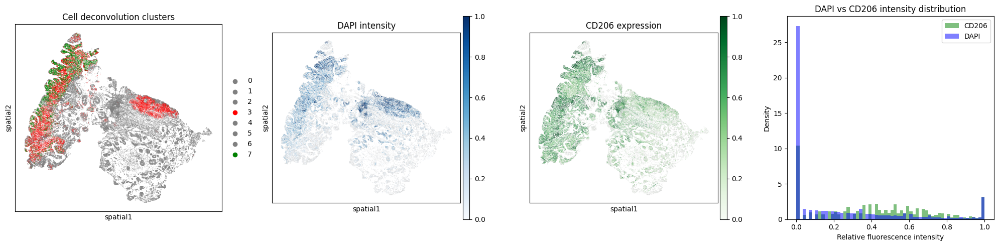

In [89]:
import matplotlib.pyplot as plt
import scanpy as sc

adata = aligned.tables["cell_decon"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# 1. Cell deconvolution clusters
sc.pl.spatial(
    adata,
    img_key="hires",
    color="decon_cluster",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[0],
    show=False,
    title="Cell deconvolution clusters"
)

# 2. DAPI intensity
sc.pl.spatial(
    adata,
    img_key="hires",
    color="DAPI",
    cmap="Blues",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[1],
    show=False,
    title="DAPI intensity"
)

# 3. CD206 intensity
sc.pl.spatial(
    adata,
    img_key="hires",
    color="CD206_expression",
    cmap="Greens",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax=axes[2],
    show=False,
    title="CD206 expression"
)

# 4. intensity distribution
axes[3].hist(
    adata.obs["CD206_expression"].dropna(),
    bins=60,
    color="green",
    alpha=0.5,
    label="CD206",
    density=True
)

axes[3].hist(
    adata.obs["DAPI"].dropna(),
    bins=60,
    color="blue",
    alpha=0.5,
    label="DAPI",
    density=True
)

axes[3].set_xlabel("Relative fluorescence intensity")
axes[3].set_ylabel("Density")
axes[3].set_title("DAPI vs CD206 intensity distribution")
axes[3].legend()

plt.tight_layout()
plt.show()

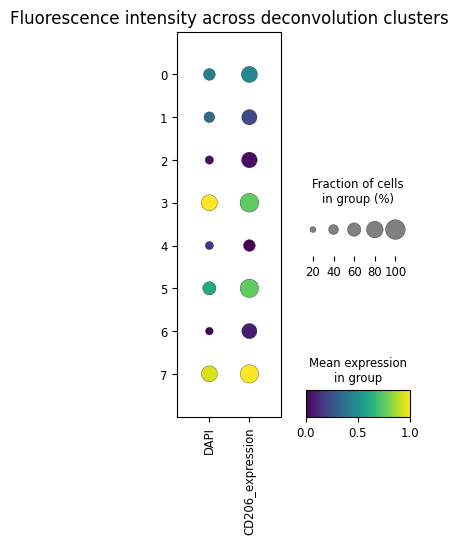

In [90]:
import scanpy as sc
import pandas as pd
import anndata as ad

adata = aligned.tables["cell_decon"]

markers = ["DAPI", "CD206_expression"]

# Extract fluorescence measurements and cluster labels
df = adata.obs[
    ["decon_cluster"] + markers
].copy()

# Remove cells without fluorescence measurements
df = df.dropna(subset=markers)

# Create temporary AnnData for plotting
adata_plot = ad.AnnData(
    X=df[markers].to_numpy(dtype=float),
    obs=df[["decon_cluster"]].copy(),
    var=pd.DataFrame(index=markers)
)

adata_plot.obs["decon_cluster"] = (
    adata_plot.obs["decon_cluster"].astype("category")
)

# Plot
sc.pl.dotplot(
    adata_plot,
    var_names=markers,
    groupby="decon_cluster",
    standard_scale="var",
    cmap="viridis",
    dot_min=0,
    dot_max=1,
    figsize=(3, 5),
    title="Fluorescence intensity across deconvolution clusters"
)

/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1911522625.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1911522625.py:18: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


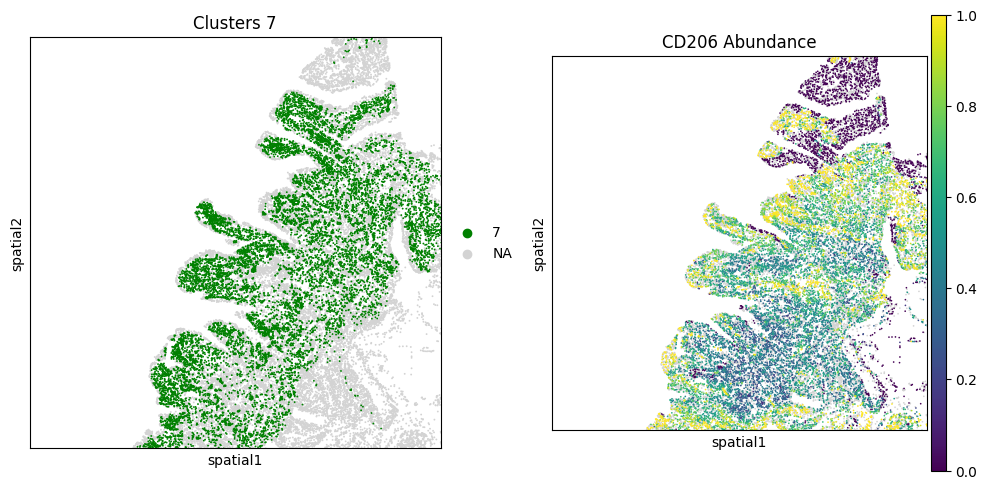

: 

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sc.pl.spatial(
    adata,
    img_key="hires",
    color="decon_cluster",
    groups=["7"],
    palette = ["green"],
    size=4,
    spot_size=10,
    alpha_img=0,
    ax = ax[0],
    show= False,
    crop_coord=(1000, 10000, 1000, 10000),
    title="Clusters 7"
)

sc.pl.spatial(
    adata,
    img_key="hires",
    color="CD206_expression",
    size=4,
    spot_size=10,
    alpha_img=0,
    ax = ax[1],
    show= False,
    crop_coord=(1000, 10000, 1000, 10000),
    title="CD206 Abundance"
)

plt.tight_layout()
plt.show()

IHC image: 1508 x 1341
Segmented cells: 166953

Cell to IHC transformation:
[[ 3.49812564e-02 -1.82108331e-03  1.01145073e+02]
 [ 1.82261477e-03  3.49518633e-02  4.21419378e+01]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Cell polygons transformed to IHC coordinates
Cell segmentation rasterized


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/scipy/ndimage/_measurements.py:809: RuntimeWarning: invalid value encountered in divide
  return sum / np.asanyarray(count).astype(np.float64)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `cell_segmentation` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)



CD206 intensity measurements:
         CD206_mean  CD206_median     CD206_max   CD206_total   CD206_pixels
count  69899.000000  69899.000000  69899.000000  69899.000000  166953.000000
mean      41.947091     41.946695     42.103564     43.311263       0.431654
std       33.021927     33.023421     33.136863     35.719882       0.522738
min        0.000000      0.000000      0.000000      0.000000       0.000000
25%       16.000000     16.000000     16.000000     16.000000       0.000000
50%       41.000000     41.000000     41.000000     41.000000       0.000000
75%       61.000000     61.000000     61.000000     61.000000       1.000000
max      255.000000    255.000000    255.000000    539.000000       9.000000

Cells without assigned IHC pixels: 97054


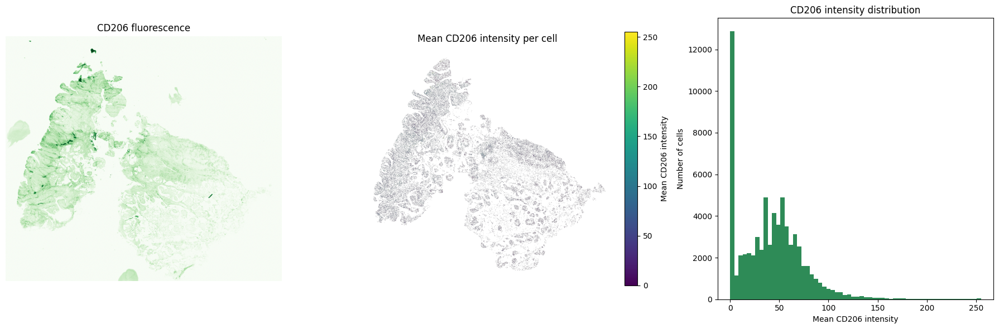

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely.affinity import affine_transform
from rasterio.features import rasterize
from affine import Affine
from scipy.ndimage import mean, maximum, sum as ndi_sum

from spatialdata.transformations import get_transformation


# ============================================================
# 1. Extract IHC image and cell segmentation
# ============================================================

img = sdata.images["ihc_image"]
cells_original = sdata.shapes["cell_segmentation"]

# Channel 1 = CD206
cd206 = img.sel(c="channel_1").values

height, width = cd206.shape

print(f"IHC image: {width} x {height}")
print(f"Segmented cells: {len(cells_original)}")


# ============================================================
# 2. Calculate transformation: Cells -> IHC coordinates
# ============================================================

# Get transformations to the shared aligned coordinate system
cell_to_aligned = get_transformation(
    cells_original,
    to_coordinate_system="aligned"
)

ihc_to_aligned = get_transformation(
    img,
    to_coordinate_system="aligned"
)

# Convert transformations to affine matrices
M_cells = cell_to_aligned.to_affine_matrix(
    input_axes=("x", "y"),
    output_axes=("x", "y")
)

M_ihc = ihc_to_aligned.to_affine_matrix(
    input_axes=("x", "y"),
    output_axes=("x", "y")
)

# Cells -> aligned -> IHC pixel coordinates
matrix = np.linalg.inv(M_ihc) @ M_cells

print("\nCell to IHC transformation:")
print(matrix)

# Convert to Shapely affine parameters:
# [a, b, d, e, xoff, yoff]
params = [
    matrix[0, 0],
    matrix[0, 1],
    matrix[1, 0],
    matrix[1, 1],
    matrix[0, 2],
    matrix[1, 2],
]

# Transform polygons into IHC image coordinates
cells_ihc = cells_original.copy()

cells_ihc["geometry"] = cells_ihc.geometry.apply(
    lambda geom: affine_transform(geom, params)
    if geom is not None and not geom.is_empty
    else geom
)

print("Cell polygons transformed to IHC coordinates")


# ============================================================
# 3. Rasterize segmentation polygons
# ============================================================

# Each cell receives a unique integer ID
cell_ids = np.arange(1, len(cells_ihc) + 1)

shapes = [
    (geom, int(cell_id))
    for geom, cell_id in zip(
        cells_ihc.geometry,
        cell_ids
    )
    if geom is not None and not geom.is_empty
]

cell_mask = rasterize(
    shapes,
    out_shape=(height, width),
    transform=Affine.identity(),
    fill=0,
    dtype="int32",
)

print("Cell segmentation rasterized")


# ============================================================
# 4. Calculate CD206 intensity per cell
# ============================================================

# Convert to float to avoid uint8 overflow
cd206_float = cd206.astype(np.float32)

# Mean intensity
mean_intensity = mean(
    cd206_float,
    labels=cell_mask,
    index=cell_ids
)

# Maximum intensity
max_intensity = maximum(
    cd206_float,
    labels=cell_mask,
    index=cell_ids
)

# Integrated intensity
total_intensity = ndi_sum(
    cd206_float,
    labels=cell_mask,
    index=cell_ids
)

# Number of IHC pixels assigned to each cell
pixel_counts = np.bincount(
    cell_mask.ravel(),
    minlength=len(cells_ihc) + 1
)[1:]

# Median intensity
median_intensity = np.full(
    len(cells_ihc),
    np.nan,
    dtype=float
)

for i, cell_id in enumerate(cell_ids):
    values = cd206_float[cell_mask == cell_id]

    if values.size > 0:
        median_intensity[i] = np.median(values)

# Convert to arrays
mean_intensity = np.asarray(mean_intensity, dtype=float)
max_intensity = np.asarray(max_intensity, dtype=float)
total_intensity = np.asarray(total_intensity, dtype=float)

# Cells without pixels should be NaN
mean_intensity[pixel_counts == 0] = np.nan
max_intensity[pixel_counts == 0] = np.nan
total_intensity[pixel_counts == 0] = np.nan


# ============================================================
# 5. Store CD206 measurements in SpatialData
# ============================================================

cells = cells_original.copy()

cells["CD206_mean"] = mean_intensity
cells["CD206_median"] = median_intensity
cells["CD206_max"] = max_intensity
cells["CD206_total"] = total_intensity
cells["CD206_pixels"] = pixel_counts

# Update SpatialData
sdata.shapes["cell_segmentation"] = cells

print("\nCD206 intensity measurements:")
print(
    cells[
        [
            "CD206_mean",
            "CD206_median",
            "CD206_max",
            "CD206_total",
            "CD206_pixels",
        ]
    ].describe()
)

print(
    f"\nCells without assigned IHC pixels: "
    f"{np.sum(pixel_counts == 0)}"
)


# ============================================================
# 6. Create cell-level CD206 intensity map
# ============================================================

cell_mean_map = np.full(
    cell_mask.shape,
    np.nan,
    dtype=np.float32
)

valid = cell_mask > 0

cell_mean_map[valid] = mean_intensity[
    cell_mask[valid] - 1
]


# ============================================================
# 7. Plot results
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

# ------------------------------------------------------------
# Panel 1: Original CD206 fluorescence
# ------------------------------------------------------------

axes[0].imshow(
    cd206,
    cmap="Greens",
    origin="upper"
)

axes[0].set_title("CD206 fluorescence")
axes[0].axis("off")


# ------------------------------------------------------------
# Panel 2: Mean CD206 intensity per cell
# ------------------------------------------------------------

im = axes[1].imshow(
    cell_mean_map,
    cmap="viridis",
    origin="upper"
)

axes[1].set_title("Mean CD206 intensity per cell")
axes[1].axis("off")

fig.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Mean CD206 intensity"
)


# ------------------------------------------------------------
# Panel 3: Distribution of CD206 intensity
# ------------------------------------------------------------

valid_intensities = mean_intensity[
    np.isfinite(mean_intensity)
]

axes[2].hist(
    valid_intensities,
    bins=60,
    color="seagreen",
    edgecolor="none"
)

axes[2].set_xlabel("Mean CD206 intensity")
axes[2].set_ylabel("Number of cells")
axes[2].set_title("CD206 intensity distribution")

plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import pandas as pd

# Get cell segmentation and cell deconvolution table
cells = aligned.shapes["cell_segmentation"]
adata = aligned.tables["cell_decon"]

# Match cells by their IDs rather than row order
# Assumes adata.obs_names correspond to cells.index
cd206 = pd.Series(
    cells["CD206_mean"].to_numpy(),
    index=cells.index.astype(str)
)

# Align values with cell_decon observations
values = cd206.reindex(adata.obs_names.astype(str)).to_numpy(dtype=float)

# Min-max normalisation (0–1)
relative = np.full(len(values), np.nan)

valid = np.isfinite(values)

if valid.any():
    minimum = values[valid].min()
    maximum = values[valid].max()

    if maximum > minimum:
        relative[valid] = (
            (values[valid] - minimum) /
            (maximum - minimum)
        )
    else:
        relative[valid] = 0.0

# Store in cell_decon
adata.obs["CD206 expression"] = relative

print(adata.obs["CD206 expression"].describe())

count    69897.000000
mean         0.164503
std          0.129497
min          0.000000
25%          0.062745
50%          0.160784
75%          0.239216
max          1.000000
Name: CD206 expression, dtype: float64


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_65762/1171394665.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


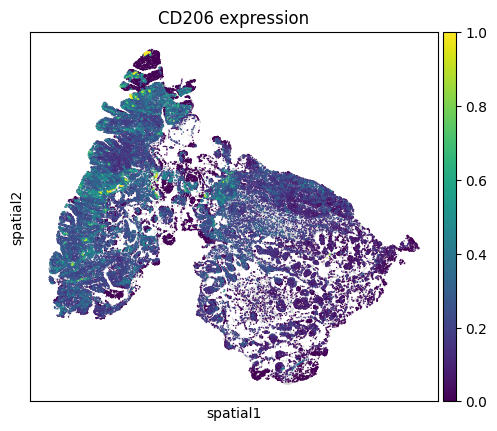

In [31]:
sc.pl.spatial(
        adata,
        img_key="hires",
        color="CD206 expression",
        size=10,
        spot_size=10,
        alpha=1,
        alpha_img=0,
    )

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

sdata.pl.render_shapes(
    "cell_segmentation",
    color="CD206_mean",
    cmap="viridis"
).pl.show(
    "aligned",
    ax=ax,
    title="Mean CD206 intensity per cell"
)

plt.show()

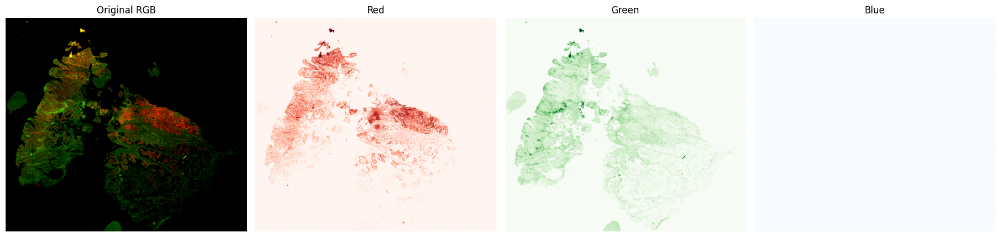

In [100]:

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Original RGB image
axes[0].imshow(img)
axes[0].set_title("Original RGB")

# Individual channels
for ax, channel, name, cmap in zip(
    axes[1:],
    [R, G, B],
    ["Red", "Green", "Blue"],
    ["Reds", "Greens", "Blues"]
):
    ax.imshow(channel, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Image shape: (1341, 1508, 3)


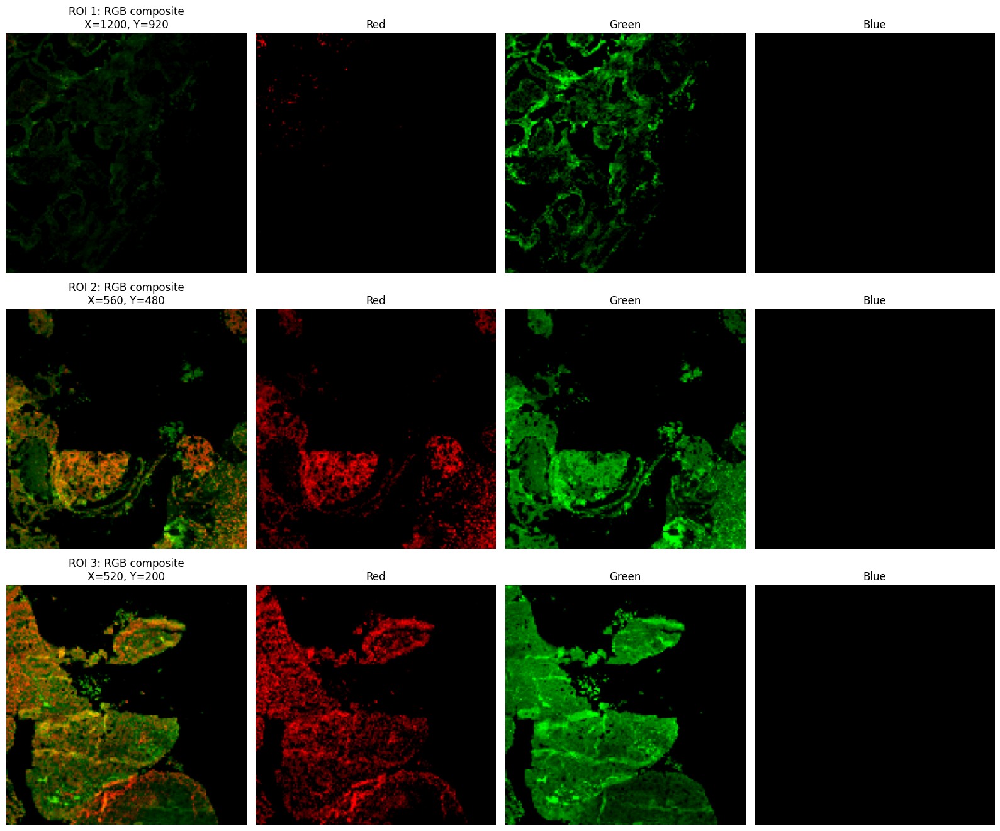

Selected ROI coordinates:
ROI 1: Y=920, X=1200
ROI 2: Y=480, X=560
ROI 3: Y=200, X=520


In [101]:

import numpy as np
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# --------------------------------------------------
# Load image
# --------------------------------------------------

tif_path = "/Users/andrewcauser/Documents/Griffith/test_data/IHC_new/DM_22.05.26_Image_2_19PM0001_RedGrnChannel.tif"

img = tifffile.imread(tif_path)

print("Image shape:", img.shape)

# RGB channels
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

# --------------------------------------------------
# Channel colour maps (black -> channel colour)
# --------------------------------------------------

cmaps = [
    LinearSegmentedColormap.from_list(
        "red_signal", ["black", "red"]
    ),
    LinearSegmentedColormap.from_list(
        "green_signal", ["black", "lime"]
    ),
    LinearSegmentedColormap.from_list(
        "blue_signal", ["black", "blue"]
    )
]

channels = [R, G, B]
channel_names = ["Red", "Green", "Blue"]

# --------------------------------------------------
# ROI selection
# --------------------------------------------------

roi_size = 160
n_rois = 3
rng = np.random.default_rng(42)

height, width = img.shape[:2]

# Identify tissue-containing pixels
tissue_mask = np.max(img[:, :, :2], axis=2) > 5

# Find candidate ROI positions with sufficient tissue
candidates = []

step = 40

for y in range(0, height - roi_size, step):
    for x in range(0, width - roi_size, step):

        mask = tissue_mask[
            y:y+roi_size,
            x:x+roi_size
        ]

        if mask.mean() > 0.15:
            candidates.append((y, x))

# Randomly select non-overlapping ROIs
rng.shuffle(candidates)

selected_rois = []

for y, x in candidates:

    overlaps = False

    for yy, xx in selected_rois:

        if (
            abs(y - yy) < roi_size and
            abs(x - xx) < roi_size
        ):
            overlaps = True
            break

    if not overlaps:
        selected_rois.append((y, x))

    if len(selected_rois) == n_rois:
        break

if len(selected_rois) < n_rois:
    raise ValueError("Could not find three suitable ROIs.")

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(
    n_rois, 4,
    figsize=(16, 4.5 * n_rois)
)

for i, (y, x) in enumerate(selected_rois):

    roi = img[
        y:y+roi_size,
        x:x+roi_size
    ]

    # Original RGB
    axes[i, 0].imshow(roi)
    axes[i, 0].set_title(
        f"ROI {i+1}: RGB composite\nX={x}, Y={y}"
    )

    # Individual channels
    for j, (channel, name, cmap) in enumerate(
        zip(channels, channel_names, cmaps)
    ):

        crop = channel[
            y:y+roi_size,
            x:x+roi_size
        ]

        # Local percentile normalisation
        nonzero = crop[crop > 0]

        if len(nonzero) > 0:
            vmin, vmax = np.percentile(
                nonzero, [1, 99]
            )
        else:
            vmin, vmax = 0, 1

        if vmax <= vmin:
            vmax = vmin + 1

        axes[i, j+1].imshow(
            crop,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        axes[i, j+1].set_title(name)

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Selected ROI coordinates:")
for i, (y, x) in enumerate(selected_rois):
    print(f"ROI {i+1}: Y={y}, X={x}")


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808/704873868.py:59: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_42808

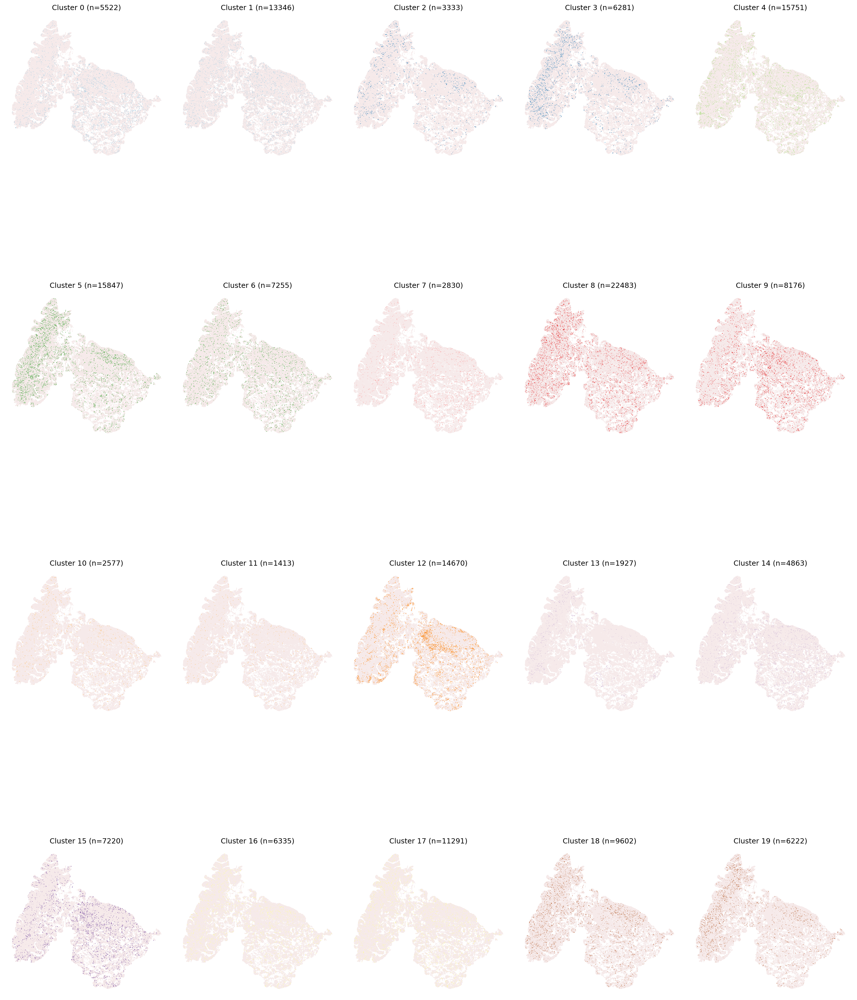

In [41]:
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

adata = sdata["cell_decon"]
key = "morphology_group"

adata.obs[key] = adata.obs[key].astype(str).astype("category")

clusters = sorted(
    adata.obs[key].cat.categories,
    key=lambda s: int(s) if s.isdigit() else s
)

adata.obs[key] = adata.obs[key].cat.reorder_categories(clusters)

# Assign colours
paired = [
    to_hex(c)
    for c in plt.get_cmap("Paired", len(clusters)).colors
]

color_of = dict(zip(clusters, paired))
adata.uns[f"{key}_colors"] = [color_of[c] for c in clusters]

# Plot layout
ncols = 5
nrows = int(np.ceil(len(clusters) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4 * ncols, 7 * nrows),
    dpi=150
)

axes = np.atleast_1d(axes).ravel()

# Temporary highlighting column
adata.obs["_highlight"] = adata.obs[key].astype(str)

for ax, c in zip(axes, clusters):

    # Highlight current cluster
    adata.obs["_highlight"] = np.where(
        adata.obs[key] == c,
        c,
        "Other"
    )

    adata.obs["_highlight"] = adata.obs["_highlight"].astype("category")

    # Current cluster colour + background
    adata.uns["_highlight_colors"] = [
        color_of[c],
        "#f6eaeaff"
    ]

    sc.pl.spatial(
        adata,
        img_key="hires",
        color="_highlight",
        palette=[color_of[c], "#f6eaeaff"],
        size=10,
        spot_size=10,
        alpha=1,
        alpha_img=0,
        ax=ax,
        show=False,
        legend_loc=None,
        frameon=False
    )

    ax.set_title(
        f"Cluster {c} (n={(adata.obs[key] == c).sum()})"
    )

# Hide unused axes
for ax in axes[len(clusters):]:
    ax.axis("off")

adata.obs.drop(columns="_highlight", inplace=True)

plt.tight_layout()
plt.show()

In [ ]:
# W = sdata.tables["cell_adata"].obsm["pixel_weights"]
# A = W.T.tocsr()

In [4]:
A, Y, pixel_ids = build_pixel_cell_matrix(sdata)
n_cells_per_pixel = A.getnnz(axis=1)
morphology = extract_cell_morphology(sdata)

embeddings, clusters = make_morphology_groups(
    morphology,
    n_groups=20,
    n_pcs=8,
)

In [5]:
# Model 1: Area-based baseline
X_area = area_weighted_baseline(
    A,
    Y,
)

# Model 2: Morphology-informed group prior
X_prior = group_morphology_prior(
    A,
    Y,
    clusters,
)

# Model 3: Non-negative Gaussian deconvolution
X_deconv = gaussian_nonnegative_deconvolution(
    A,
    Y,
    X_prior=X_prior,
    lambda_prior=0.1,
    max_iter=100,
)

In [ ]:
models = {
    "Area-based": X_area,
    "Morphology prior": X_prior,
    "Morphology deconvolution": X_deconv,
}

metrics = {}

for name, X in models.items():

    result = reconstruction_metrics(
        A,
        Y,
        X,
    )

    metrics[name] = {
        "RMSE": result["rmse"],
        "Relative error": result["relative_error"],
    }

metrics_df = pd.DataFrame(metrics).T

print(metrics_df)

                              RMSE  Relative error
Area-based                1.401764        0.483370
Morphology prior          1.947899        0.671555
Morphology deconvolution  1.419694        0.489538


Feature: 1953.85


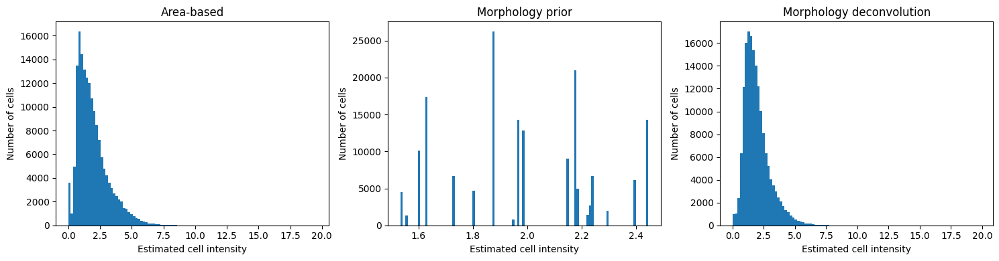

In [ ]:
# feature_idx = 50

# feature_name = sdata.tables["maldi_adata"].var_names[
#     feature_idx
# ]

# print("Feature:", feature_name)

# import matplotlib.pyplot as plt

# fig, axes = plt.subplots(
#     1,
#     3,
#     figsize=(15, 4),
# )

# for ax, (name, X) in zip(axes, models.items()):

#     ax.hist(
#         X[:, feature_idx],
#         bins=100,
#     )

#     ax.set_title(name)
#     ax.set_xlabel("Estimated cell intensity")
#     ax.set_ylabel("Number of cells")

# plt.tight_layout()
# plt.show()

In [7]:
cell_adata = sdata.tables["cell_adata"]

cell_adata.layers["maldi_area"] = X_area
cell_adata.layers["maldi_morphology_prior"] = X_prior
cell_adata.layers["maldi_deconvolution"] = X_deconv

cell_adata.uns["deconvolution_parameters"] = {
    "method": "nonnegative_gaussian",
    "lambda_prior": 0.1,
    "max_iter": 100,
    "n_morphology_groups": 20,
}

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans

# -------------------------------------------------------
# 1. Get deconvolved cell-level MALDI intensities
# -------------------------------------------------------

cell_adata = sdata.tables["cell_adata"]

X = np.asarray(X_deconv, dtype=np.float32)

assert X.shape == (cell_adata.n_obs, 174)

# Replace invalid values and enforce non-negativity
X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

X = np.maximum(X, 0)

print("Cell-level MALDI matrix:", X.shape)

# -------------------------------------------------------
# 2. Transform the intensity matrix
# -------------------------------------------------------

# Log transformation reduces the influence of very high intensities
X_log = np.log1p(X)

# Standardise each metabolite across cells
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# -------------------------------------------------------
# 3. PCA
# -------------------------------------------------------

n_pcs = 30

pca = PCA(
    n_components=n_pcs,
    random_state=42,
)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print(
    "Variance explained by 30 PCs:",
    pca.explained_variance_ratio_.sum()
)

# -------------------------------------------------------
# 4. K-means clustering
# -------------------------------------------------------

n_clusters = 8

kmeans = MiniBatchKMeans(
    n_clusters=n_clusters,
    random_state=42,
    batch_size=4096,
    n_init=10,
    max_iter=200,
)

clusters = kmeans.fit_predict(X_pca)

# Store cluster labels
cell_adata.obs["MALDI_cluster"] = pd.Categorical(
    clusters.astype(str)
)

print(
    cell_adata.obs["MALDI_cluster"]
    .value_counts()
    .sort_index()
)


Cell-level MALDI matrix: (166942, 174)
PCA shape: (166942, 30)
Variance explained by 30 PCs: 0.8509123
MALDI_cluster
0     3774
1    25738
2    14553
3    36037
4    34945
5    15216
6    25556
7    11123
Name: count, dtype: int64


H&E shape: (3, 25800, 28350)
Plotting H&E shape: (2580, 2835, 3)
Downsampling factor: 10
Cell coordinate range:
X: 755.8333044269693 27720.80186668963
Y: 701.8514979058554 25069.67730498789
H&E image dimensions:
Width: 28350
Height: 25800


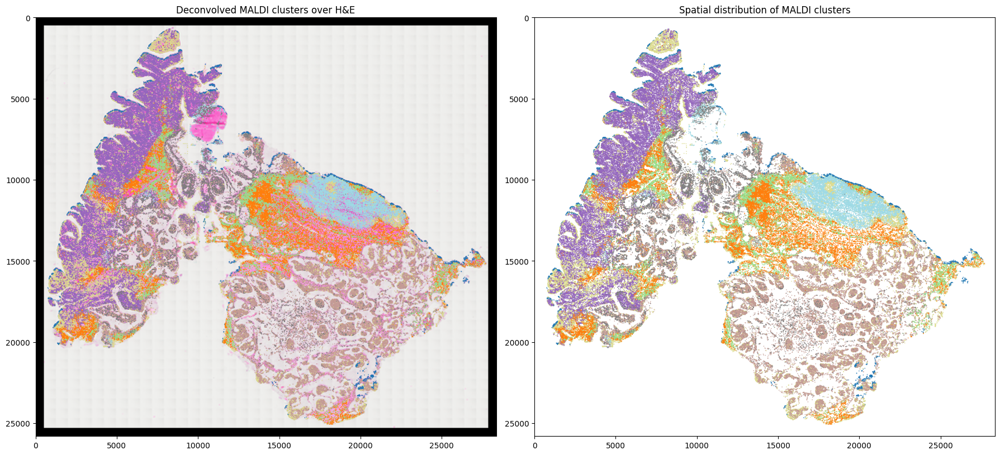

In [ ]:

# -------------------------------------------------------
# 5. Get the H&E image
# -------------------------------------------------------

he = sdata.images["he_image"]

# Support both xarray DataArray and dask-backed arrays
he = he.data if hasattr(he, "data") else he

if hasattr(he, "compute"):
    he = he.compute()

he = np.asarray(he)

print("H&E shape:", he.shape)

# Expected shape: (3, height, width)
if he.ndim == 3 and he.shape[0] in (3, 4):
    he = np.moveaxis(he, 0, -1)

# Remove alpha channel if present
if he.shape[-1] == 4:
    he = he[..., :3]

# -------------------------------------------------------
# 6. Downsample H&E for plotting
# -------------------------------------------------------

max_plot_size = 3000

height, width = he.shape[:2]

downsample = max(
    1,
    int(np.ceil(max(height, width) / max_plot_size))
)

he_plot = he[::downsample, ::downsample]

print("Plotting H&E shape:", he_plot.shape)
print("Downsampling factor:", downsample)

# -------------------------------------------------------
# 7. Get cell coordinates
# -------------------------------------------------------

coords = np.asarray(
    cell_adata.obsm["spatial"]
)

x = coords[:, 0]
y = coords[:, 1]

cluster_labels = clusters

print("Cell coordinate range:")
print("X:", x.min(), x.max())
print("Y:", y.min(), y.max())

print("H&E image dimensions:")
print("Width:", width)
print("Height:", height)

# -------------------------------------------------------
# 8. Plot clusters on H&E
# -------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 9),
)

# H&E background with metabolite clusters
axes[0].imshow(
    he_plot,
    extent=(0, width, height, 0),
)

scatter = axes[0].scatter(
    x,
    y,
    c=cluster_labels,
    cmap="tab20",
    s=1.5,
    alpha=0.8,
    linewidths=0,
    rasterized=True,
)

axes[0].set_title(
    "Deconvolved MALDI clusters over H&E"
)

axes[0].set_xlim(0, width)
axes[0].set_ylim(height, 0)

axes[0].set_aspect("equal")

# Clusters without the H&E background
axes[1].scatter(
    x,
    y,
    c=cluster_labels,
    cmap="tab20",
    s=1.5,
    alpha=0.8,
    linewidths=0,
    rasterized=True,
)

axes[1].set_title(
    "Spatial distribution of MALDI clusters"
)

axes[1].set_xlim(0, width)
axes[1].set_ylim(height, 0)

axes[1].set_aspect("equal")

plt.tight_layout()

plt.show()


In [12]:
# Store the clustering in the cell table
cell_adata.obs["MALDI_cluster"] = clusters.astype(str)
sdata["cell_adata"].obs["MALDI_cluster"] = sdata["cell_adata"].obs["MALDI_cluster"].astype(str).astype("category")

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely.geometry import box
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection


# =====================================================
# 1. PREPARE H&E IMAGE
# =====================================================

def prepare_he_image(
    sdata,
    image_key="he_image",
    scale="scale0",
):
    """Load a SpatialData image as an RGB numpy array."""

    image = sdata.images[image_key]

    # Handle multiscale DataTree images
    if hasattr(image, "children"):

        if scale not in image:
            raise ValueError(
                f"Scale '{scale}' not found. "
                f"Available scales: {list(image.children)}"
            )

        image = image[scale]
        image = image.ds["image"]

    if hasattr(image, "compute"):
        image = image.compute()

    if hasattr(image, "values"):
        image = image.values

    image = np.asarray(image)

    # Convert CYX to YXC
    if image.ndim == 3 and image.shape[0] in (3, 4):
        image = np.moveaxis(image, 0, -1)

    image = image[..., :3].astype(np.float32)

    if image.max() > 1:

        if image.max() <= 255:
            image /= 255.0

        else:
            for channel in range(3):

                lo, hi = np.percentile(
                    image[..., channel],
                    [1, 99.5]
                )

                image[..., channel] = (
                    image[..., channel] - lo
                ) / (hi - lo + 1e-8)

    return np.clip(image, 0, 1)


# =====================================================
# 2. PLOT MALDI PIXELS AS SPATIAL SQUARES
# =====================================================

def plot_maldi_pixels(
    ax,
    px,
    py,
    values,
    pixel_size=50,
    cmap="viridis",
    vmin=None,
    vmax=None,
):
    """
    Plot MALDI pixels using their actual spatial dimensions.

    pixel_size should be in the same coordinate units
    as the spatial coordinates.
    """

    patches = [
        Rectangle(
            (x - pixel_size / 2, y - pixel_size / 2),
            pixel_size,
            pixel_size,
        )
        for x, y in zip(px, py)
    ]

    collection = PatchCollection(
        patches,
        cmap=cmap,
        edgecolor="none",
        linewidth=0,
    )

    collection.set_array(np.asarray(values))
    collection.set_clim(vmin, vmax)

    ax.add_collection(collection)

    return collection


# =====================================================
# 3. MAIN DECONVOLUTION TILE VISUALISATION
# =====================================================

def plot_deconvolution_tiles(
    sdata,
    A,
    Y,
    X_deconv,
    feature_idx=50,
    n_tiles=3,
    tile_size=2000,
    random_state=42,
    pixel_size=50,
    image_key="he_image",
    image_scale="scale0",
    cell_intensity_transform="log1p",
    cluster_key="MALDI_cluster",
    cell_id_key="cell_id",
):
    """
    Randomly sample tissue tiles and compare:

    1. H&E image
    2. Original MALDI pixel intensities
    3. Reconstructed MALDI pixel intensities
    4. Reconstruction residuals
    5. Individual cell-level deconvolved intensities
    6. Deconvolution-derived cell clusters
    """

    rng = np.random.default_rng(random_state)

    # -------------------------------------------------
    # Load data
    # -------------------------------------------------

    cell_adata = sdata.tables["cell_adata"]
    maldi_adata = sdata.tables["maldi_adata"]

    cells = sdata.shapes["cell_segmentation"].copy()

    he = prepare_he_image(
        sdata,
        image_key=image_key,
        scale=image_scale,
    )

    height, width = he.shape[:2]

    # -------------------------------------------------
    # Validate dimensions
    # -------------------------------------------------

    if A.shape != (
        maldi_adata.n_obs,
        cell_adata.n_obs,
    ):
        raise ValueError(
            f"A has shape {A.shape}, expected "
            f"({maldi_adata.n_obs}, {cell_adata.n_obs})"
        )

    if X_deconv.shape != (
        cell_adata.n_obs,
        maldi_adata.n_vars,
    ):
        raise ValueError(
            "X_deconv dimensions do not match cell_adata "
            "and maldi_adata."
        )

    if feature_idx < 0 or feature_idx >= maldi_adata.n_vars:
        raise ValueError("Invalid feature_idx.")

    # -------------------------------------------------
    # Reconstruct MALDI pixel intensities
    # -------------------------------------------------

    Y_hat = np.asarray(
        A @ X_deconv,
        dtype=np.float32,
    )

    observed = np.asarray(
        Y[:, feature_idx]
    ).ravel()

    reconstructed = Y_hat[:, feature_idx]

    residual = observed - reconstructed

    # -------------------------------------------------
    # Map cell-level intensity to segmentation shapes
    # -------------------------------------------------

    if cell_id_key not in cell_adata.obs.columns:
        raise ValueError(
            f"{cell_id_key} not found in cell_adata.obs"
        )

    cell_ids = (
        cell_adata.obs[cell_id_key]
        .astype(str)
        .to_numpy()
    )

    if not pd.Index(cell_ids).is_unique:
        raise ValueError(
            "Cell IDs in cell_adata are not unique."
        )

    if cell_id_key in cells.columns:
        shape_ids = cells[cell_id_key].astype(str)

    else:
        shape_ids = pd.Index(
            cells.index.astype(str)
        )

    intensity_map = pd.Series(
        X_deconv[:, feature_idx],
        index=cell_ids,
    )

    cells["deconv_intensity"] = (
        shape_ids.map(intensity_map).to_numpy()
    )

    matched = cells["deconv_intensity"].notna().sum()

    print(
        f"Matched segmentation polygons: "
        f"{matched:,}/{len(cells):,}"
    )

    if matched == 0:
        raise ValueError(
            "No segmentation polygons matched cell IDs."
        )

    if matched < 0.9 * cell_adata.n_obs:
        raise ValueError(
            "Less than 90% of cells matched. "
            "Check cell ID mapping."
        )

    # -------------------------------------------------
    # Map clusters to segmentation shapes
    # -------------------------------------------------

    if cluster_key not in cell_adata.obs.columns:
        raise ValueError(
            f"'{cluster_key}' not found in cell_adata.obs."
        )

    cluster_map = pd.Series(
        cell_adata.obs[cluster_key].astype(str).to_numpy(),
        index=cell_ids,
    )

    cells["cluster"] = (
        shape_ids.map(cluster_map).to_numpy()
    )

    cluster_categories = sorted(
        cells["cluster"].dropna().unique(),
        key=lambda x: (
            0, int(x)
        ) if x.isdigit() else (
            1, x
        )
    )

    cluster_lookup = {
        cluster: i
        for i, cluster in enumerate(cluster_categories)
    }

    cells["cluster_code"] = (
        cells["cluster"].map(cluster_lookup)
    )

    n_clusters = len(cluster_categories)

    print("Clusters:", cluster_categories)

    # -------------------------------------------------
    # Transform cell intensity for visualisation
    # -------------------------------------------------

    if cell_intensity_transform == "log1p":

        cells["plot_intensity"] = np.log1p(
            cells["deconv_intensity"].clip(lower=0)
        )

        cell_label = "log1p intensity"

    elif cell_intensity_transform == "none":

        cells["plot_intensity"] = (
            cells["deconv_intensity"]
        )

        cell_label = "Deconvolved intensity"

    else:
        raise ValueError(
            "cell_intensity_transform must be "
            "'log1p' or 'none'."
        )

    valid_intensities = cells[
        "plot_intensity"
    ].dropna()

    cell_vmin, cell_vmax = np.percentile(
        valid_intensities,
        [1, 99],
    )

    # -------------------------------------------------
    # Global colour limits
    # -------------------------------------------------

    intensity_vmax = np.percentile(
        np.concatenate([
            observed,
            reconstructed,
        ]),
        99,
    )

    residual_vmax = np.percentile(
        np.abs(residual),
        99,
    )

    residual_vmax = max(
        residual_vmax,
        1e-8,
    )

    cluster_cmap = plt.get_cmap(
        "tab20",
        max(n_clusters, 1),
    )

    # -------------------------------------------------
    # Get spatial coordinates
    # -------------------------------------------------

    cell_coords = np.asarray(
        cell_adata.obsm["spatial"]
    )

    pixel_coords = np.asarray(
        maldi_adata.obsm["spatial"]
    )

    # -------------------------------------------------
    # Select random tile centres
    # -------------------------------------------------

    valid = (
        np.isfinite(cell_coords).all(axis=1)
        & (cell_coords[:, 0] >= tile_size / 2)
        & (cell_coords[:, 0] <= width - tile_size / 2)
        & (cell_coords[:, 1] >= tile_size / 2)
        & (cell_coords[:, 1] <= height - tile_size / 2)
    )

    candidates = np.flatnonzero(valid)

    if len(candidates) < n_tiles:
        raise ValueError(
            "Not enough cells within image boundaries. "
            "Check image and coordinate alignment."
        )

    selected = rng.choice(
        candidates,
        size=n_tiles,
        replace=False,
    )

    feature_name = maldi_adata.var_names[feature_idx]

    print("\nFeature:", feature_name)

    # -------------------------------------------------
    # Create 6 x n_tiles figure
    # -------------------------------------------------

    fig, axes = plt.subplots(
        n_tiles,
        6,
        figsize=(30, 5.5 * n_tiles),
        squeeze=False,
    )

    # -------------------------------------------------
    # Plot each tile
    # -------------------------------------------------

    for i, cell_idx in enumerate(selected):

        cx, cy = cell_coords[cell_idx]

        half = tile_size / 2

        xmin = cx - half
        xmax = cx + half
        ymin = cy - half
        ymax = cy + half

        tile = box(
            xmin, ymin,
            xmax, ymax,
        )

        # ---------------------------------------------
        # Crop H&E
        # ---------------------------------------------

        x0 = max(0, int(np.floor(xmin)))
        x1 = min(width, int(np.ceil(xmax)))

        y0 = max(0, int(np.floor(ymin)))
        y1 = min(height, int(np.ceil(ymax)))

        he_crop = he[y0:y1, x0:x1]

        # Cells overlapping the tile
        cell_tile = cells[
            cells.geometry.intersects(tile)
        ].copy()

        # ---------------------------------------------
        # MALDI pixels in tile
        # ---------------------------------------------

        pixel_mask = (
            (pixel_coords[:, 0] >= xmin)
            & (pixel_coords[:, 0] <= xmax)
            & (pixel_coords[:, 1] >= ymin)
            & (pixel_coords[:, 1] <= ymax)
        )

        px = pixel_coords[pixel_mask, 0]
        py = pixel_coords[pixel_mask, 1]

        tile_observed = observed[pixel_mask]

        tile_reconstructed = reconstructed[pixel_mask]

        tile_residual = residual[pixel_mask]

        # ---------------------------------------------
        # Panel 1: H&E only (no cell boundaries)
        # ---------------------------------------------

        ax = axes[i, 0]

        ax.imshow(
            he_crop,
            extent=(x0, x1, y1, y0),
        )

        ax.set_title(
            f"Tile {i+1}: H&E"
        )

        # ---------------------------------------------
        # Panel 2: Original MALDI
        # ---------------------------------------------

        ax = axes[i, 1]

        im1 = plot_maldi_pixels(
            ax,
            px,
            py,
            tile_observed,
            pixel_size=pixel_size,
            cmap="viridis",
            vmin=0,
            vmax=intensity_vmax,
        )

        ax.set_title("Original MALDI")

        plt.colorbar(
            im1,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            label="Intensity",
        )

        # ---------------------------------------------
        # Panel 3: Reconstructed MALDI
        # ---------------------------------------------

        ax = axes[i, 2]

        im2 = plot_maldi_pixels(
            ax,
            px,
            py,
            tile_reconstructed,
            pixel_size=pixel_size,
            cmap="viridis",
            vmin=0,
            vmax=intensity_vmax,
        )

        ax.set_title("Reconstructed MALDI")

        plt.colorbar(
            im2,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            label="Intensity",
        )

        # ---------------------------------------------
        # Panel 4: Residual
        # ---------------------------------------------

        ax = axes[i, 3]

        im3 = plot_maldi_pixels(
            ax,
            px,
            py,
            tile_residual,
            pixel_size=pixel_size,
            cmap="RdBu_r",
            vmin=-residual_vmax,
            vmax=residual_vmax,
        )

        ax.set_title(
            "Residual (observed - reconstructed)"
        )

        plt.colorbar(
            im3,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            label="Residual",
        )

        # ---------------------------------------------
        # Panel 5: Individual cell intensities
        # ---------------------------------------------

        ax = axes[i, 4]

        cell_intensity_tile = cell_tile.dropna(
            subset=["plot_intensity"]
        )

        if not cell_intensity_tile.empty:

            cell_intensity_tile.plot(
                ax=ax,
                column="plot_intensity",
                cmap="magma",
                vmin=cell_vmin,
                vmax=cell_vmax,
                edgecolor="none",
                legend=False,
            )

        sm = plt.cm.ScalarMappable(
            cmap="magma",
            norm=plt.Normalize(
                vmin=cell_vmin,
                vmax=cell_vmax,
            ),
        )

        sm.set_array([])

        plt.colorbar(
            sm,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            label=cell_label,
        )

        ax.set_title(
            "Cell-level deconvolved intensity"
        )

        # ---------------------------------------------
        # Panel 6: Deconvolution-derived cell clusters
        # ---------------------------------------------

        ax = axes[i, 5]

        cell_cluster_tile = cell_tile.dropna(
            subset=["cluster_code"]
        )

        if not cell_cluster_tile.empty:

            cell_cluster_tile.plot(
                ax=ax,
                column="cluster_code",
                cmap=cluster_cmap,
                vmin=-0.5,
                vmax=n_clusters - 0.5,
                edgecolor="none",
                legend=False,
            )

        sm_cluster = plt.cm.ScalarMappable(
            cmap=cluster_cmap,
            norm=plt.Normalize(
                vmin=-0.5,
                vmax=n_clusters - 0.5,
            ),
        )

        sm_cluster.set_array([])

        cbar = plt.colorbar(
            sm_cluster,
            ax=ax,
            ticks=np.arange(n_clusters),
            fraction=0.046,
            pad=0.04,
        )

        cbar.ax.set_yticklabels(
            cluster_categories
        )

        cbar.set_label("MALDI cluster")

        ax.set_title(
            "Deconvolution-derived cell clusters"
        )

        # ---------------------------------------------
        # Common coordinate limits
        # ---------------------------------------------

        for ax in axes[i]:

            ax.set_xlim(xmin, xmax)
            ax.set_ylim(ymax, ymin)

            ax.set_aspect("equal")

            ax.set_xticks([])
            ax.set_yticks([])

        # ---------------------------------------------
        # Reconstruction statistics
        # ---------------------------------------------

        if len(tile_observed):

            rmse = np.sqrt(
                np.mean(
                    (tile_observed - tile_reconstructed) ** 2
                )
            )

            relative_error = (
                np.linalg.norm(
                    tile_observed - tile_reconstructed
                )
                / (
                    np.linalg.norm(tile_observed) + 1e-8
                )
            )

        else:

            rmse = np.nan
            relative_error = np.nan

        print(
            f"Tile {i+1}: "
            f"cells={len(cell_intensity_tile)}, "
            f"pixels={pixel_mask.sum()}, "
            f"RMSE={rmse:.4f}, "
            f"relative error={relative_error:.4f}"
        )

    # -------------------------------------------------
    # Final layout
    # -------------------------------------------------

    plt.suptitle(
        f"Cell-level MALDI deconvolution assessment: "
        f"{feature_name}",
        fontsize=17,
        y=1.005,
    )

    plt.tight_layout()

    return fig, axes


Matched segmentation polygons: 166,942/166,953
Clusters: ['0', '1', '2', '3', '4', '5', '6', '7']

Feature: 1953.85
Tile 1: cells=1371, pixels=1600, RMSE=0.8741, relative error=0.4050
Tile 2: cells=1464, pixels=1600, RMSE=0.6445, relative error=0.3827
Tile 3: cells=1562, pixels=1600, RMSE=1.4001, relative error=0.6687


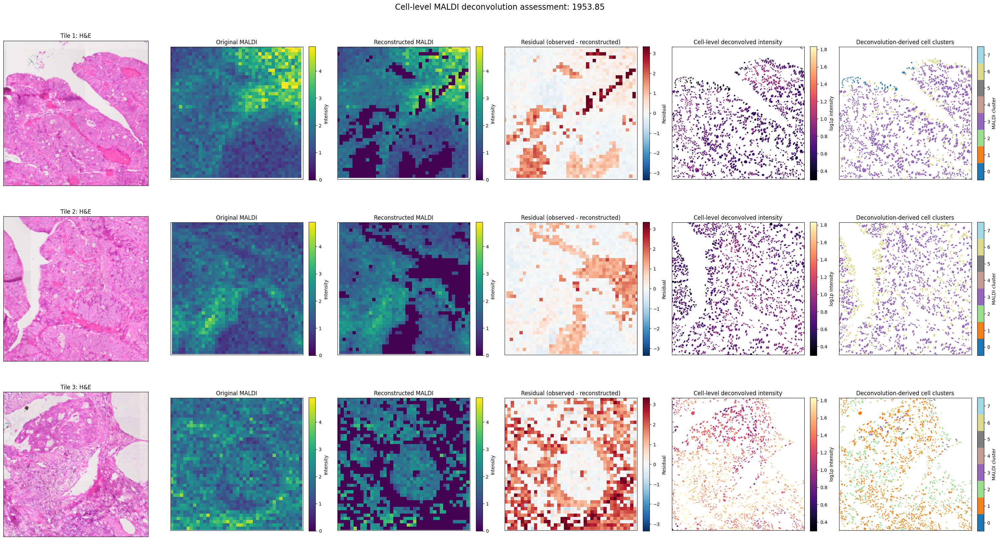

In [27]:
fig, axes = plot_deconvolution_tiles(
    sdata=sdata,
    A=A,
    Y=Y,
    X_deconv=X_deconv,
    feature_idx=50,
    n_tiles=3,
    tile_size=2000,
    random_state=10,
    pixel_size=50,
    image_key="he_fullres",
    image_scale="scale0",
    cell_intensity_transform="log1p",
    cluster_key="MALDI_cluster",
)

plt.show()

In [29]:
"""
deconvolution_validation.py

Quantify (1) how each MALDI pixel is split between cells / cell clusters and
(2) whether the inferred per-cell intensities are consistent with the pixels.

Expects the objects you already have:
    A          pixels x cells, row-normalised sparse weights
    Y          pixels x features MALDI matrix
    X_deconv, X_area, X_prior    cells x features
    groups     morphology group per cell
    morphology cell x descriptor DataFrame (extract_cell_morphology output)
    clusters   MALDI_cluster label per cell (from the deconvolved matrix)

Key point: A is geometric and fixed, so the pixel "proportions" are NOT learned.
What the model infers is the per-cell intensity. Validation therefore has two
parts: describe the geometry/signal split, and test the cell values with checks
that do not reduce to "A @ X reproduces Y" (which is underdetermined).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from sklearn.model_selection import KFold, GroupKFold, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans

EPS = 1e-12


# ----------------------------------------------------------------- helpers
def _codes(labels):
    cats, codes = np.unique(np.asarray(labels), return_inverse=True)
    return cats, codes


def _onehot(codes, k):
    n = len(codes)
    return sp.csr_matrix(
        (np.ones(n, np.float32), (np.arange(n), codes)), shape=(n, k)
    )


def _colwise_pearson(a, b):
    a = a - a.mean(0)
    b = b - b.mean(0)
    den = np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))
    return (a * b).sum(0) / np.where(den > 0, den, np.nan)


def _norm_entropy(P):
    p = P / (P.sum(1, keepdims=True) + EPS)
    h = -(p * np.log(p + EPS)).sum(1)
    return h / np.log(max(P.shape[1], 2))


def cell_purity(A):
    """Per cell: weighted mean share it holds in the pixels it touches
    (sum w^2 / sum w). 1 = cell has its pixels to itself; ->0 = always shared."""
    A = A.tocsr()
    mass = np.asarray(A.sum(0)).ravel()
    w2 = np.asarray(A.multiply(A).sum(0)).ravel()
    return w2 / np.maximum(mass, EPS), mass


def spatial_blocks(coords, block_size):
    """Integer block id per pixel for spatially blocked CV."""
    bx = np.floor(coords[:, 0] / block_size).astype(int)
    by = np.floor(coords[:, 1] / block_size).astype(int)
    return bx * 100003 + by


# ------------------------------------------- 1. How is each pixel divided?
def pixel_composition(A, X, clusters):
    """
    Per pixel: number of cells, effective number of cells, dominant cell share,
    and composition by cluster, both by AREA (A @ onehot) and by SIGNAL
    (each cell's share weighted by its inferred total intensity).
    """
    A = A.tocsr()
    cats, codes = _codes(clusters)
    H = _onehot(codes, len(cats))

    cell_signal = np.asarray(X, dtype=np.float32).sum(1)
    As = (A @ sp.diags(cell_signal)).tocsr()

    area_comp = (A @ H).toarray()
    sig_comp = (As @ H).toarray()
    sig_comp = sig_comp / (sig_comp.sum(1, keepdims=True) + EPS)

    row_sum = np.asarray(A.sum(1)).ravel()
    w2 = np.asarray(A.multiply(A).sum(1)).ravel()
    covered = row_sum > EPS
    dominant = A.max(axis=1).toarray().ravel() / np.maximum(row_sum, EPS)

    cols = [f"cluster_{c}" for c in cats]
    area_df = pd.DataFrame(area_comp, columns=cols)
    sig_df = pd.DataFrame(sig_comp, columns=cols)

    pix = pd.DataFrame({
        "covered": covered,
        "n_cells": np.diff(A.indptr),
        "eff_n_cells": np.where(covered, row_sum ** 2 / np.maximum(w2, EPS), 0),
        "dominant_cell_share": dominant,
        "cluster_entropy": _norm_entropy(area_comp),
        "dominant_cluster": np.array(cols)[area_comp.argmax(1)],
        "dominant_cluster_area_frac": area_comp.max(1),
        "dominant_cluster_signal_frac": sig_comp.max(1),
        "area_vs_signal_tvd": 0.5 * np.abs(area_comp - sig_comp).sum(1),
    })
    pix.loc[~covered, ["cluster_entropy", "dominant_cluster_area_frac",
                       "dominant_cluster_signal_frac", "area_vs_signal_tvd"]] = np.nan
    return pix, area_df, sig_df


def pixel_composition_summary(pix):
    p = pix[pix.covered]
    return pd.Series({
        "pixels covered": len(p),
        "median cells / pixel": p.n_cells.median(),
        "median effective cells / pixel": p.eff_n_cells.median(),
        "% pixels with a cell holding >50%": 100 * (p.dominant_cell_share > .5).mean(),
        "% pixels with a cell holding >80%": 100 * (p.dominant_cell_share > .8).mean(),
        "% pixels >80% one cluster (area)": 100 * (p.dominant_cluster_area_frac > .8).mean(),
        "median normalised cluster entropy": p.cluster_entropy.median(),
        "median area-vs-signal TVD": p.area_vs_signal_tvd.median(),
    })


# ------------------------- 1b. What morphology contributes to the split
def cell_share_drivers(A, X, morphology, max_cells=50000, seed=0):
    """
    Per cell: area mass (effective pixels it occupies), purity, and
    signal_enrichment = log2(signal share / area share).
    enrichment > 0: the cell takes more of its pixels' signal than its area implies.
    Random forest (held-out R2, permutation importance) + Spearman vs morphology.

    Run with X_deconv AND X_area. X_deconv is shrunk toward a morphology prior
    by construction, so the difference between the two = effect of the prior.
    """
    A = A.tocsr()
    X = np.asarray(X, dtype=np.float32)
    s = X.sum(1)
    As = A @ sp.diags(s)
    inv = 1.0 / (np.asarray(As.sum(1)).ravel() + EPS)
    sig_share = np.asarray((sp.diags(inv) @ As).sum(0)).ravel()
    purity, mass = cell_purity(A)

    df = morphology.copy()
    ok = mass > 1e-6
    targets = pd.DataFrame({
        "log_area_mass": np.log(np.maximum(mass, 1e-6)),
        "purity": purity,
        "signal_enrichment": np.clip(
            np.log2((sig_share + 1e-6) / (mass + 1e-6)), -5, 5),
    }, index=df.index)

    idx = np.flatnonzero(ok)
    rng = np.random.default_rng(seed)
    if len(idx) > max_cells:
        idx = rng.choice(idx, max_cells, replace=False)

    rows, r2s = [], {}
    feats = list(df.columns)
    for t in targets.columns:
        Xtr, Xte, ytr, yte = train_test_split(
            df.iloc[idx].to_numpy(), targets[t].iloc[idx].to_numpy(),
            test_size=0.3, random_state=seed)
        rf = RandomForestRegressor(
            n_estimators=150, min_samples_leaf=20, max_depth=10,
            n_jobs=-1, random_state=seed).fit(Xtr, ytr)
        r2s[t] = rf.score(Xte, yte)
        pi = permutation_importance(rf, Xte, yte, n_repeats=5,
                                    random_state=seed, n_jobs=-1)
        for j, f in enumerate(feats):
            rho = spearmanr(df[f].iloc[idx], targets[t].iloc[idx])[0]
            rows.append({"target": t, "feature": f,
                         "perm_importance": pi.importances_mean[j],
                         "spearman": rho, "heldout_R2": r2s[t]})
    cell_table = targets.assign(area_mass=mass, signal_share=sig_share)
    return pd.DataFrame(rows), cell_table


# ----------------------- 2a. Pixel reconstruction (necessary, not sufficient)
def reconstruction_table(A, Y, X, feature_names=None):
    A = A.tocsr()
    cov = np.diff(A.indptr) > 0
    Yc = Y[cov]
    Yh = np.asarray(A[cov] @ X, dtype=np.float32)
    ss_res = ((Yc - Yh) ** 2).sum(0)
    ss_tot = ((Yc - Yc.mean(0)) ** 2).sum(0)
    t = pd.DataFrame({
        "pearson": _colwise_pearson(Yc, Yh),
        "spearman": _colwise_pearson(rankdata(Yc, axis=0), rankdata(Yh, axis=0)),
        "R2": 1 - ss_res / np.maximum(ss_tot, EPS),
        "nRMSE": np.sqrt(ss_res / len(Yc)) / (Yc.std(0) + EPS),
        "total_bias": (Yh.sum(0) - Yc.sum(0)) / (Yc.sum(0) + EPS),
    }, index=feature_names if feature_names is not None else range(Y.shape[1]))
    return t


# ---------------- 2b. Held-out pixel prediction + morphology ablation
def _metrics(Yte, Yhat):
    r = _colwise_pearson(Yte, Yhat)
    nrmse = np.sqrt(((Yte - Yhat) ** 2).mean(0)) / (Yte.std(0) + EPS)
    return np.nanmedian(r), np.nanmedian(nrmse)


def heldout_pixel_cv(A, Y, groups, n_folds=5, n_features=40, lambda_prior=0.1,
                     max_iter=100, block_labels=None, seed=0):
    """
    Hide pixels, fit cell values on the rest, predict the hidden pixels with
    A_hidden @ X. The prior is rebuilt from training pixels only (no leakage).
    Variants isolate what is helping:
        area baseline | morphology prior only | deconv + {morphology,
        shuffled-morphology, global} prior | deconv with no prior term
    Metrics are stratified by how pure the held-out pixel is (dominant cell
    share): near-pure pixels are close to a direct single-cell test.
    Pass block_labels=spatial_blocks(coords, size) for the stricter spatial CV.
    """
    rng = np.random.default_rng(seed)
    A = A.tocsr()
    groups = np.asarray(groups)
    covered = np.flatnonzero(np.diff(A.indptr) > 0)
    feats = np.sort(rng.choice(Y.shape[1], min(n_features, Y.shape[1]),
                               replace=False))
    Yf = Y[:, feats]

    dominant = A.max(axis=1).toarray().ravel()
    labels = np.array(["shared (<0.5)", "mixed (0.5-0.8)", "near-pure (>0.8)"])
    bin_id = np.digitize(dominant, [0.5, 0.8])

    if block_labels is None:
        splits = KFold(n_folds, shuffle=True, random_state=seed).split(covered)
    else:
        splits = GroupKFold(n_folds).split(
            covered, groups=np.asarray(block_labels)[covered])

    out = []
    for fold, (tr, te) in enumerate(splits):
        tr, te = covered[tr], covered[te]
        A_tr, Y_tr, A_te, Y_te = A[tr], Yf[tr], A[te], Yf[te]
        mass = np.asarray(A_tr.sum(0)).ravel()
        fallback = Y_tr.mean(0)

        preds = {}
        Xa = area_weighted_baseline(A_tr, Y_tr)
        Xa[mass <= 1e-8] = fallback
        preds["area baseline"] = Xa

        flat = np.zeros_like(groups)
        for name, g in [("morphology", groups),
                        ("shuffled morphology", rng.permutation(groups)),
                        ("global", flat)]:
            prior = group_morphology_prior(A_tr, Y_tr, g)
            if name == "morphology":
                preds["morphology prior only"] = prior
            preds[f"deconv + {name} prior"] = gaussian_nonnegative_deconvolution(
                A_tr, Y_tr, prior, lambda_prior=lambda_prior, max_iter=max_iter)
        preds["deconv, no prior term"] = gaussian_nonnegative_deconvolution(
            A_tr, Y_tr, group_morphology_prior(A_tr, Y_tr, flat),
            lambda_prior=0.0, max_iter=max_iter)

        for name, Xhat in preds.items():
            Yh = np.asarray(A_te @ Xhat, dtype=np.float32)
            for lab, b in [("all", None)] + list(enumerate(labels)):
                m = np.ones(len(te), bool) if b is None else bin_id[te] == lab
                if m.sum() < 20:
                    continue
                r, e = _metrics(Y_te[m], Yh[m])
                out.append({"fold": fold, "variant": name,
                            "pixel_purity": "all" if b is None else labels[lab],
                            "median_r": r, "median_nRMSE": e,
                            "n_pixels": int(m.sum())})
    return pd.DataFrame(out)


def summarise_cv(cv):
    return (cv.groupby(["pixel_purity", "variant"])
              [["median_r", "median_nRMSE"]].agg(["mean", "std"]).round(3))


# ------------------------ 2c. Known-truth simulation (recovery per cell)
def synthetic_recovery(A, X_base, groups, cell_noise_sigma=0.5,
                       pixel_noise_frac=0.1, n_features=40,
                       lambda_prior=0.1, max_iter=100, seed=0):
    """
    Build a ground truth from the fitted values, add cell-specific lognormal
    variation the morphology prior cannot know about, simulate pixels through A,
    re-run the methods and score recovery per cell, binned by cell purity.
    cell_noise_sigma=0 is the optimistic case (truth is prior-like).
    """
    rng = np.random.default_rng(seed)
    A = A.tocsr()
    feats = np.sort(rng.choice(X_base.shape[1], min(n_features, X_base.shape[1]),
                               replace=False))
    Xb = np.asarray(X_base, np.float32)[:, feats]
    X_true = (Xb * np.exp(rng.normal(0, cell_noise_sigma, Xb.shape))
              ).astype(np.float32)
    Yc = np.asarray(A @ X_true)
    Y_sim = np.maximum(
        Yc + rng.normal(size=Yc.shape) * pixel_noise_frac * Yc.std(0), 0
    ).astype(np.float32)

    est = {"area baseline": area_weighted_baseline(A, Y_sim)}
    prior = group_morphology_prior(A, Y_sim, groups)
    est["morphology prior only"] = prior
    est["deconvolution"] = gaussian_nonnegative_deconvolution(
        A, Y_sim, prior, lambda_prior=lambda_prior, max_iter=max_iter)

    pur, mass = cell_purity(A)
    ok = mass > 1e-6
    bins = np.digitize(pur, [0.3, 0.6])
    names = np.array(["low purity (<0.3)", "medium (0.3-0.6)", "high (>0.6)"])
    rows = []
    for k, Xh in est.items():
        for b in [None, 0, 1, 2]:
            m = ok if b is None else ok & (bins == b)
            if m.sum() < 30:
                continue
            r = _colwise_pearson(X_true[m], Xh[m])
            nr = np.sqrt(((X_true[m] - Xh[m]) ** 2).mean(0)) / (X_true[m].std(0) + EPS)
            rows.append({"method": k,
                         "cell_purity": "all" if b is None else names[b],
                         "median_r_across_cells": np.nanmedian(r),
                         "median_nRMSE": np.nanmedian(nr), "n_cells": int(m.sum())})
    return pd.DataFrame(rows)


# --------------------- 3. Is the clustering morphology in disguise?
def cluster_cells(X, n_clusters=8, n_pcs=30, seed=42):
    """Same recipe as your clustering cell."""
    Xs = StandardScaler().fit_transform(np.log1p(np.maximum(X, 0)))
    Z = PCA(n_components=min(n_pcs, Xs.shape[1]), random_state=seed).fit_transform(Xs)
    return MiniBatchKMeans(n_clusters, random_state=seed, batch_size=4096,
                           n_init=10, max_iter=200).fit_predict(Z)


def clustering_confound_check(X_deconv, X_area, X_prior, groups,
                              clusters_deconv, n_clusters=8):
    """ARI / NMI between deconv clusters, area-baseline clusters, prior-only
    clusters and the morphology groups. If deconv clusters ~ morphology groups
    or ~ prior-only clusters, the prior is driving the result."""
    labs = {"deconv": np.asarray(clusters_deconv),
            "area baseline": cluster_cells(X_area, n_clusters),
            "prior only": cluster_cells(X_prior, n_clusters),
            "morphology groups": np.asarray(groups)}
    keys = list(labs)
    ari = pd.DataFrame(index=keys, columns=keys, dtype=float)
    nmi = ari.copy()
    for a in keys:
        for b in keys:
            ari.loc[a, b] = adjusted_rand_score(labs[a], labs[b])
            nmi.loc[a, b] = normalized_mutual_info_score(labs[a], labs[b])
    return ari.round(3), nmi.round(3)


def cluster_profile_agreement(A, Y, X, clusters, purity_thresh=0.7):
    """Cluster mean profile from cells vs from pixels that are >=thresh that
    cluster. Diagonal should dominate. NOT independent evidence (the clusters
    came from the same pixels); it is a consistency check."""
    A = A.tocsr()
    cats, codes = _codes(clusters)
    comp = (A @ _onehot(codes, len(cats))).toarray()
    P, C = [], []
    for k in range(len(cats)):
        pix = comp[:, k] >= purity_thresh
        P.append(Y[pix].mean(0) if pix.sum() >= 5 else np.full(Y.shape[1], np.nan))
        C.append(X[codes == k].mean(0))
    P, C = np.array(P), np.array(C)
    z = lambda M: (M - np.nanmean(M, 0)) / (np.nanstd(M, 0) + EPS)
    corr = z(P) @ z(C).T / Y.shape[1]
    lab = [f"cluster_{c}" for c in cats]
    return pd.DataFrame(corr, index=[f"pixels:{l}" for l in lab],
                        columns=[f"cells:{l}" for l in lab]).round(3)


# ---------------------------------------------------------------- plots
def _spatial(ax, coords, v, title, cmap="viridis", vmin=None, vmax=None, s=2):
    sc = ax.scatter(coords[:, 0], coords[:, 1], c=v, s=s, cmap=cmap, vmin=vmin,
                    vmax=vmax, linewidths=0, rasterized=True)
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.set_title(title)
    plt.colorbar(sc, ax=ax, shrink=0.7)


def plot_pixel_composition(pix, area_df, sig_df, coords=None, seed=0):
    p = pix[pix.covered]
    fig, ax = plt.subplots(2, 3, figsize=(18, 10))
    ax[0, 0].hist(p.n_cells, bins=np.arange(0, p.n_cells.max() + 2) - .5)
    ax[0, 0].set(title="Cells overlapping each pixel", xlabel="n cells")
    ax[0, 1].hist(p.dominant_cell_share, bins=40)
    ax[0, 1].set(title="Share held by the largest cell in a pixel",
                 xlabel="dominant cell share")
    ax[0, 2].hist(p.cluster_entropy.dropna(), bins=40)
    ax[0, 2].set(title="Cluster mixing per pixel (0 = single cluster)",
                 xlabel="normalised entropy")
    if coords is not None:
        c = coords[pix.covered.to_numpy()]
        _spatial(ax[1, 0], c, p.dominant_cluster_area_frac,
                 "Dominant-cluster fraction (area)", "magma", 0, 1)
        _spatial(ax[1, 1], c, p.cluster_entropy, "Cluster entropy", "viridis", 0, 1)
    rng = np.random.default_rng(seed)
    cov = np.flatnonzero(pix.covered.to_numpy())
    sel = rng.choice(cov, min(20000, len(cov)), replace=False)
    ax[1, 2].hexbin(area_df.to_numpy()[sel].ravel(), sig_df.to_numpy()[sel].ravel(),
                    gridsize=50, bins="log", mincnt=1)
    ax[1, 2].plot([0, 1], [0, 1], "r--", lw=1)
    ax[1, 2].set(title="Cluster share per pixel: area vs signal",
                 xlabel="area share", ylabel="signal share")
    plt.tight_layout()
    return fig


def plot_example_pixels(area_df, pix, n=40, seed=0):
    rng = np.random.default_rng(seed)
    cov = np.flatnonzero(pix.covered.to_numpy())
    sel = rng.choice(cov, min(n, len(cov)), replace=False)
    sub = area_df.iloc[sel]
    sub = sub.loc[sub.max(1).sort_values().index]
    fig, ax = plt.subplots(figsize=(14, 4))
    sub.reset_index(drop=True).plot.bar(stacked=True, ax=ax, width=0.9,
                                        colormap="tab20")
    ax.set(xlabel="example pixels (sorted by purity)", ylabel="area fraction",
           title="Cluster composition of individual MALDI pixels")
    ax.set_xticks([]); ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
    plt.tight_layout()
    return fig


def plot_drivers(drivers):
    ts = drivers.target.unique()
    fig, ax = plt.subplots(1, len(ts), figsize=(5 * len(ts), 4))
    ax = np.atleast_1d(ax)
    for a, t in zip(ax, ts):
        d = drivers[drivers.target == t].sort_values("perm_importance")
        a.barh(d.feature, d.perm_importance)
        a.set_title(f"{t}\nheld-out R2 = {d.heldout_R2.iloc[0]:.2f}")
        a.set_xlabel("permutation importance")
    plt.tight_layout()
    return fig


def plot_reconstruction(A, Y, X, table, seed=0):
    A = A.tocsr()
    cov = np.diff(A.indptr) > 0
    yt = Y[cov].sum(1)
    yh = np.asarray(A[cov] @ X).sum(1)
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].hexbin(yt, yh, gridsize=60, bins="log", mincnt=1)
    lim = [0, max(yt.max(), yh.max())]
    ax[0].plot(lim, lim, "r--", lw=1)
    ax[0].set(title=f"Total signal per pixel (r={np.corrcoef(yt, yh)[0, 1]:.3f})",
              xlabel="observed", ylabel="A @ X")
    ax[1].hist(table.pearson.dropna(), bins=30)
    ax[1].set(title="Per-feature pixel correlation", xlabel="Pearson r")
    ax[2].hist(table.nRMSE.dropna(), bins=30)
    ax[2].set(title="Per-feature nRMSE (RMSE / SD)", xlabel="nRMSE")
    plt.tight_layout()
    return fig


def plot_cv(cv):
    s = cv.groupby(["pixel_purity", "variant"])[["median_r", "median_nRMSE"]].mean()
    order = ["all", "shared (<0.5)", "mixed (0.5-0.8)", "near-pure (>0.8)"]
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    for a, m in zip(ax, ["median_r", "median_nRMSE"]):
        s[m].unstack("pixel_purity").reindex(columns=[o for o in order
            if o in s.index.get_level_values(0)]).plot.bar(ax=a)
        a.set_title(f"Held-out pixels: {m}"); a.set_xlabel("")
        a.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    return fig


def plot_synthetic(syn):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for a, m in zip(ax, ["median_r_across_cells", "median_nRMSE"]):
        syn.pivot(index="cell_purity", columns="method", values=m).plot.bar(ax=a)
        a.set_title(f"Known-truth recovery: {m}")
        a.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ driver
def run_validation(sdata, A, Y, X_deconv, X_area, X_prior, groups, morphology,
                   clusters, maldi_key="maldi_adata", spatial_key="spatial",
                   n_features=40, spatial_cv_block=None, do_cv=True, do_synth=True):
    """
    spatial_cv_block: block size in the same units as MALDI pixel coordinates
                      for spatially blocked CV (recommended); None = random CV.
    """
    maldi = sdata.tables[maldi_key]
    coords = maldi.obsm[spatial_key] if spatial_key in maldi.obsm else None
    names = list(maldi.var_names)
    R = {}

    print("=== 1. Pixel composition ===")
    pix, area_df, sig_df = pixel_composition(A, X_deconv, clusters)
    R.update(pix=pix, area_comp=area_df, signal_comp=sig_df)
    R["pixel_summary"] = pixel_composition_summary(pix)
    print(R["pixel_summary"].round(3))
    R["fig_pixels"] = plot_pixel_composition(pix, area_df, sig_df, coords)
    R["fig_examples"] = plot_example_pixels(area_df, pix)

    print("\n=== 1b. What drives each cell's share ===")
    d_dec, cell_tab = cell_share_drivers(A, X_deconv, morphology)
    d_area, _ = cell_share_drivers(A, X_area, morphology)
    d_dec["X"], d_area["X"] = "deconv", "area baseline"
    R["drivers"] = pd.concat([d_dec, d_area])
    R["cell_table"] = cell_tab
    print(R["drivers"].pivot_table(index=["target", "feature", "X"],
          values=["perm_importance", "spearman"]).round(3))
    R["fig_drivers"] = plot_drivers(d_dec)

    print("\n=== 2a. Pixel reconstruction ===")
    R["recon"] = {n: reconstruction_table(A, Y, X, names)
                  for n, X in [("area baseline", X_area),
                               ("morphology prior", X_prior),
                               ("deconvolution", X_deconv)]}
    print(pd.DataFrame({k: v.median() for k, v in R["recon"].items()}).round(3))
    R["fig_recon"] = plot_reconstruction(A, Y, X_deconv, R["recon"]["deconvolution"])

    if do_cv:
        print("\n=== 2b. Held-out pixels / ablation ===")
        blocks = (spatial_blocks(coords, spatial_cv_block)
                  if (spatial_cv_block and coords is not None) else None)
        R["cv"] = heldout_pixel_cv(A, Y, groups, n_features=n_features,
                                   block_labels=blocks)
        R["cv_summary"] = summarise_cv(R["cv"])
        print(R["cv_summary"])
        R["fig_cv"] = plot_cv(R["cv"])

    if do_synth:
        print("\n=== 2c. Known-truth simulation ===")
        R["synthetic"] = synthetic_recovery(A, X_deconv, groups,
                                            n_features=n_features)
        print(R["synthetic"].round(3).to_string(index=False))
        R["fig_synth"] = plot_synthetic(R["synthetic"])

    print("\n=== 3. Is clustering driven by the prior? ===")
    ari, nmi = clustering_confound_check(X_deconv, X_area, X_prior, groups, clusters)
    R["ari"], R["nmi"] = ari, nmi
    print("ARI:\n", ari)
    R["profile_agreement"] = cluster_profile_agreement(A, Y, X_deconv, clusters)
    print("\nPixel-vs-cell cluster profile correlation:\n", R["profile_agreement"])
    return R

=== 1. Pixel composition ===
pixels covered                       80467.000
median cells / pixel                     3.000
median effective cells / pixel           2.132
% pixels with a cell holding >50%       53.103
% pixels with a cell holding >80%       31.305
% pixels >80% one cluster (area)        81.149
median normalised cluster entropy        0.000
median area-vs-signal TVD                0.000
dtype: float64

=== 1b. What drives each cell's share ===


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11

                                              perm_importance  spearman
target            feature      X                                       
log_area_mass     area         area baseline           -0.000     0.239
                               deconv                  -0.000     0.239
                  aspect_ratio area baseline           -0.000     0.097
                               deconv                  -0.000     0.097
                  circularity  area baseline            0.078    -0.142
                               deconv                   0.078    -0.142
                  perimeter    area baseline            0.145     0.271
                               deconv                   0.145     0.271
                  solidity     area baseline            0.021    -0.045
                               deconv                   0.021    -0.045
purity            area         area baseline           -0.000     0.147
                               deconv                  -0.000   

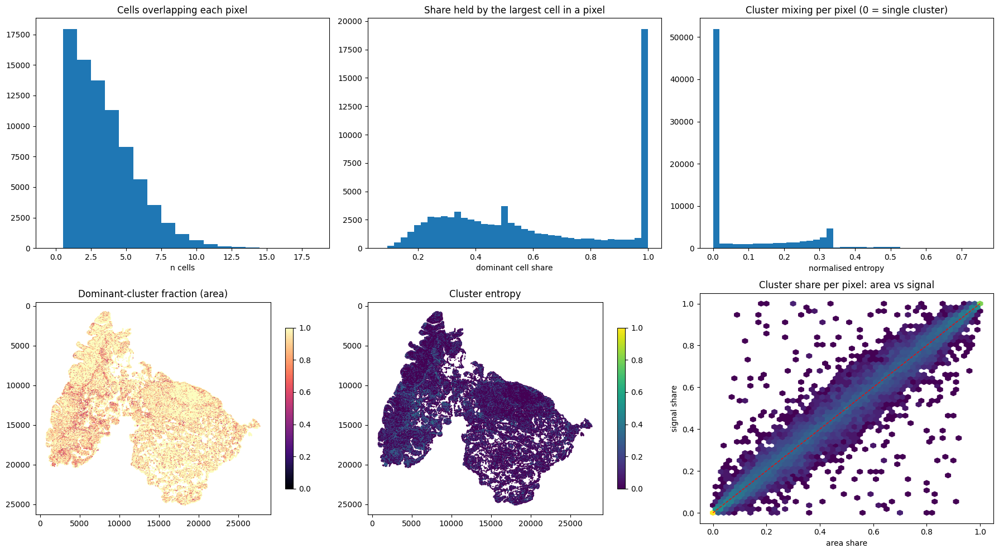

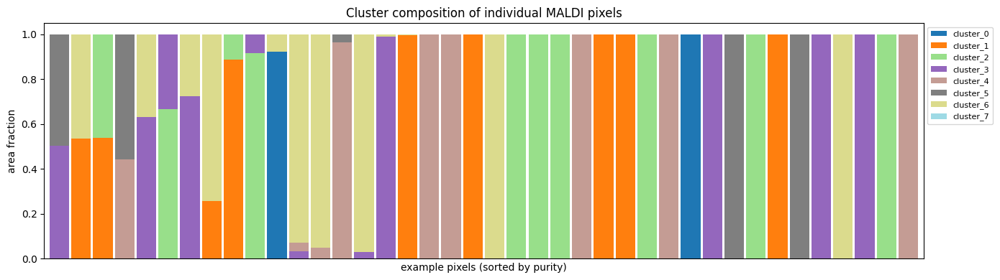

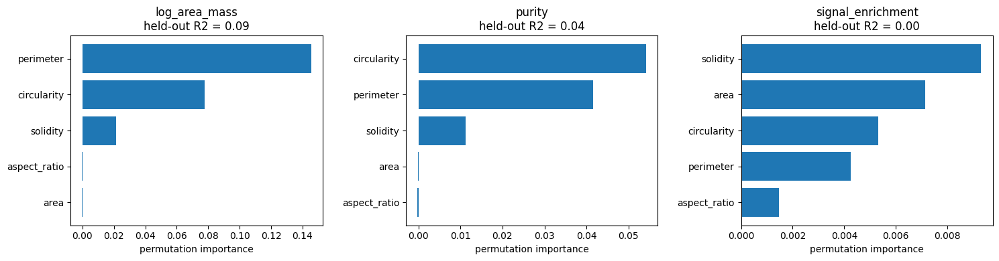

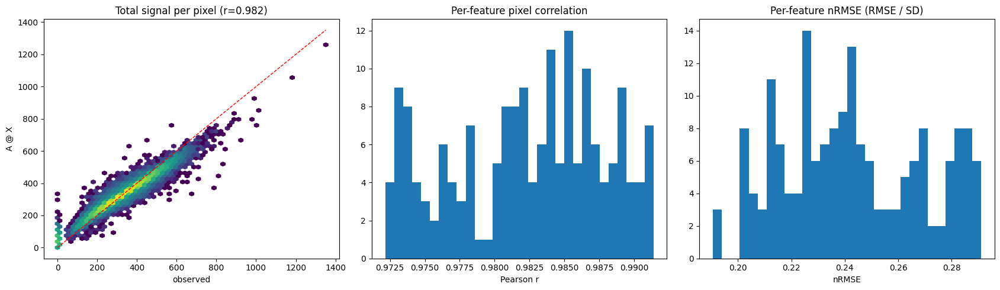

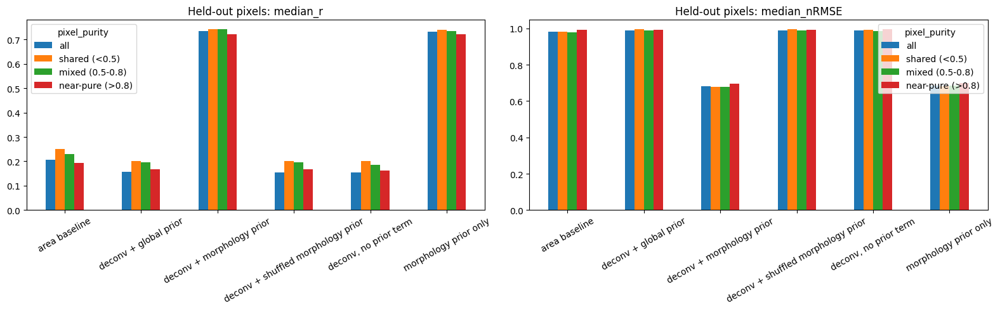

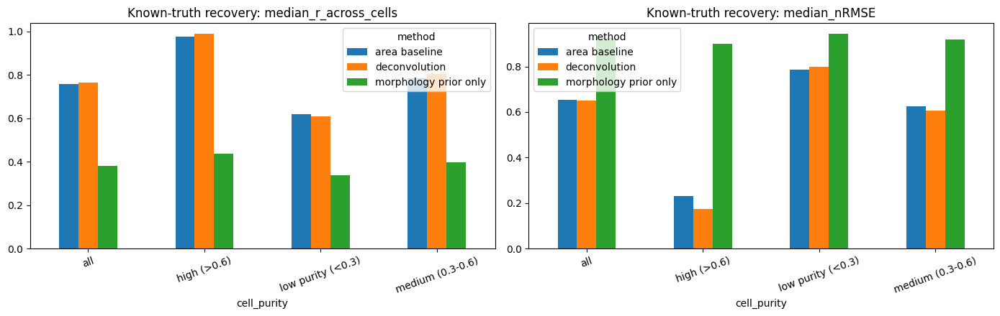

In [32]:
R = run_validation(
    sdata, A, Y, X_deconv, X_area, X_prior,
    clusters, morphology, cell_adata.obs["MALDI_cluster"].to_numpy(),
    spatial_cv_block=500,   # block size in MALDI pixel-coordinate units
)

In [39]:
"""
deconvolution_spatial_plots.py

Zoomed spatial comparisons on the tissue:
  plot_cluster_roi            H&E | cell polygons by cluster (+MALDI pixel grid) | overlay
  plot_intensity_roi          H&E | observed pixels | A@X reconstruction
                              cells (area) | cells (deconv) | pixel residual
  plot_global_feature_maps    whole-slide observed / reconstructed / residual / cells
  plot_cell_vs_pixel_scatter  cell estimate vs the pixel it mostly owns
  suggest_rois                picks informative regions (mixed / typical / pure)

Assumes cell coordinates, cell polygons, MALDI pixel coordinates and the H&E
image share one pixel coordinate system (as in your earlier overlay plot).
Because A is row-normalised, cell values and pixel values are in the same
units, so they can share a colour scale.
"""
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors
from matplotlib.collections import PolyCollection
from scipy.spatial import cKDTree


# ----------------------------------------------------------------- helpers
def _feat(M, feature, names=None):
    M = np.asarray(M)
    if isinstance(feature, str):
        if feature == "total":
            return M.sum(1)
        return M[:, list(names).index(feature)]
    return M[:, int(feature)]


def pixel_pitch(coords):
    d, _ = cKDTree(coords).query(coords, k=2)
    return float(np.median(d[:, 1]))


def _pixel_polys(coords, pitch, idx):
    h = pitch / 2.0
    c = coords[idx]
    off = np.array([[-h, -h], [h, -h], [h, h], [-h, h]])
    return c[:, None, :] + off[None, :, :]


def _in_roi(xy, roi, pad=0.0):
    x0, y0, x1, y1 = roi
    return ((xy[:, 0] >= x0 - pad) & (xy[:, 0] <= x1 + pad) &
            (xy[:, 1] >= y0 - pad) & (xy[:, 1] <= y1 + pad))


def get_he_crop(sdata, roi, image_key="he_image"):
    """Crop the H&E lazily (DataArray with dims c,y,x) and return HxWx3."""
    x0, y0, x1, y1 = [int(v) for v in roi]
    img = sdata.images[image_key]
    x0, y0 = max(x0, 0), max(y0, 0)
    arr = img.isel(y=slice(y0, y1), x=slice(x0, x1))
    arr = np.asarray(arr.compute().values if hasattr(arr, "compute") else arr.values)
    if arr.ndim == 3 and arr.shape[0] in (3, 4):
        arr = np.moveaxis(arr, 0, -1)
    return arr[..., :3]


def _setup(ax, roi, title):
    x0, y0, x1, y1 = roi
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])


def _show_he(ax, sdata, roi, image_key):
    x0, y0, x1, y1 = roi
    ax.imshow(get_he_crop(sdata, roi, image_key), extent=(x0, x1, y1, y0))


def _pix_collection(ax, polys, values=None, norm=None, cmap="viridis",
                    edge="none", lw=0.3):
    if values is None:
        pc = PolyCollection(polys, facecolors="none", edgecolors="k", linewidths=lw)
    else:
        pc = PolyCollection(polys, array=values, cmap=cmap, norm=norm,
                            edgecolors=edge, linewidths=lw)
    ax.add_collection(pc)
    return pc


def _cells(ax, gdf, values=None, norm=None, cmap="viridis", colors=None,
           alpha=1.0, lw=0.15):
    if colors is None:
        colors = plt.get_cmap(cmap)(norm(values))
    gdf.plot(ax=ax, color=colors, edgecolor="k", linewidth=lw, alpha=alpha)


def _cell_context(sdata, cell_key, shapes_key, spatial_key, roi):
    cells = sdata.tables[cell_key]
    cxy = np.asarray(cells.obsm[spatial_key])
    shapes = sdata.shapes[shapes_key].reindex(cells.obs_names)
    idx = np.flatnonzero(_in_roi(cxy, roi))
    return cells, cxy, shapes, idx


# ---------------------------------------------------------- ROI selection
def suggest_rois(pix, coords, size, min_frac=0.5):
    """Return {'mixed','typical','pure': (x0,y0,x1,y1)} from the pixel table
    produced by dv.pixel_composition (needs 'cluster_entropy', 'covered')."""
    p = pix.reset_index(drop=True)
    ok = p.covered.to_numpy()
    gx = np.floor(coords[:, 0] / size).astype(int)
    gy = np.floor(coords[:, 1] / size).astype(int)
    df = p.assign(gx=gx, gy=gy)[ok]
    g = df.groupby(["gx", "gy"]).cluster_entropy.agg(["mean", "size"])
    g = g[g["size"] >= min_frac * g["size"].max()].sort_values("mean")
    pick = {"pure": g.index[0], "typical": g.index[len(g) // 2],
            "mixed": g.index[-1]}
    return {k: (a * size, b * size, (a + 1) * size, (b + 1) * size)
            for k, (a, b) in pick.items()}


# -------------------------------------------- clustering vs H&E (zoomed)
def plot_cluster_roi(sdata, clusters, roi, cell_key="cell_adata",
                     shapes_key="cell_segmentation", image_key="he_image",
                     maldi_key="maldi_adata", spatial_key="spatial",
                     cmap="tab20", pixel_grid=True, title=""):
    cells, cxy, shapes, idx = _cell_context(sdata, cell_key, shapes_key,
                                            spatial_key, roi)
    codes = np.unique(np.asarray(clusters), return_inverse=True)[1]
    # same colour mapping as scatter(c=labels, cmap='tab20')
    col = plt.get_cmap(cmap)(codes / max(codes.max(), 1))[idx]
    sub = shapes.iloc[idx]

    pxy = np.asarray(sdata.tables[maldi_key].obsm[spatial_key])
    pitch = pixel_pitch(pxy)
    pidx = np.flatnonzero(_in_roi(pxy, roi, pad=pitch))
    polys = _pixel_polys(pxy, pitch, pidx)

    fig, ax = plt.subplots(1, 3, figsize=(20, 7))
    _show_he(ax[0], sdata, roi, image_key); _setup(ax[0], roi, "H&E")
    _cells(ax[1], sub, colors=col, lw=0.2)
    if pixel_grid:
        _pix_collection(ax[1], polys, lw=0.5)
    _setup(ax[1], roi, "Cells by deconvolved-MALDI cluster (+ pixel grid)")
    _show_he(ax[2], sdata, roi, image_key)
    _cells(ax[2], sub, colors=col, alpha=0.5, lw=0)
    _setup(ax[2], roi, "Overlay")
    fig.suptitle(title, y=0.98)
    plt.tight_layout()
    return fig


# --------------------- cell intensity vs pixel intensity (zoomed, same scale)
def plot_intensity_roi(sdata, A, Y, X_area, X_deconv, feature, roi,
                       cell_key="cell_adata", shapes_key="cell_segmentation",
                       image_key="he_image", maldi_key="maldi_adata",
                       spatial_key="spatial", cmap="viridis", title=""):
    maldi = sdata.tables[maldi_key]
    names = list(maldi.var_names)
    cells, cxy, shapes, idx = _cell_context(sdata, cell_key, shapes_key,
                                            spatial_key, roi)
    pxy = np.asarray(maldi.obsm[spatial_key])
    pitch = pixel_pitch(pxy)
    pidx = np.flatnonzero(_in_roi(pxy, roi, pad=pitch))
    polys = _pixel_polys(pxy, pitch, pidx)

    y_obs = _feat(Y, feature, names)
    y_rec = _feat(np.asarray(A @ X_deconv), feature, names)
    cov = np.diff(A.tocsr().indptr) > 0
    y_res = np.where(cov, y_obs - y_rec, np.nan)
    xa = _feat(X_area, feature, names)
    xd = _feat(X_deconv, feature, names)

    vals = y_obs[pidx]
    vmin, vmax = np.nanpercentile(vals, [1, 99])
    norm = mcolors.Normalize(vmin, vmax)
    rlim = np.nanpercentile(np.abs(y_res[pidx]), 99) or 1.0
    rnorm = mcolors.Normalize(-rlim, rlim)
    sub = shapes.iloc[idx]

    fig, ax = plt.subplots(2, 3, figsize=(21, 14))
    _show_he(ax[0, 0], sdata, roi, image_key)
    _pix_collection(ax[0, 0], polys, lw=0.4)
    _setup(ax[0, 0], roi, "H&E + MALDI pixel grid")

    _pix_collection(ax[0, 1], polys, y_obs[pidx], norm, cmap)
    _setup(ax[0, 1], roi, "Observed MALDI pixels")
    _pix_collection(ax[0, 2], polys, y_rec[pidx], norm, cmap)
    _setup(ax[0, 2], roi, "Reconstruction A @ X_deconv (pixel level)")

    _cells(ax[1, 0], sub, xa[idx], norm, cmap)
    _setup(ax[1, 0], roi, "Cells: area-weighted baseline")
    _cells(ax[1, 1], sub, xd[idx], norm, cmap)
    _pix_collection(ax[1, 1], polys, lw=0.4)
    _setup(ax[1, 1], roi, "Cells: deconvolved (+ pixel grid)")
    pc = _pix_collection(ax[1, 2], polys, y_res[pidx], rnorm, "RdBu_r")
    _setup(ax[1, 2], roi, "Residual (observed - reconstructed)")

    for a, n, c in [(ax[0, 1], norm, cmap), (ax[0, 2], norm, cmap),
                    (ax[1, 0], norm, cmap), (ax[1, 1], norm, cmap),
                    (ax[1, 2], rnorm, "RdBu_r")]:
        plt.colorbar(cm.ScalarMappable(n, c), ax=a, shrink=0.6)

    m = np.isfinite(y_res[pidx])
    r = np.corrcoef(y_obs[pidx][m], y_rec[pidx][m])[0, 1] if m.sum() > 2 else np.nan
    label = feature if isinstance(feature, str) else names[int(feature)]
    fig.suptitle(f"{title}  feature: {label}   ROI pixel r = {r:.3f}", y=0.99)
    plt.tight_layout()
    return fig


# --------------------------------------------------------- whole slide
def plot_global_feature_maps(sdata, A, Y, X_deconv, feature,
                             cell_key="cell_adata", maldi_key="maldi_adata",
                             spatial_key="spatial", cmap="viridis", s=1.5):
    maldi = sdata.tables[maldi_key]
    names = list(maldi.var_names)
    pxy = np.asarray(maldi.obsm[spatial_key])
    cxy = np.asarray(sdata.tables[cell_key].obsm[spatial_key])
    y = _feat(Y, feature, names)
    yh = _feat(np.asarray(A @ X_deconv), feature, names)
    xd = _feat(X_deconv, feature, names)
    cov = np.diff(A.tocsr().indptr) > 0
    res = np.where(cov, y - yh, np.nan)
    vmin, vmax = np.nanpercentile(y, [1, 99])
    rl = np.nanpercentile(np.abs(res), 99)

    fig, ax = plt.subplots(2, 2, figsize=(16, 15))
    panels = [(ax[0, 0], pxy, y, "Observed MALDI pixels", cmap, vmin, vmax),
              (ax[0, 1], pxy, yh, "Reconstruction A @ X", cmap, vmin, vmax),
              (ax[1, 0], pxy, res, "Residual", "RdBu_r", -rl, rl),
              (ax[1, 1], cxy, xd, "Deconvolved cell values", cmap, vmin, vmax)]
    for a, xy, v, t, c, lo, hi in panels:
        sc = a.scatter(xy[:, 0], xy[:, 1], c=v, s=s, cmap=c, vmin=lo, vmax=hi,
                       linewidths=0, rasterized=True)
        a.invert_yaxis(); a.set_aspect("equal"); a.set_title(t)
        plt.colorbar(sc, ax=a, shrink=0.6)
    label = feature if isinstance(feature, str) else names[int(feature)]
    fig.suptitle(f"feature: {label}", y=0.99)
    plt.tight_layout()
    return fig


# ------------------------- cell estimate vs the pixel the cell mostly owns
def plot_cell_vs_pixel_scatter(A, Y, X_area, X_deconv, feature, names=None,
                               pure_thresh=0.6, shared_thresh=0.3):
    """
    For each cell take the pixel where it has the largest weight. Compare the
    cell estimate with that pixel's observed value, separately for cells that
    dominate that pixel (pure) and cells that hold little of it (shared).
    Pure cells ~ direct check. Note the pixel is also in the fit, so this is a
    sanity check rather than held-out evidence.
    """
    A = A.tocsr()
    dom_pix = np.asarray(A.argmax(axis=0)).ravel()
    dom_w = A.max(axis=0).toarray().ravel()
    y = _feat(Y, feature, names)[dom_pix]
    sets = [(f"pure cells (share > {pure_thresh})", dom_w > pure_thresh),
            (f"shared cells (share < {shared_thresh})", dom_w < shared_thresh)]
    fig, ax = plt.subplots(2, 2, figsize=(12, 11))
    for j, (ttl, m) in enumerate(sets):
        for i, (nm, X) in enumerate([("area baseline", X_area),
                                     ("deconvolved", X_deconv)]):
            x = _feat(X, feature, names)
            a = ax[j, i]
            a.hexbin(y[m], x[m], gridsize=50, bins="log", mincnt=1)
            lim = [0, max(np.nanmax(y[m]), np.nanmax(x[m]))]
            a.plot(lim, lim, "r--", lw=1)
            r = np.corrcoef(y[m], x[m])[0, 1]
            a.set(title=f"{nm}: {ttl}\nr = {r:.3f}, n = {int(m.sum())}",
                  xlabel="observed value of the cell's dominant pixel",
                  ylabel="cell estimate")
    plt.tight_layout()
    return fig

IndexError: too many indices for array: array is 0-dimensional, but 1 were indexed

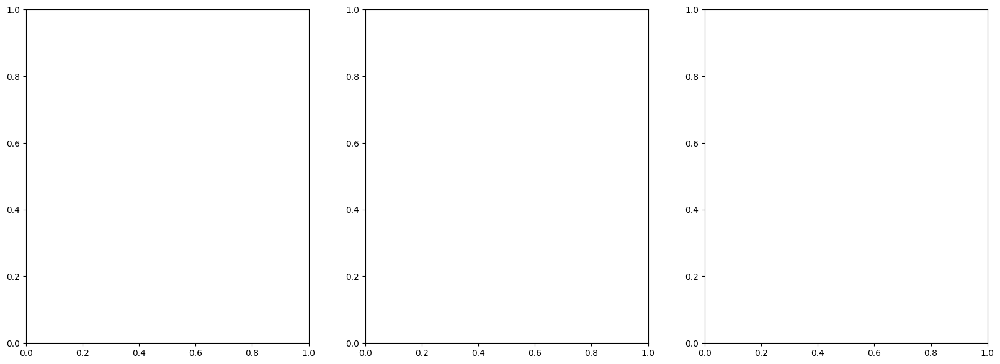

In [40]:
pix, area_comp, sig_comp = pixel_composition(A, X_deconv, clusters)
rois = suggest_rois(pix, sdata["maldi_adata"].obsm["spatial"], size=1500)  # mixed / typical / pure

for name, roi in rois.items():
    plot_cluster_roi(sdata, clusters, roi, title=name, image_key="he_fullres")
    plot_intensity_roi(sdata, A, Y, X_area, X_deconv, feature="total", roi=roi, title=name, image_key="he_fullres")

plot_global_feature_maps(sdata, A, Y, X_deconv, feature="total")
plot_cell_vs_pixel_scatter(A, Y, X_area, X_deconv, feature="total",
                           names=list(sdata.tables["maldi_adata"].var_names))

In [26]:
sdata.write("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_decon.zarr")


INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_decon.zarr). Please see   
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr the new file path:  
         /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_decon.zarr                                  


In [29]:
from napari_spatialdata import Interactive

Interactive(sdata)

2026-11-04 13:59:25.275 | WARNING  | napari_spatialdata._viewer:__init__:57 - Due to Shift-L being used as shortcut in napari, it is being deprecated and might not link a new layer to an existing SpatialData object in the viewer. Please use ⌘-L on MacOS or else Ctrl-L.


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
2026-11-04 14:01:04.124 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-04 14:01:04.126 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.p